#**1. Setup and Data Loading**




**Note :**

**Data Source & Validation Summary**

Primary Source: Data was originally sourced from [echr-opendata.eu](https://). The site provides several kinds of pre-processed data. For this project, we use *"unstructured cases in JSON".*

**Current Status**

While the primary source website currently returns a "502 Bad Gateway" error, a stable local version of the dataset was successfully archived as of 9 February 2026.

**Temporal Scope**

The dataset provides comprehensive coverage of Article 8 cases from the Court's inception through 2023.

**Integrity Verification**

To ensure the reliability of the JSON data, random sampling was conducted to compare the archived local files against the official HUDOC (ECHR) database.  Cross-referencing confirmed that the text sections and metadata in the JSON files are **identical** to the official records, validating the dataset's accuracy for high-importance legal analysis.

*Other documentation:* [Github](https://github.com/echr-od/ECHR-OD_process)

In [ ]:
import pandas as pd
import numpy as np
import re
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import gdown
import os
# ── Aesthetic defaults ──────────────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted')
PALETTE = {'Violation': '#d62728', 'No Violation': '#2ca02c', 'Only Mentioning': '#aec7e8'}

COUNTRY_PALETTE = {
    'RUS': '#1f77b4',  # Russia - Deep Blue
    'UKR': '#ff7f0e',  # Ukraine - Bright Orange
    'ROU': '#2ca02c',  # Romania - Forest Green
    'POL': '#d62728',  # Poland - Crimson
    'HRV': '#9467bd',  # Croatia - Royal Purple
    'BGR': '#8c564b',  # Bulgaria - Earth Brown
    'TUR': '#e377c2',  # Turkey - Pink/Magenta
    'HUN': '#7f7f7f',  # Hungary - Slate Grey
    'NOR': '#bcbd22',  # Norway - Olive Gold
    'DEU': '#17becf'   # Germany - Teal Blue
}

sns.set_theme(style='whitegrid', palette='muted')

print('Libraries loaded successfully.')

Libraries loaded successfully.


In [ ]:
# ── Step 1: Download the raw dataset from Google Drive ──────────────────────
# The file ID comes from the shared Drive link and never changes.
# Anyone with access to the shared folder can run this cell as-is,
# with no filepaths to update.
FILE_ID = '10DvcRnmAjxTPXo4C4JGE7E9UPEoZxNQX'
url = f'https://drive.google.com/uc?id={FILE_ID}'
gdown.download(url, 'echr_raw.json', quiet=False, fuzzy=True)

# ── Step 2: Verify the file downloaded correctly ─────────────────────────────
file_size_mb = os.path.getsize('echr_raw.json') / (1024 * 1024)
print(f'Downloaded file size: {file_size_mb:.1f} MB')
if file_size_mb < 1:
    print('WARNING: File is too small — download may have failed.')
else:
    print('File size looks correct, proceeding...')

# ── Step 3: Load into a DataFrame ───────────────────────────────────────────
df_raw = pd.read_json('echr_raw.json')
print(f'Raw dataset loaded: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns')

# ── Step 4: Parse dates (dayfirst=True for DD/MM/YYYY format) ───────────────
df_raw['date_dt'] = pd.to_datetime(df_raw['judgementdate'], dayfirst=True, errors='coerce')
df_raw['year'] = df_raw['date_dt'].dt.year

# ── Step 5: Filter for Article 8 cases (2010–2023) ──────────────────────────
def mentions_article_8(val):
    """Return True if '8' appears in the article list or string for this case."""
    if isinstance(val, list):
        return '8' in [str(x).strip() for x in val]
    if isinstance(val, str):
        return '8' in [x.strip() for x in val.replace(',', ';').split(';')]
    return False

art_col = 'article' if 'article' in df_raw.columns else '__articles'
mask_art8 = df_raw[art_col].apply(mentions_article_8)
mask_year = df_raw['year'].between(2010, 2023)

df_art8 = df_raw[mask_art8 & mask_year][[
    'itemid', 'docname', 'year', 'respondent',
    art_col, '__conclusion', 'conclusion','content','importance','originatingbody_name'
]].copy()

# Rename columns for clarity
df_art8 = df_art8.rename(columns={
    'docname':       'title',
    art_col:         'article_numbers',
    '__conclusion':  'conclusion_text',
    'content':       'full_text',
    'respondent' : 'country',
    'originatingbody_name': 'court',
    'conclusion' : 'outcome'
})

print(f'Article 8 cases (2010-2023): {len(df_art8):,}')
display(df_art8.head())

Downloading...
From (original): https://drive.google.com/uc?id=10DvcRnmAjxTPXo4C4JGE7E9UPEoZxNQX
From (redirected): https://drive.google.com/uc?id=10DvcRnmAjxTPXo4C4JGE7E9UPEoZxNQX&confirm=t&uuid=74e961e4-95c6-4d45-a03e-3edb13d19223
To: /content/echr_raw.json
100%|██████████| 1.09G/1.09G [00:11<00:00, 95.2MB/s]


Downloaded file size: 1038.3 MB
File size looks correct, proceeding...
Raw dataset loaded: 16,096 rows x 39 columns
Article 8 cases (2010-2023): 1,321


,itemid,title,year,country,article_numbers,conclusion_text,outcome,full_text,importance,court
2,001-178343,CASE OF ZUBKOV AND OTHERS v. RUSSIA,2017,RUS,"[41, 8, 5, 35, 37]",Preliminary objections dismissed (Art. 35) Adm...,"[{'details': ['Art. 35'], 'element': 'Prelimin...","{'001-178343.docx': [{'content': 'PROCEDURE', ...",3,Third Section
4,001-112534,CASE OF TYAGUNOVA v. RUSSIA,2012,RUS,"[3, 8]",Violation of Article 3 - Prohibition of tortur...,"[{'article': '3', 'base_article': '3', 'detail...","{'001-112534.docx': [{'content': 'PROCEDURE', ...",4,First Section
13,001-106968,CASE OF S.I. v. SLOVENIA,2011,SVN,"[8, 41]",Remainder inadmissible;Violation of Art. 8;Non...,"[{'element': 'Remainder inadmissible', 'type':...","{'001-106968.docx': [{'content': 'PROCEDURE', ...",3,Fith Section
15,001-210414,CASE OF Y.S. AND O.S. v. RUSSIA,2021,RUS,"[8, 41]",Violation of Article 8 - Right to respect for ...,"[{'article': '8', 'base_article': '8', 'detail...",{'001-210414.docx': [{'content': 'INTRODUCTION...,3,Third Section
22,001-100042,CASE OF P.B. AND J.S. v. AUSTRIA,2010,AUT,"[8, 41, 14]",Violations of Art. 14+8;Pecuniary and non-pecu...,"[{'article': '8', 'base_article': '8', 'elemen...","{'001-100042.docx': [{'content': 'PROCEDURE', ...",3,First Section


##1.1 Preview Raw Data

In [ ]:
print(df_raw.columns.tolist())

['__articles', '__conclusion', '_decision_body', 'applicability', 'application', 'appno', 'article', 'attachments', 'conclusion', 'content', 'country', 'decision_body', 'decisiondate', 'docname', 'doctypebranch', 'documentcollectionid', 'documents', 'ecli', 'externalsources', 'extractedappno', 'importance', 'introductiondate', 'issue', 'itemid', 'judgementdate', 'kpdate', 'kpthesaurus', 'languageisocode', 'originatingbody', 'originatingbody_name', 'originatingbody_type', 'paragraphs', 'parties', 'rank', 'representedby', 'respondent', 'scl', 'separateopinion', 'typedescription', 'date_dt', 'year']


In [ ]:
# Temporarily set display options to show all columns and a reasonable width for other columns
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 500) # Adjust as needed for non-truncated columns

# Create a display copy of df_raw.head(5)
df_display_raw = df_raw.head(5).copy()

# Define a custom truncation function
def truncate_text_for_display(text, length=200):
    # Convert non-string types (like dicts or lists) to string before truncating
    text_str = str(text)
    if len(text_str) > length:
        return text_str[:length] + '...'
    return text_str

# Apply truncation to the specified 'full text' columns
# Based on inspection, these columns tend to have long text content:
long_text_columns = ['__conclusion', 'content', 'attachments', 'conclusion', 'decision_body']
for col in long_text_columns:
    if col in df_display_raw.columns:
        df_display_raw[col] = df_display_raw[col].apply(truncate_text_for_display)

# Display the truncated DataFrame
display(df_display_raw)

# Reset display options to default (good practice)
pd.reset_option('display.max_columns')
pd.reset_option('display.max_colwidth')

,__articles,__conclusion,_decision_body,applicability,application,appno,article,attachments,conclusion,content,country,decision_body,decisiondate,docname,doctypebranch,documentcollectionid,documents,ecli,externalsources,extractedappno,importance,introductiondate,issue,itemid,judgementdate,kpdate,kpthesaurus,languageisocode,originatingbody,originatingbody_name,originatingbody_type,paragraphs,parties,rank,representedby,respondent,scl,separateopinion,typedescription,date_dt,year
0,13;13+P1-1;P1-1,Violation of Article 1 of Protocol No. 1 - Protection of property;Violation of Article 13+P1-1 - Right to an effective remedy (Article 1 of Protocol No. 1 - Protection of property),"Françoise Tulkens, President,\n\tVladimiro Zagrebelsky,\n\tDanutė Jočienė,\n\tDragoljub Popović,\n\tAndrás Sajó,\n\tNona Tsotsoria,\n\tKristina Pardalos, judges,\nand Sally Dollé, Section Registrar,\n",,MS WORD,33888/05,"[p1-1, 13]",{'001-95845.docx': {}},"[{'article': 'p1-1', 'base_article': 'p1-1', 'details': ['Article 1 of Protocol No. 1 - Protection of property'], 'element': 'Violation of Article 13+P1-1 - Right to an effective remedy', 'type': 'vio...","{'001-95845.docx': [{'content': 'PROCEDURE', 'elements': [{'content': '1.\xa0\xa0The case originated in an application (no. 33888/05) against the State Union of Serbia and , lodged with the Court, und...","{'alpha2': 'rs', 'name': 'Serbia'}","[{'info': {'end': '2012', 'full_name': 'Françoise TULKENS', 'start': '1998'}, 'name': 'TULKENS', 'role': 'judge'}, {'info': {'end': '2010', 'full_name': 'Vladimiro ZAGREBELSKY', 'start': '2001'}, 'nam...",,CASE OF POPOVIC v. SERBIA,CHAMBER,"[CASELAW, JUDGMENTS, CHAMBER, ENG]",[001-95845.docx],ECLI:CE:ECHR:2009:1124JUD003388805,[],"[33888/05, 28/00, 73/00, 71/01, 46/95, 101/03, 17556/05, 3102/05, 59498/00, 17271/04, 2252/02, 40765/02]",4,,[],001-95845,24/11/2009 00:00:00,2009-11-24T00:00:00,"[444, 369]",ENG,5,Second Section,Court,"[P1-1, 13]","[POPOVIC, SERBIA]",134.36655,[STOJANOVIC S.],SRB,[],FALSE,15,2009-11-24,2009
1,10;10-1;10-2;35;35-3-b;41,Preliminary objection dismissed (Art. 35) Admissibility criteria;(Art. 35-3-b) No significant disadvantage;Violation of Article 10 - Freedom of expression-{general} (Article 10-1 - Freedom of expressi...,"Tim Eicke, President,\n\tYonko Grozev,\n\tFaris Vehabović,\n\tIulia Antoanella Motoc,\n\tArmen Harutyunyan,\n\tGabriele Kucsko-Stadlmayer,\n\tAna Maria Guerra Martins, judges,\nand Andrea Tamietti, Section Registrar,\n",,MS WORD,10783/14,"[35, 41, 10]",{'001-209033.docx': {}},"[{'details': ['Art. 35'], 'element': 'Preliminary objection dismissed', 'type': 'other'}, {'details': ['Art. 35-3-b'], 'element': 'Admissibility criteria', 'type': 'other'}, {'article': '10', 'base_ar...","{'001-209033.docx': [{'content': 'INTRODUCTION', 'elements': [{'content': '1.\xa0\xa0The case chiefly concerns the question whether the conviction of the applicant, a local politician, of minor hoolig...","{'alpha2': 'bg', 'name': 'Bulgaria'}","[{'info': {'end': None, 'full_name': 'Tim EICKE', 'start': '2016'}, 'name': 'EICKE', 'role': 'judge'}, {'info': {'end': None, 'full_name': 'Yonko GROZEV', 'start': '2015'}, 'name': 'GROZEV', 'role': '...",,CASE OF HANDZHIYSKI v. BULGARIA,CHAMBER,"[CASELAW, JUDGMENTS, CHAMBER, ENG]",[001-209033.docx],ECLI:CE:ECHR:2021:0406JUD001078314,[],"[10783/14, 68294/01, 51127/18, 37685/10, 22768/12, 19219/07, 42442/08, 42982/08, 35399/05, 15449/09, 34202/06, 4524/06, 11157/11, 26118/10, 59174/13, 9540/07, 17888/12, 39496/11, 69714/16, 71685/16, 63571/16, 20147/06, 27510/08, 58060/13, 48876/08, 38004/12, 68354/01, 41665/07, 36109/03, 61561/08, 25239/13, 44306/98, 19554/05, 16354/06, 51168/15, 51186/15, 39954/08, 33502/07, 21980/93, 28525/95, 39069/97, 46389/99, 3138/04, 41299/09, 11132/10, 30587/13, 6987/07, 16483/12, 23144/93, 25760/94,...",2,,"[<div class=""ExternalClass7BEE6A2C729F4439AE54C9026E2BFBE8"">Article 1 § 2 of Decree no. 904 of 28 December 1963 on Combating Minor Hooliganism</div>]",001-209033,06/04/2021 00:00

##1.2 Assess source to extract outcome

In [ ]:
def extract_finding_regex(conclusion_text):
    """Extract Article 8 finding from plain text __conclusion column using regex."""
    if not isinstance(conclusion_text, str):
        conclusion_text = str(conclusion_text)

    # Case-insensitive search for 'Violation of Article 8'
    if re.search(r'Violation of Article\s*8', conclusion_text, re.IGNORECASE):
        return 'Violation'
    # Case-insensitive search for 'No violation of Article 8'
    elif re.search(r'No violation of Article\s*8', conclusion_text, re.IGNORECASE):
        return 'No Violation'
    # If neither is found, return 'Only Mentioning'
    else:
        return 'Only Mentioning'

# Apply the function to the conclusion_text column (formerly __conclusion in df_raw)
df_art8['finding'] = df_art8['conclusion_text'].apply(extract_finding_regex)

print('Regex extraction results:')
print(df_art8['finding'].value_counts())

Regex extraction results:
finding
Violation          1068
Only Mentioning     253
Name: count, dtype: int64


In [ ]:
def extract_finding_structured(conclusion_list):
    """Extract Article 8 finding from the structured conclusion column."""
    if not isinstance(conclusion_list, list):
        return 'Only Mentioning'

    for item in conclusion_list:
        if not isinstance(item, dict):
            continue
        # Check base_article, article, AND element text for any Art. 8 reference
        is_art8 = (
            item.get('base_article') == '8' or
            item.get('article') == '8' or
            '8' in str(item.get('details', '')) or
            re.search(r'art(icle)?\.?\s*8', str(item.get('element', '')), re.IGNORECASE)
        )
        if is_art8:
            if item.get('type') == 'violation':
                return 'Violation'
            elif item.get('type') == 'no-violation':
                return 'No Violation'

    return 'Only Mentioning'

# Test and compare against existing regex approach
df_art8['finding_structured'] = df_raw.loc[df_art8.index, 'conclusion'].apply(extract_finding_structured)

print('Structured extraction results:')
print(df_art8['finding_structured'].value_counts())

# Compare with existing finding column if it exists
if 'finding' in df_art8.columns:
    print('\nComparison with regex approach:')
    comparison = pd.crosstab(df_art8['finding'], df_art8['finding_structured'])
    display(comparison)

Structured extraction results:
finding_structured
Violation          983
No Violation       282
Only Mentioning     56
Name: count, dtype: int64

Comparison with regex approach:


finding_structured,No Violation,Only Mentioning,Violation
finding,,,
Only Mentioning,48,55,150
Violation,234,1,833


In [ ]:
print('\nComparison of regex-based finding with structured finding:')
comparison_df = pd.crosstab(df_art8['finding'], df_art8['finding_structured'])
display(comparison_df)

print('\nSummary of differences and similarities:')
print('1. Structured extraction is generally more precise and identifies more cases with a clear outcome (Violation/No Violation) than the regex approach.')
print(f'   - Total structured Violations: {comparison_df["Violation"].sum()}')
print(f'   - Total regex Violations: {comparison_df.loc["Violation"].sum()}')
print(f'   - Total structured No Violations: {comparison_df["No Violation"].sum()}')
print(f'   - Total regex No Violations: {0} (None found by regex)')
print('2. The regex method tends to categorize more cases as "Only Mentioning" because it relies on explicit phrasing that might not always be present in the plain text, even when a clear outcome exists structurally.')
print(f'   - Cases where regex found "Only Mentioning" but structured found "Violation": {comparison_df.loc["Only Mentioning", "Violation"]}')
print(f'   - Cases where regex found "Only Mentioning" but structured found "No Violation": {comparison_df.loc["Only Mentioning", "No Violation"]}')
print(f'   - Total "Only Mentioning" by regex: {comparison_df.loc["Only Mentioning"].sum()}')
print(f'   - Total "Only Mentioning" by structured: {comparison_df["Only Mentioning"].sum()}')
print('3. Both methods largely agree when an explicit "Violation" or "No Violation" phrase is present and directly maps to the structured outcome, but discrepancies highlight the limitations of regex on less uniformly phrased text.')


Comparison of regex-based finding with structured finding:


finding_structured,No Violation,Only Mentioning,Violation
finding,,,
Only Mentioning,48,55,150
Violation,234,1,833



Summary of differences and similarities:
1. Structured extraction is generally more precise and identifies more cases with a clear outcome (Violation/No Violation) than the regex approach.
   - Total structured Violations: 983
   - Total regex Violations: 1068
   - Total structured No Violations: 282
   - Total regex No Violations: 0 (None found by regex)
2. The regex method tends to categorize more cases as "Only Mentioning" because it relies on explicit phrasing that might not always be present in the plain text, even when a clear outcome exists structurally.
   - Cases where regex found "Only Mentioning" but structured found "Violation": 150
   - Cases where regex found "Only Mentioning" but structured found "No Violation": 48
   - Total "Only Mentioning" by regex: 253
   - Total "Only Mentioning" by structured: 56
3. Both methods largely agree when an explicit "Violation" or "No Violation" phrase is present and directly maps to the structured outcome, but discrepancies highlight t

**Note :**

Why Structured conclusion is superior to Regex:

1. The structured `conclusion` provides a more comprehensive and accurate representation of the data compared to using Regex pattern matching on the `__conclusion` text.


2. Higher Accuracy for Violations: In a comparison of 2010–2023 Article 8 cases, the structured approach identified 983 violations, whereas the Regex approach only found 909.


3. Captures Complex Findings: The structured column correctly identifies cases with combined article findings (e.g., "Violation of Article 14+8") that standard Regex patterns often miss.


4. Resilience to Phrasing: It uses the ECHR's internal labeling (structured as a list of dictionaries with fields like type and element) rather than relying on human-written plain text, which can vary significantly in phrasing.


5. Reduces "Noise": Extracting from the structured list identified far fewer "Only Mentioning" cases (56) compared to the Regex method (122), leading to a cleaner dataset for modeling.



---


#**2. Parsing**

## 2.1 Full Text Structure

**Note :**

The `full_text` column is a nested dictionary with the following structure:
- Level 1: document key (e.g. '001-178343.docx')
- Level 2: list of sections, each with `content`, `elements`, `section_name`
- Level 3: elements containing paragraph text
- Level 4: sub-elements (present in some cases with deeper nesting)

Known section names: 'procedure', 'facts', 'law', 'relevant_law',
'conclusion', 'introduction', 'appendix', 'toc', 'opinion'.

In [ ]:
# Helper function to recursively extract all content
def extract_content_recursive(data):
    text_parts = []
    if isinstance(data, dict):
        if 'content' in data and isinstance(data['content'], str):
            text_parts.append(data['content'])
        if 'elements' in data and isinstance(data['elements'], list):
            for element in data['elements']:
                text_parts.extend(extract_content_recursive(element))
    return text_parts

first_val = df_art8['full_text'].iloc[0]
print(type(first_val))
print()

# If it's a dict, look at the first key
if isinstance(first_val, dict):
    first_key = list(first_val.keys())[0]
    print(f'Top level key: {first_key}')
    first_section = first_val[first_key]
    print(f'Type of value: {type(first_section)}')
    print()
    # Look at the first section
    if isinstance(first_section, list):
        print(f'Number of sections: {len(first_section)}')
        print(f'First section keys: {first_section[0].keys() if isinstance(first_section[0], dict) else first_section[0]}')
        print()
        print('First section content:')
        # Print the first section's content, up to 1000 characters, using the recursive extractor
        all_content_first_section = extract_content_recursive(first_section[0])
        print(' '.join(all_content_first_section)[:1000])

        # Print specific sections as requested, using the recursive extractor
        requested_sections = ['procedure', 'law', 'facts', 'conclusion']
        print('\n--- Requested Sections ---\n')
        for section in first_section:
            if isinstance(section, dict) and 'section_name' in section and section['section_name'] in requested_sections:
                print(f"\n### Section: {section['section_name'].upper()} ###")
                full_section_text = extract_content_recursive(section)
                print(' '.join(full_section_text)[:500] + '...')  # truncate to 500 chars

<class 'dict'>

Top level key: 001-178343.docx
Type of value: <class 'list'>

Number of sections: 4
First section keys: dict_keys(['content', 'elements', 'section_name'])

First section content:
PROCEDURE 1.  The case originated in three applications (nos. 29431/05, 7070/06 and 5402/07) against the Russian Federation lodged with the Court under Article 34 of the Convention for the Protection of Human Rights and Fundamental Freedoms (“the Convention”) by three Russian nationals. Their names and dates of birth, as well as the dates on which they lodged their applications, are listed in the appendix. 2.  The Russian Government (“the Government”) were represented by Mr G. Matyushkin, Representative of the Russian Federation at the European Court of Human Rights, and then by his successor in that office, Mr M. Galperin. Two of the applicants were represented by lawyers whose names are listed in the appendix. 3.  The applicants alleged, in particular, that they had been subjected to covert s

In [ ]:
all_section_data = []

# Iterate through each case in df_art8
for index, row in df_art8.iterrows():
    case_full_text_dict = row['full_text']

    if not isinstance(case_full_text_dict, dict) or not case_full_text_dict:
        continue

    # The dictionary typically has one key, the document ID, pointing to a list of sections
    # Use .values() to get the list of sections, and then [0] to access it assuming there's only one key
    sections_list = list(case_full_text_dict.values())[0]

    for section_dict in sections_list:
        section_name = section_dict.get('section_name')
        if section_name:
            full_section_text = ' '.join(extract_content_recursive(section_dict))
            word_count = len(full_section_text.split())
            # Include itemid to link back to the original case
            all_section_data.append({'itemid': row['itemid'], 'section_name': section_name, 'word_count': word_count})

# Create a DataFrame from the collected section data
df_sections = pd.DataFrame(all_section_data)

# Calculate aggregate statistics, now including median
section_word_counts_stats = df_sections.groupby('section_name')['word_count'].agg(['mean', 'median', 'min', 'max'])

print("\nOriginal Word Count Statistics per Section Type (Before Mapping) :\n")
display(section_word_counts_stats.round(0).astype(int))


Original Word Count Statistics per Section Type (Before Mapping) :



,mean,median,min,max
section_name,,,,
appendix,1459,5,1,7247
conclusion,813,206,6,52766
facts,4179,2842,2,92150
introduction,57,45,1,1630
law,4940,3864,2,63839
opinion,4410,2000,707,18120
procedure,201,170,1,5007
relevant_law,1505,768,3,36317
toc,42,42,42,42


In [ ]:
# Update main_sections mapping to treat introduction as procedure
main_sections_map = {
    'procedure':    ['procedure', 'introduction'],
    'facts':        ['facts', 'relevant_law'],
    'law':          ['law'],
    'conclusion':   ['conclusion']
}

# Rebuild df_sections aggregated by mapped section names
mapped_section_data = []
for index, row in df_art8.iterrows():
    case_full_text_dict = row['full_text']
    if not isinstance(case_full_text_dict, dict) or not case_full_text_dict:
        continue
    sections_list = list(case_full_text_dict.values())[0]
    for mapped_name, raw_names in main_sections_map.items():
        combined_text = []
        for section_dict in sections_list:
            if section_dict.get('section_name') in raw_names:
                combined_text.extend(extract_content_recursive(section_dict))
        word_count = len(' '.join(combined_text).split())
        mapped_section_data.append({
            'itemid': row['itemid'],
            'section_name': mapped_name,
            'word_count': word_count
        })

df_sections_mapped = pd.DataFrame(mapped_section_data)

print('Updated section word count statistics (After Mapping):')
display(df_sections_mapped.groupby('section_name')['word_count'].agg(['mean', 'median', 'min', 'max']).round(0).astype(int))


# Display number of cases with empty section after mapping, per section
print('\nUpdated empty section counts:')
for sec in main_sections_map.keys():
    count = (df_sections_mapped[df_sections_mapped['section_name'] == sec]['word_count'] == 0).sum()
    print(f'  {sec}: {count} empty')


Updated section word count statistics (After Mapping):


,mean,median,min,max
section_name,,,,
conclusion,859,211,0,52766
facts,4241,2912,0,92150
law,4925,3860,0,63839
procedure,164,148,0,5007



Updated empty section counts:
  procedure: 82 empty
  facts: 80 empty
  law: 7 empty
  conclusion: 5 empty


**Note :**

We have made the decision to do section mapping:
1. **Procedure + Introduction** : In HUDOC, the Procedure (who sued whom) and Introduction (basic case summary) often overlap or swap names depending on the age of the judgment.
2. **Facts + Relevant Law** : In Article 8 cases, the "Relevant Domestic Law" section explains the national rules that were in place during the event. By adding this to Facts, we provide the AI with the legal environment of the story.



---


#**3. Word Count Statistics**

**Note :**

Facts and Law sections contain the substantive analytical content — averaging 4,179 and 4,940 words respectively, these sections are where the Court's reasoning lives. The words 'toc' (fixed at 42 words) and 'introduction' (mean 57 words) contain no analytical value and should be excluded from text analysis.

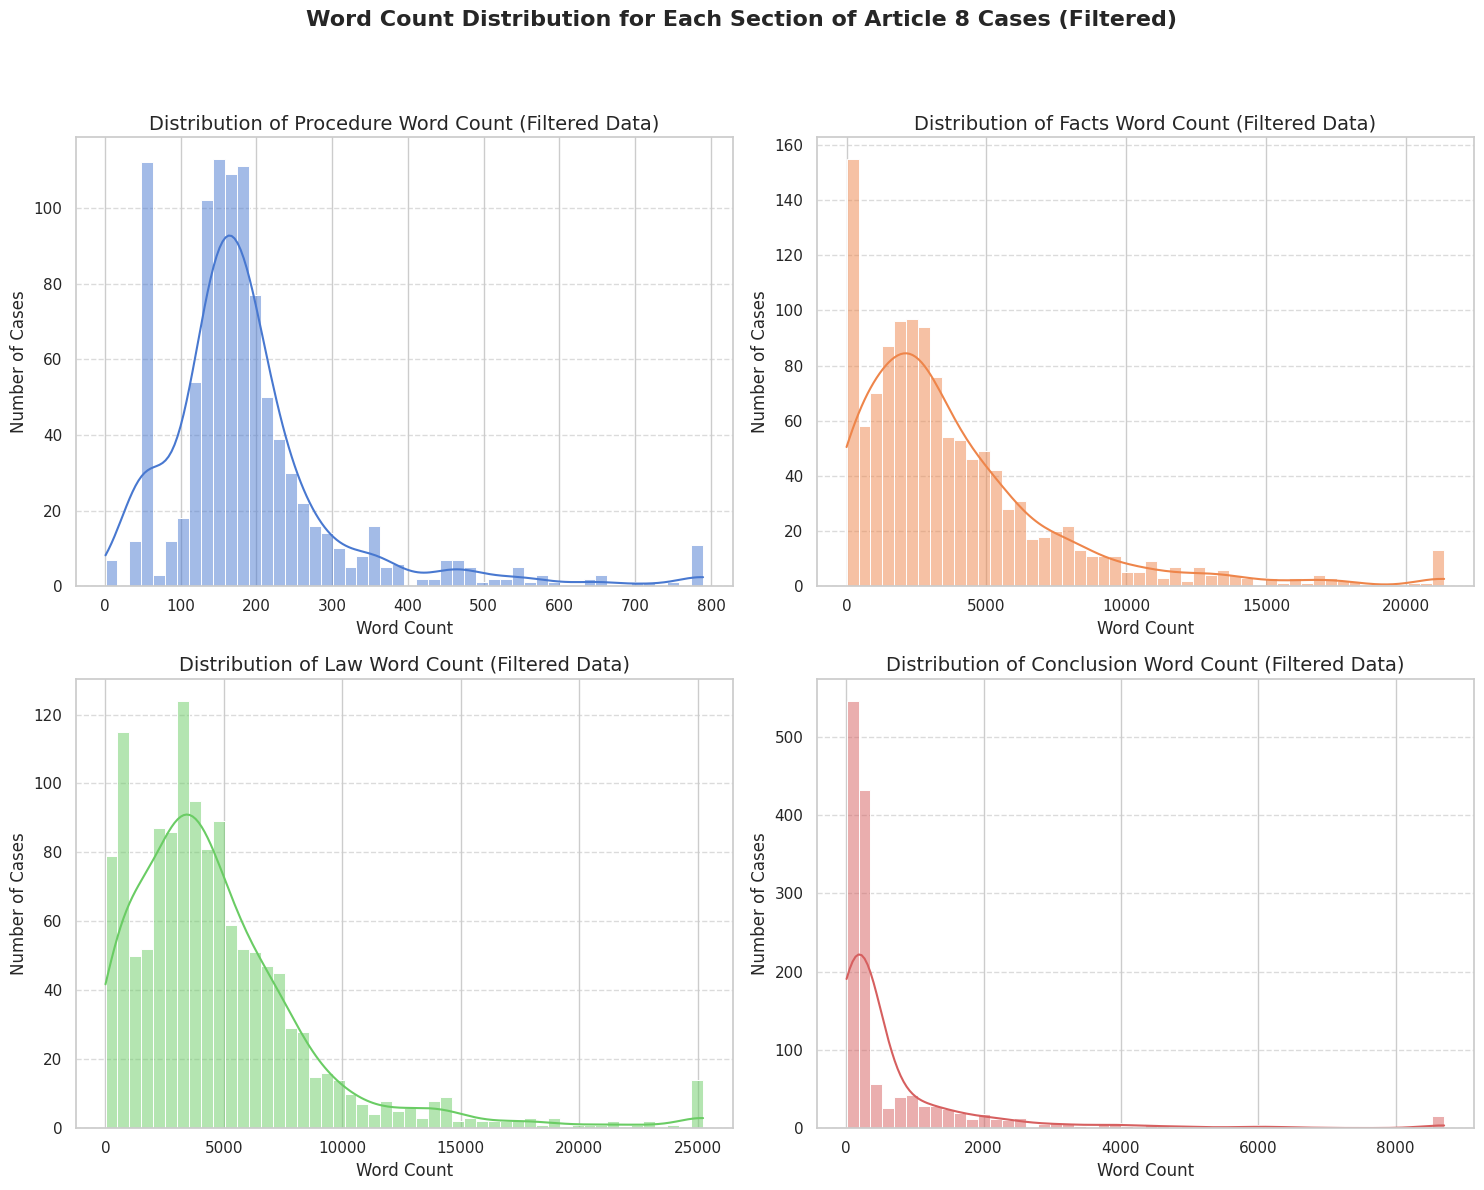

In [ ]:
sections = ['procedure', 'facts', 'law', 'conclusion']
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

# Filter df_sections once to get only the relevant sections
df_filtered_sections_for_plot = df_sections[df_sections['section_name'].isin(sections)].copy()

for i, sec in enumerate(sections):
    # Filter for the current section
    current_section_data = df_filtered_sections_for_plot[df_filtered_sections_for_plot['section_name'] == sec]

    # Filter out 0 word counts and extreme outliers for better visualization
    # Use quantiles to define a reasonable upper limit for plotting
    if not current_section_data.empty and (current_section_data['word_count'] > 0).any():
        upper_limit = current_section_data['word_count'][current_section_data['word_count'] > 0].quantile(0.99)
        plot_data = current_section_data[current_section_data['word_count'] > 0]['word_count'].clip(upper=upper_limit)
    else:
        plot_data = pd.Series([]) # Empty series if no data to plot

    if not plot_data.empty:
        sns.histplot(plot_data, bins=50, kde=True, ax=axes[i], color=sns.color_palette('muted')[i])
    else:
        # If plot_data is empty, still set up the subplot to avoid blank spaces
        axes[i].text(0.5, 0.5, 'No data to plot', horizontalalignment='center', verticalalignment='center', transform=axes[i].transAxes)

    axes[i].set_title(f'Distribution of {sec.capitalize()} Word Count (Filtered Data)', fontsize=14)
    axes[i].set_xlabel('Word Count')
    axes[i].set_ylabel('Number of Cases')
    axes[i].ticklabel_format(style='plain', axis='x') # Prevent scientific notation on x-axis
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.suptitle('Word Count Distribution for Each Section of Article 8 Cases (Filtered)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout(rect=[0, 0.03, 1, 0.98]) # Adjust layout to prevent title overlap
plt.show()

if not plot_data.empty:
    sns.histplot(plot_data, bins=50, kde=True, ax=axes[i], color=sns.color_palette('muted')[i])
    # Add median line
    median_val = plot_data.median()
    axes[i].axvline(median_val, color='red', linestyle='--', linewidth=1.5, label=f'Median: {int(median_val):,}')
    axes[i].legend(fontsize=9)

###3.1 Check Empty Section

In [ ]:
# Create a DataFrame with word counts for main sections for each itemid
main_sections = ['procedure', 'facts', 'law', 'conclusion']

df_main_section_word_counts = df_sections[df_sections['section_name'].isin(main_sections)].pivot_table(
    index='itemid',
    columns='section_name',
    values='word_count',
    fill_value=0
).reset_index()

# Rename columns to match the requested format
df_main_section_word_counts.columns.name = None
new_column_names = {col: f'{col}_word_count' for col in main_sections}
df_main_section_word_counts = df_main_section_word_counts.rename(columns=new_column_names)

# ── Drop existing word count columns if they already exist ──────────────────
# This prevents MergeError if the cell is run more than once
cols_to_drop = [f'{sec}_word_count' for sec in main_sections]
df_art8 = df_art8.drop(columns=[c for c in cols_to_drop if c in df_art8.columns])

# Merge word counts back to df_art8
df_art8 = pd.merge(
    df_art8,
    df_main_section_word_counts,
    on='itemid',
    how='left'
)

# Fill NaN values for word counts
for col in [f'{sec}_word_count' for sec in main_sections]:
    if col not in df_art8.columns:
        df_art8[col] = 0
    df_art8[col] = df_art8[col].fillna(0).astype(int)

# Identify cases where at least one main section has 0 word count
zero_word_count_cases = df_art8[
    (df_art8['procedure_word_count'] == 0) |
    (df_art8['facts_word_count'] == 0) |
    (df_art8['law_word_count'] == 0) |
    (df_art8['conclusion_word_count'] == 0)
].copy()

print(f"Total cases with at least one of the main sections having 0 word count: {len(zero_word_count_cases):,}")
display(zero_word_count_cases[[
    'itemid', 'procedure_word_count', 'facts_word_count', 'law_word_count', 'conclusion_word_count'
]])

Total cases with at least one of the main sections having 0 word count: 328


,itemid,procedure_word_count,facts_word_count,law_word_count,conclusion_word_count
3,001-210414,0,6843,9394,3971
8,001-214012,0,1678,5772,1032
12,001-213708,0,725,1589,163
14,001-209035,0,2516,2181,198
16,001-209317,0,17991,9826,80
...,...,...,...,...,...
1312,001-212367,0,2503,2421,154
1314,001-218117,0,4775,4560,149
1316,001-206901,0,11832,22970,1683
1319,001-212685,0,2397,2687,2427


In [ ]:
# Calculate and display the number of cases with 0 word count for each main section using df_sections_mapped
procedure_empty_count = (df_sections_mapped[df_sections_mapped['section_name'] == 'procedure']['word_count'] == 0).sum()
facts_empty_count = (df_sections_mapped[df_sections_mapped['section_name'] == 'facts']['word_count'] == 0).sum()
law_empty_count = (df_sections_mapped[df_sections_mapped['section_name'] == 'law']['word_count'] == 0).sum()
conclusion_empty_count = (df_sections_mapped[df_sections_mapped['section_name'] == 'conclusion']['word_count'] == 0).sum()

print(f"Number of cases with empty 'procedure' section : {procedure_empty_count:,}")
print(f"Number of cases with empty 'facts' section : {facts_empty_count:,}")
print(f"Number of cases with empty 'law' section : {law_empty_count:,}")
print(f"Number of cases with empty 'conclusion' section : {conclusion_empty_count:,}")


Number of cases with empty 'procedure' section : 82
Number of cases with empty 'facts' section : 80
Number of cases with empty 'law' section : 7
Number of cases with empty 'conclusion' section : 5


In [ ]:
# Check what sections cases missing procedure DO have
missing_procedure_ids = df_art8[df_art8['procedure_word_count'] == 0]['itemid']

# Look at what sections these cases have instead
missing_proc_sections = df_sections[df_sections['itemid'].isin(missing_procedure_ids)]
print('Section names present in cases missing procedure:')
print(missing_proc_sections['section_name'].value_counts())

# Check court type for these cases
print('\nCourt breakdown for cases missing procedure:')
print(df_art8[df_art8['procedure_word_count'] == 0]['court'].value_counts().head(10))

# Check importance level for these cases
print('\nImportance breakdown for cases missing procedure:')
print(df_art8[df_art8['procedure_word_count'] == 0]['importance'].value_counts().sort_index())

# Combine procedure and introduction into one field
df_art8['procedure_word_count'] = df_art8.apply(
    lambda row: max(row['procedure_word_count'],
                    df_sections[
                        (df_sections['itemid'] == row['itemid']) &
                        (df_sections['section_name'] == 'introduction')
                    ]['word_count'].sum()),
    axis=1
)

Section names present in cases missing procedure:
section_name
conclusion      401
law             319
relevant_law    249
facts           247
introduction    242
opinion           2
appendix          2
Name: count, dtype: int64

Court breakdown for cases missing procedure:
court
Third Section               52
Fith Section Committee      41
Third Section Committee     39
First Section               37
Fith Section                34
Fourth Section              33
Second Section Committee    27
First Section Committee     21
Second Section              20
Fourth Section Committee    16
Name: count, dtype: int64

Importance breakdown for cases missing procedure:
importance
1      8
3    111
4    201
Name: count, dtype: int64


###3.2 Check Short Section

In [ ]:
# Identify sections with word count less than 50, EXCLUDING 0 word counts
# Using df_sections_mapped which combines introduction -> procedure
short_sections = df_sections_mapped[
    (df_sections_mapped['word_count'] < 50) &
    (df_sections_mapped['word_count'] > 0) # Exclude empty sections
]

print('\n--- Sections with less than 50 words (excluding empty sections) ---')
if not short_sections.empty:
    print(f'Found {len(short_sections)} section entries with less than 50 words.')
    print('\nSummary by Section Type:')
    display(short_sections.groupby('section_name')['word_count'].agg(['count', 'min', 'max']))
else:
    print('No sections found with less than 50 words.')


--- Sections with less than 50 words (excluding empty sections) ---
Found 301 section entries with less than 50 words.

Summary by Section Type:


,count,min,max
section_name,,,
conclusion,69,22,49
facts,79,28,49
law,2,39,41
procedure,151,11,49


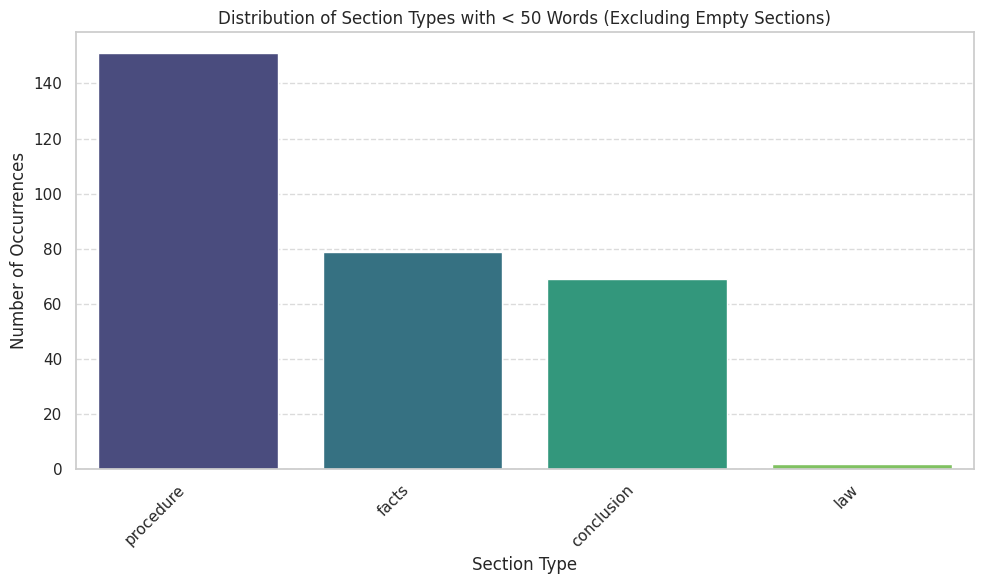

In [ ]:
# Calculate the distribution of section types in short_sections
short_section_type_counts = short_sections['section_name'].value_counts().reset_index()
short_section_type_counts.columns = ['section_name', 'count']

plt.figure(figsize=(10, 6))
sns.barplot(x='section_name', y='count', data=short_section_type_counts,
            palette='viridis', hue='section_name', legend=False)
plt.title('Distribution of Section Types with < 50 Words (Excluding Empty Sections)')
plt.xlabel('Section Type')
plt.ylabel('Number of Occurrences')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# --- Analysis for Cases with Short Facts Sections ---
print("\nDistribution of Importance Levels for Cases with 'Facts' Section < 50 Words:")

short_facts = short_sections[
    (short_sections['section_name'] == 'facts')]
# Filter df_art8 for itemids in short_facts
df_short_facts_importance = df_art8[df_art8['itemid'].isin(short_facts['itemid'])].copy()


display(df_short_facts_importance['importance'].value_counts().sort_index().to_frame())

short_law = short_sections[
    (short_sections['section_name'] == 'law')
]

# --- Analysis for Cases with Short Law Sections ---
print("\nDistribution of Importance Levels for Cases with 'Law' Section < 50 Words:")
# Filter df_art8 for itemids in short_law
df_short_law_importance = df_art8[df_art8['itemid'].isin(short_law['itemid'])].copy()
display(df_short_law_importance['importance'].value_counts().sort_index().to_frame())



Distribution of Importance Levels for Cases with 'Facts' Section < 50 Words:


,count
importance,
4,79



Distribution of Importance Levels for Cases with 'Law' Section < 50 Words:


,count
importance,
4,2


In [ ]:
# Investigate suspiciously short facts and law sections (excluding empty)
print('Cases with facts section under 50 words (excluding empty):')

display(df_art8[df_art8['itemid'].isin(short_facts['itemid'])][['itemid', 'title', 'court', 'importance']])

print('\nCases with law section under 50 words (excluding empty):')

display(df_art8[df_art8['itemid'].isin(short_law['itemid'])][['itemid', 'title', 'court', 'importance']])

Cases with facts section under 50 words (excluding empty):


,itemid,title,court,importance
18,001-226426,CASE OF YURGILEVICH AND OTHERS v. RUSSIA,Second Section Committee,4
29,001-219684,CASE OF KHUREN-OOL AND OTHERS v. RUSSIA,Third Section Committee,4
41,001-218431,CASE OF BOYKO-VELIKIY AND OTHERS v. RUSSIA,Third Section Committee,4
69,001-219124,CASE OF VASILEVSKIY AND OTHERS v. RUSSIA,Third Section Committee,4
89,001-219672,CASE OF PAVLOV AND OTHERS v. RUSSIA,Third Section Committee,4
...,...,...,...,...
1252,001-229157,CASE OF FILIMONOV AND OTHERS v. RUSSIA,First Section Committee,4
1264,001-220133,CASE OF GOVOROV v. RUSSIA,Third Section Committee,4
1275,001-185213,CASE OF UTIMISHEV AND OTHERS v. RUSSIA,Third Section Committee,4
1279,001-228369,CASE OF FAZIYEV AND OTHERS v. RUSSIA,First Section Committee,4



Cases with law section under 50 words (excluding empty):


,itemid,title,court,importance
280,001-228359,CASE OF MEHMET DEMİR v. TÜRKİYE,Second Section Committee,4
741,001-228364,CASE OF PACHECO CASTELO v. PORTUGAL,Fourth Section Committee,4


**Note :**

Committee judgments have structurally shorter Facts and Law sections — the 79 cases with Facts sections under 50 words are almost entirely importance level 4 Committee judgments against Russia. These cases apply established precedent without detailed reasoning, producing compressed judgments. This structural difference should be accounted for in any text-based analysis — Committee and Chamber judgments may not be directly comparable as training examples.

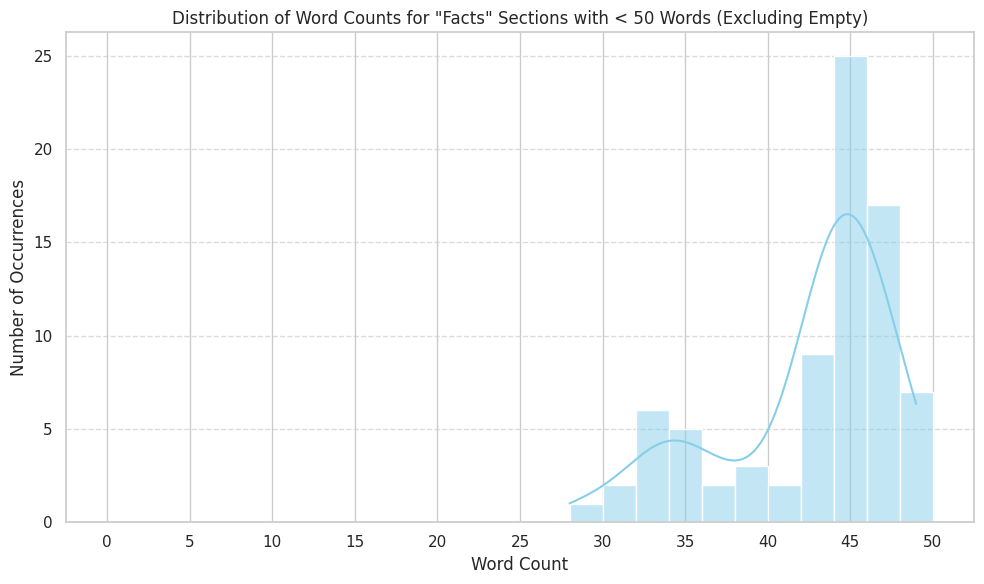

Summary statistics for 'facts' sections with < 50 words (excluding empty):



,word_count
count,79.000000
mean,42.367089
std,5.129545
min,28.000000
25%,41.000000
50%,44.000000
75%,46.000000
max,49.000000


In [ ]:
# Filter for 'facts' sections with fewer than 50 words from the previously identified short_sections (excluding empty)
short_facts_sections = short_sections[short_sections['section_name'] == 'facts'].copy()

if not short_facts_sections.empty:
    plt.figure(figsize=(10, 6))
    sns.histplot(short_facts_sections['word_count'], bins=range(0, 51, 2), kde=True, color='skyblue')
    plt.title('Distribution of Word Counts for "Facts" Sections with < 50 Words (Excluding Empty)')
    plt.xlabel('Word Count')
    plt.ylabel('Number of Occurrences')
    plt.xticks(range(0, 51, 5))
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    print(f"Summary statistics for 'facts' sections with < 50 words (excluding empty):\n")
    display(short_facts_sections['word_count'].describe().to_frame())
else:
    print("No 'facts' sections found with less than 50 words (excluding empty).")

**Note :**

Previously we faced an issue of too many Short Sections. This caused the content of certain sections to only cover part of the title and resulted in being cut off (word count skewed towards 0), but we solved the parsing and nesting issue by flattening all elements under the section. We do still have Short Section, but now the Short Section is actually valid and true, proven by new findings that all Short Section usually comes from Importance Level 4.

##3.3 Check Long Section

In [ ]:
# 1. Group the df_sections DataFrame by the 'section_name' column.
# 2. For each group, calculate the 95th percentile of the 'word_count' column.
percentiles_95 = df_sections_mapped.groupby('section_name')['word_count'].quantile(0.95)

# Sort the results by word_count in descending order
percentiles_95_sorted = percentiles_95.sort_values(ascending=False)

# Display the sorted results
print("\n95th Percentile Word Count per Section Type (Sorted by Highest):\n")
display(percentiles_95_sorted.to_frame())


95th Percentile Word Count per Section Type (Sorted by Highest):



,word_count
section_name,
law,12855.0
facts,12278.0
conclusion,3262.0
procedure,373.0


In [ ]:
# Initialize df_long_sections and populate it with data (moved from deleted cell c0c00704)
df_long_sections = pd.DataFrame()

# Define the sections to include (as per previous instructions)
selected_sections = ['procedure', 'facts', 'law', 'conclusion']

# Iterate over each section name and its corresponding 95th percentile word count
for section_name, threshold in percentiles_95.items():
    if section_name in selected_sections: # Only process selected sections
        # Filter the original df_sections for rows belonging to the current section_name
        # and where the word_count exceeds the threshold
        filtered_rows = df_sections_mapped[
          (df_sections_mapped['section_name'] == section_name) &
          (df_sections_mapped['word_count'] > threshold)]
        # Append these filtered rows to the df_long_sections DataFrame
        df_long_sections = pd.concat([df_long_sections, filtered_rows])

# Now, proceed with displaying the top 10 longest word counts per section
sections_to_display = ['procedure', 'facts', 'law', 'conclusion']

print("### Item IDs and Word Counts for Longest 5% Sections (Sorted by Word Count Descending) ###\n")

for section_name in sections_to_display:
    print(f"--- {section_name.capitalize()} Section ---")

    # Filter for the current section and sort by word_count in descending order
    sorted_section_data = df_long_sections[
        df_long_sections['section_name'] == section_name
    ].sort_values(by='word_count', ascending=False)[['itemid', 'word_count']]

    display(sorted_section_data.head(10).reset_index(drop=True))
    print("\n")

### Item IDs and Word Counts for Longest 5% Sections (Sorted by Word Count Descending) ###

--- Procedure Section ---


,itemid,word_count
0,001-146044,5007
1,001-146047,4896
2,001-202417,1630
3,001-207757,1450
4,001-183685,1125
5,001-99750,1105
6,001-145546,1098
7,001-183687,1008
8,001-111634,960
9,001-99915,837




--- Facts Section ---


,itemid,word_count
0,001-183687,92150
1,001-183685,83719
2,001-146047,60034
3,001-146044,58485
4,001-122697,56271
5,001-186048,53111
6,001-210077,44114
7,001-200333,44016
8,001-200336,40724
9,001-208053,29720




--- Law Section ---


,itemid,word_count
0,001-207757,63839
1,001-122697,62202
2,001-183685,50386
3,001-183687,45573
4,001-210077,40275
5,001-186048,38420
6,001-146044,35799
7,001-146047,33406
8,001-144669,32871
9,001-99750,30207




--- Conclusion Section ---


,itemid,word_count
0,001-207757,52766
1,001-155353,29299
2,001-145546,25402
3,001-155662,21724
4,001-157263,17541
5,001-210077,16205
6,001-99750,15782
7,001-194217,12673
8,001-163115,12108
9,001-217264,10143


In [ ]:
# Quick check on the suspiciously long conclusion case
case = df_art8[df_art8['itemid'] == '001-207757']
print(case[['itemid', 'title', 'court', 'importance']].values)

[['001-207757' 'CASE OF GEORGIA v. RUSSIA (II)' 'Grand Chamber' 1]]


**Note :**

Georgia v. Russia (II) (001-207757) is an extreme outlier — a Grand Chamber importance level 1 case concerning the 2008 armed conflict, with Facts (92,150 words), Law (76,592 words) and Conclusion (52,766 words) sections far exceeding all other cases. This case might be required to be treated separately or excluded from text length analyses to avoid skewing results.

###3.3.1 Long Section - Facts v. Importance

Number of cases with long 'facts' sections: 66

Distribution of Importance Levels for Longest Facts Sections:


,count
importance,
1,24
2,7
3,29
4,6


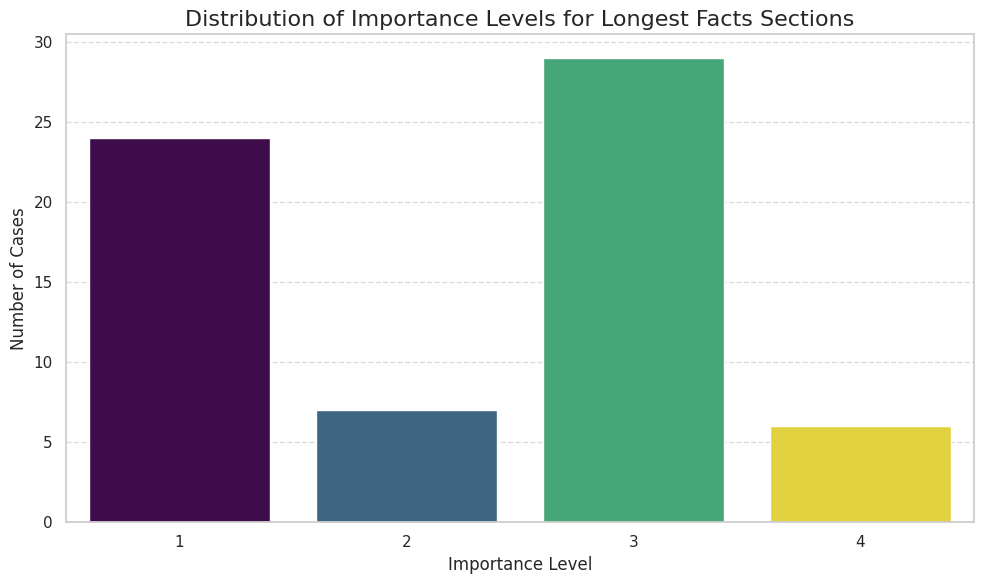

In [ ]:
# 1. Filter df_long_sections for 'facts' sections
long_facts_cases = df_long_sections[df_long_sections['section_name'] == 'facts'].copy()

# 2. Extract itemid and join with df_art8 to get 'importance' levels
df_long_facts_importance = df_art8[df_art8['itemid'].isin(long_facts_cases['itemid'])].copy()

# Ensure 'importance' is numeric and handle potential non-numeric entries
df_long_facts_importance['importance'] = pd.to_numeric(df_long_facts_importance['importance'], errors='coerce')
df_long_facts_importance.dropna(subset=['importance'], inplace=True)
df_long_facts_importance['importance'] = df_long_facts_importance['importance'].astype(int)

print(f"Number of cases with long 'facts' sections: {len(df_long_facts_importance)}")

# 3. Display the value counts of the 'importance' column
print("\nDistribution of Importance Levels for Longest Facts Sections:")
importance_counts = df_long_facts_importance['importance'].value_counts().sort_index()
display(importance_counts.to_frame())

# 4. Create a bar plot to visualize the distribution of 'importance' levels
plt.figure(figsize=(10, 6))
sns.barplot(x=importance_counts.index, y=importance_counts.values, palette='viridis', hue=importance_counts.index, legend=False)

# 5. Add title and labels
plt.title('Distribution of Importance Levels for Longest Facts Sections', fontsize=16)
plt.xlabel('Importance Level', fontsize=12)
plt.ylabel('Number of Cases', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

###3.3.2 Long Section - Law vs. Importance

Number of cases with long 'law' sections: 66

Distribution of Importance Levels for Longest Law Sections:


,count
importance,
1,27
2,7
3,29
4,3


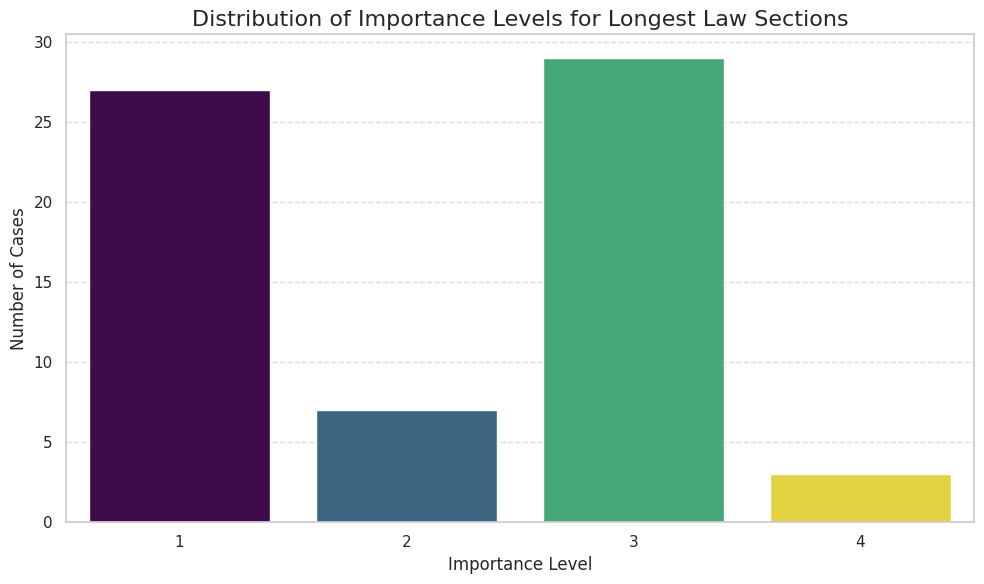

In [ ]:
# 1. Filter df_long_sections for 'law' sections
long_law_cases = df_long_sections[df_long_sections['section_name'] == 'law'].copy()

# 2. Extract itemid and join with df_art8 to get 'importance' levels
df_long_law_importance = df_art8[df_art8['itemid'].isin(long_law_cases['itemid'])].copy()

# Ensure 'importance' is numeric and handle potential non-numeric entries
df_long_law_importance['importance'] = pd.to_numeric(df_long_law_importance['importance'], errors='coerce')
df_long_law_importance.dropna(subset=['importance'], inplace=True)
df_long_law_importance['importance'] = df_long_law_importance['importance'].astype(int)

print(f"Number of cases with long 'law' sections: {len(df_long_law_importance)}")

# 3. Display the value counts of the 'importance' column
print("\nDistribution of Importance Levels for Longest Law Sections:")
importance_counts_law = df_long_law_importance['importance'].value_counts().sort_index()
display(importance_counts_law.to_frame())

# 4. Create a bar plot to visualize the distribution of 'importance' levels
plt.figure(figsize=(10, 6))
sns.barplot(x=importance_counts_law.index, y=importance_counts_law.values, palette='viridis', hue=importance_counts_law.index, legend=False)

# 5. Add title and labels
plt.title('Distribution of Importance Levels for Longest Law Sections', fontsize=16)
plt.xlabel('Importance Level', fontsize=12)
plt.ylabel('Number of Cases', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Note :**

In comparison to the Short Section, the distribution of importance level in the Long Section is dominated by Level 1 and 3. However, we can still find Long Section in all Importance Levels, including Level 4.



---


#**4. Descriptive Statistics & Correlation**




###4.1 Outcome Distribution


Outcome distribution for Article 8 cases:


,count
outcome_category,
Violation,983
No Violation,282
Others,56


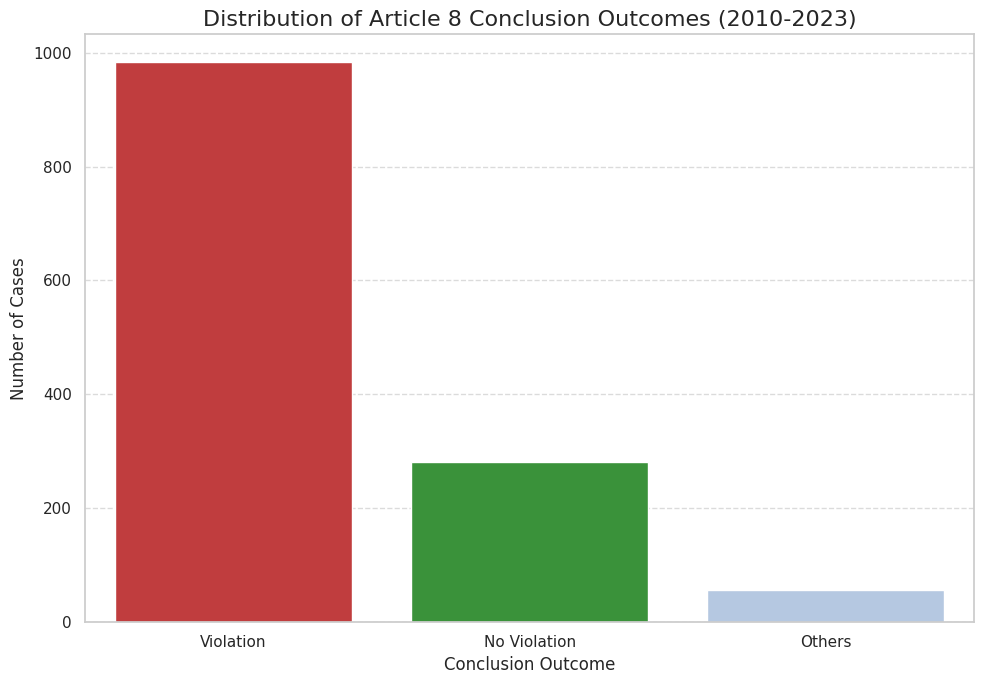

In [ ]:
# Ensure PALETTE is available from the setup cell
PALETTE = {'Violation': '#d62728', 'No Violation': '#2ca02c', 'Others': '#aec7e8'}

# Use the structured conclusion column for more accurate outcome extraction
# (see comparison note above — structured approach catches combined article findings)
df_art8['outcome_category'] = df_art8['finding_structured'].replace('Only Mentioning', 'Others')

# Get the distribution of outcome categories
outcome_distribution = df_art8['outcome_category'].value_counts()

print('\nOutcome distribution for Article 8 cases:')
display(outcome_distribution.to_frame())

# Plot the distribution
plt.figure(figsize=(10, 7))
sns.barplot(
    x=outcome_distribution.index,
    y=outcome_distribution.values,
    palette=PALETTE,
    hue=outcome_distribution.index,
    legend=False,
    order=['Violation', 'No Violation', 'Others']
)
plt.title('Distribution of Article 8 Conclusion Outcomes (2010-2023)', fontsize=16)
plt.xlabel('Conclusion Outcome', fontsize=12)
plt.ylabel('Number of Cases', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Note :**

Category "Others" covers all cases where the `type` in Conclusion column is not mentioning either violation or no-violation.
Several possibility of cases under this category are:
- Inadmissibile cases : The text mentions "Article 8" because the applicant tried to sue under it, but the Court never reached the "Facts" or "Law" stage to decide if a violation occurred.
- Procedural Absorption (of another article) :  The text might say, "In view of the finding under Article 6, the Court considers it unnecessary to examine the complaint under Article 8. Since the Court declined to rule, there is no "Violation" or "No Violation" label assigned.

Therefore, during further analysis below and for model training later, we have decided to exclude cases from the "Others" category and focus only on "Violation" and "No Violation" cases.

####4.1.1 Case Outcome per year


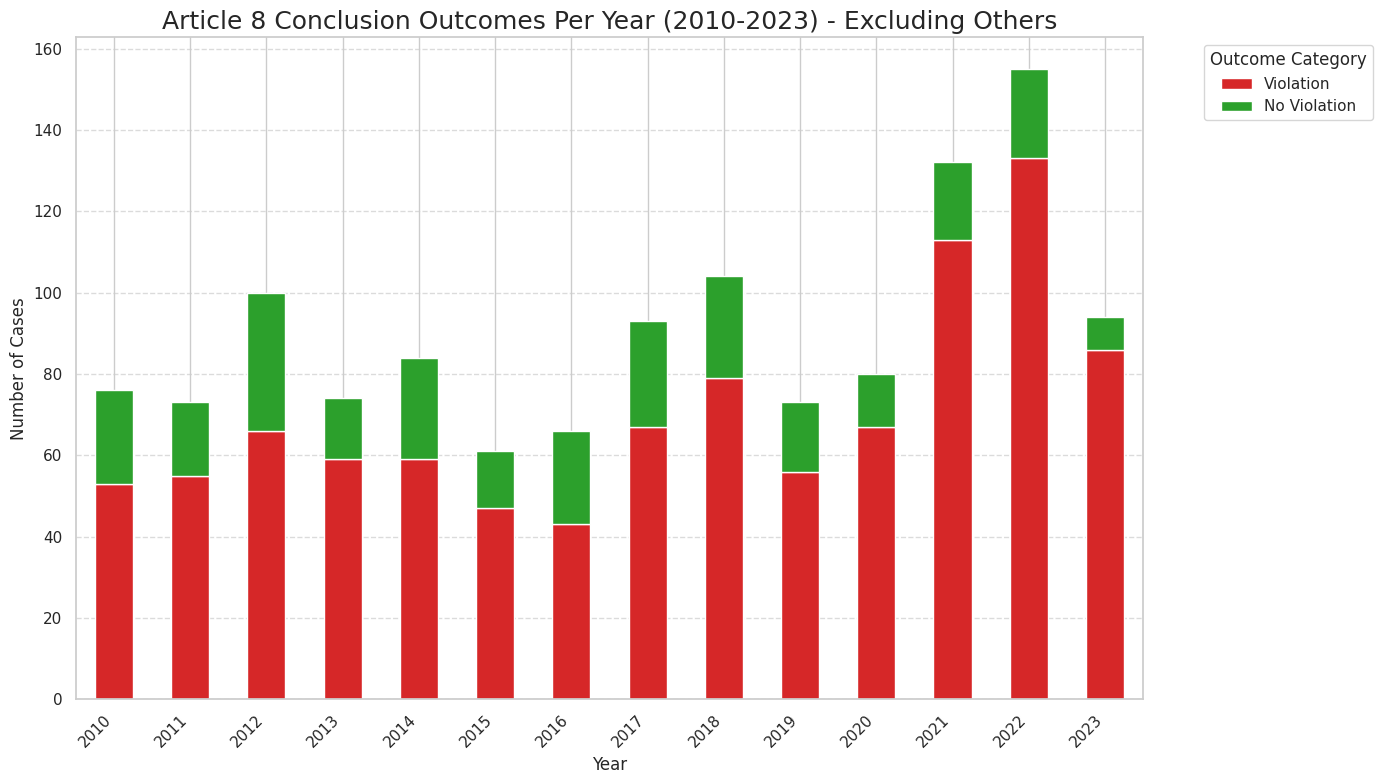

In [ ]:
# Calculate outcomes per year
outcomes_per_year = df_art8.groupby(['year', 'outcome_category']).size().unstack(fill_value=0)

# Sort by year to ensure correct plotting order
outcomes_per_year = outcomes_per_year.sort_index()

# Exclude 'Others' category
outcomes_per_year = outcomes_per_year.drop(columns=['Others'], errors='ignore')

# Reorder columns to ensure consistent color mapping
expected_columns = ['Violation', 'No Violation']
current_columns = outcomes_per_year.columns.tolist()
ordered_columns = [col for col in expected_columns if col in current_columns]
ordered_columns.extend([col for col in current_columns if col not in expected_columns])
outcomes_per_year = outcomes_per_year[ordered_columns]

# Plotting the stacked bar chart
plt.figure(figsize=(14, 8))
ax = outcomes_per_year.plot(
    kind='bar',
    stacked=True,
    color=[PALETTE.get(col, '#cccccc') for col in outcomes_per_year.columns],
    ax=plt.gca()
)

plt.title('Article 8 Conclusion Outcomes Per Year (2010-2023) - Excluding Others', fontsize=18)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Cases', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Outcome Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Note :**

Case volume spiked sharply in 2021-2022 — the two highest years in the dataset, likely reflecting a combination of post-pandemic processing of a backlog and the surge of pending Russian cases being resolved following Russia's expulsion from the Council of Europe in March 2022 after its invasion of Ukraine. Cases against Russia, which had historically been one of the largest sources of Article 8 violations, were processed and concluded before the Court's jurisdiction over Russia formally lapsed. The ratio of Violation to No Violation remains broadly stable across all years, suggesting the spike reflects case processing volume rather than a structural shift in outcomes.

###4.2 Top Respondent

Top 10 Respondent Countries for Article 8 Cases:


,count
country_name,
Russia,343
Ukraine,112
Romania,72
Poland,67
Croatia,60
Bulgaria,53
Turkey,42
Hungary,40
Norway,36


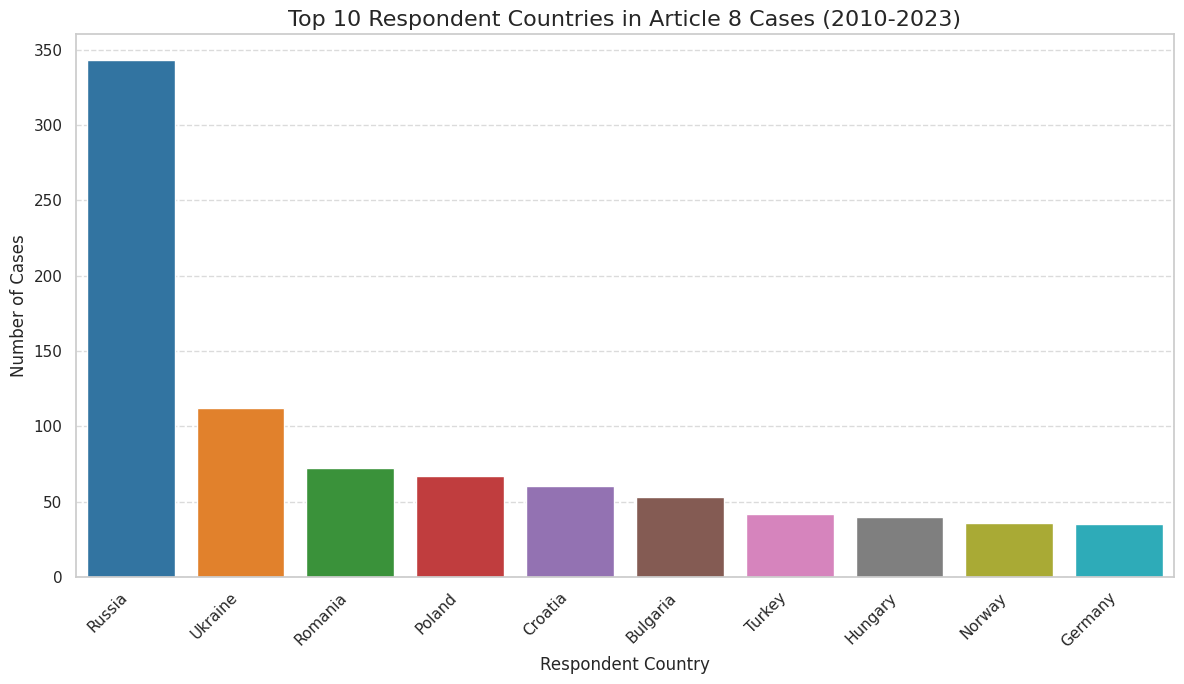

In [ ]:
# ISO code to full country name mapping
country_names = {
    'RUS': 'Russia', 'UKR': 'Ukraine', 'ROM': 'Romania', 'POL': 'Poland',
    'HRV': 'Croatia', 'TUR': 'Turkey', 'BGR': 'Bulgaria', 'MDA': 'Moldova',
    'HUN': 'Hungary', 'GBR': 'UK', 'FRA': 'France', 'ITA': 'Italy',
    'SVN': 'Slovenia', 'AUT': 'Austria', 'CZE': 'Czechia', 'SRB': 'Serbia',
    'GEO': 'Georgia', 'AZE': 'Azerbaijan', 'LVA': 'Latvia', 'LTU': 'Lithuania', 'ROU': 'Romania','NOR': 'Norway', 'DEU': 'Germany',}

COUNTRY_PALETTE = {
    'RUS': '#1f77b4',  # Russia - Deep Blue
    'UKR': '#ff7f0e',  # Ukraine - Bright Orange
    'ROU': '#2ca02c',  # Romania - Forest Green
    'POL': '#d62728',  # Poland - Crimson
    'HRV': '#9467bd',  # Croatia - Royal Purple
    'BGR': '#8c564b',  # Bulgaria - Earth Brown
    'TUR': '#e377c2',  # Turkey - Pink/Magenta
    'HUN': '#7f7f7f',  # Hungary - Slate Grey
    'NOR': '#bcbd22',  # Norway - Olive Gold
    'DEU': '#17becf'   # Germany - Teal Blue
}

df_art8['country_name'] = df_art8['country'].map(country_names).fillna(df_art8['country'])

top_respondents = df_art8['country_name'].value_counts().head(10)

print('Top 10 Respondent Countries for Article 8 Cases:')
display(top_respondents.to_frame())

# Create a mapping from country names (from top_respondents.index) to their ISO codes
name_to_iso_code = {name: iso for iso, name in country_names.items()}
# Create a palette that maps country names to colors from COUNTRY_PALETTE
plot_palette = {name: COUNTRY_PALETTE.get(name_to_iso_code.get(name), '#cccccc') for name in top_respondents.index}

plt.figure(figsize=(12, 7))
sns.barplot(
    x=top_respondents.index,
    y=top_respondents.values,
    palette=plot_palette, # Apply the custom palette
    hue=top_respondents.index, # Keep hue to ensure bars are colored based on country name
    legend=False
)
plt.title('Top 10 Respondent Countries in Article 8 Cases (2010-2023)', fontsize=16)
plt.xlabel('Respondent Country', fontsize=12)
plt.ylabel('Number of Cases', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

####4.2.1 Top Respondent per Year

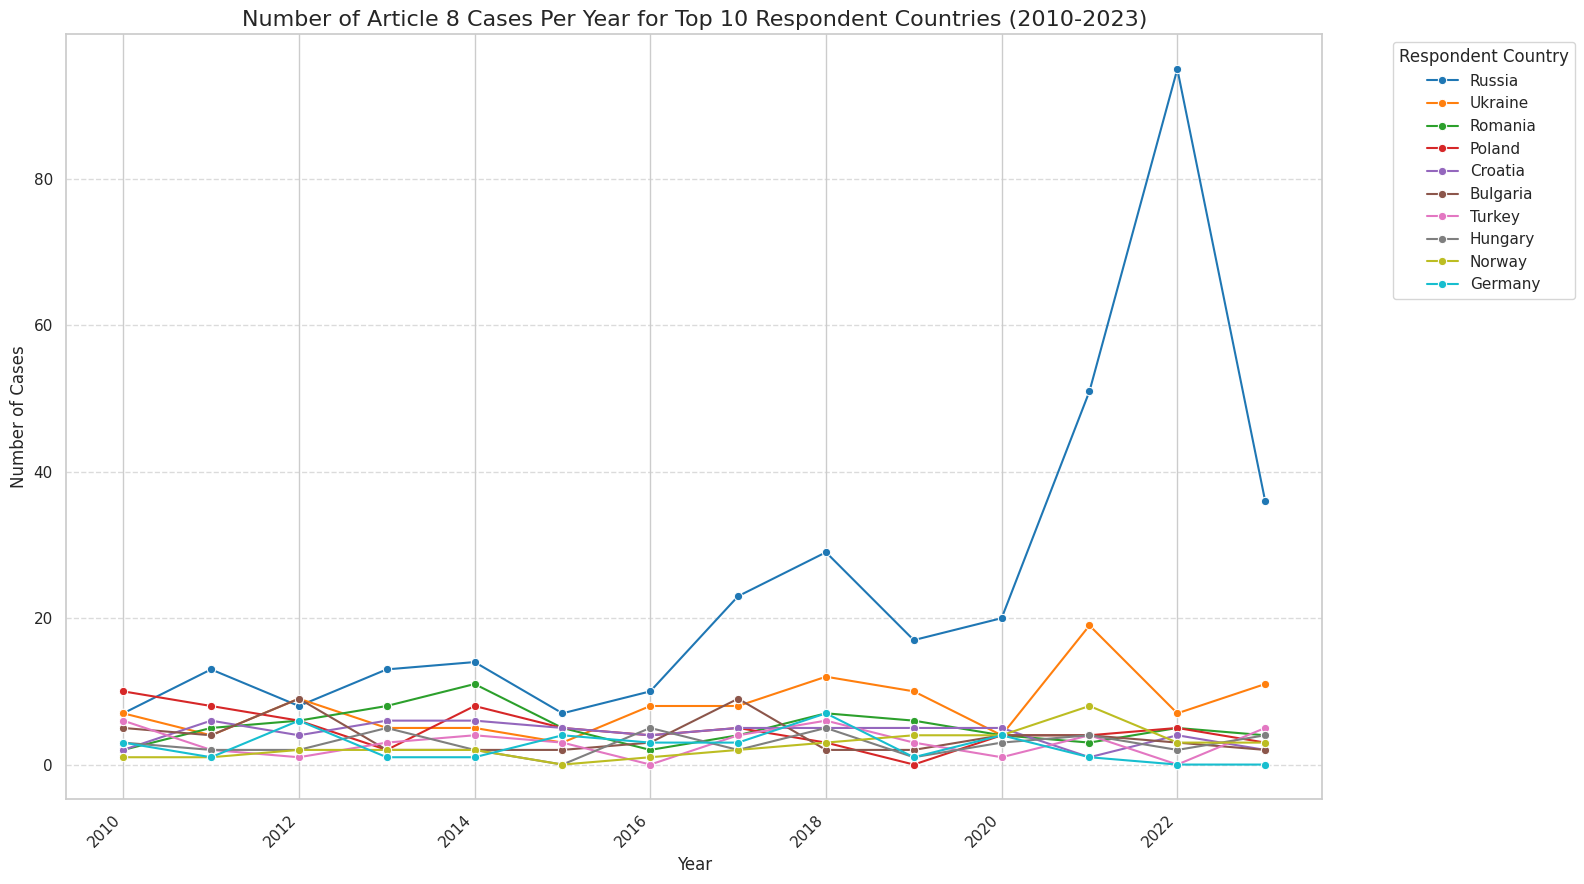

In [ ]:
COUNTRY_PALETTE = {
    'RUS': '#1f77b4',  # Russia - Deep Blue
    'UKR': '#ff7f0e',  # Ukraine - Bright Orange
    'ROU': '#2ca02c',  # Romania - Forest Green
    'POL': '#d62728',  # Poland - Crimson
    'HRV': '#9467bd',  # Croatia - Royal Purple
    'BGR': '#8c564b',  # Bulgaria - Earth Brown
    'TUR': '#e377c2',  # Turkey - Pink/Magenta
    'HUN': '#7f7f7f',  # Hungary - Slate Grey
    'NOR': '#bcbd22',  # Norway - Olive Gold
    'DEU': '#17becf'   # Germany - Teal Blue
}
# Get the list of top 10 respondent countries
top_10_countries = top_respondents.index.tolist()

# Filter df_art8 for only these top 10 countries
df_top_countries = df_art8[df_art8['country_name'].isin(top_10_countries)].copy()

# Group by year and country_name to count cases
cases_per_year_per_country = df_top_countries.groupby(['year', 'country_name']).size().unstack(fill_value=0)

# Sort by year for plotting
cases_per_year_per_country = cases_per_year_per_country.sort_index()

# Reorder columns to match top 10 order
cases_per_year_per_country = cases_per_year_per_country[top_10_countries]

# Create a mapping from country names (from cases_per_year_per_country.columns) to their ISO codes
# This assumes 'country_names' dictionary is globally available from a previous cell, which it is.
name_to_iso_code = {name: iso for iso, name in country_names.items()}
# Create a palette that maps country names to colors from COUNTRY_PALETTE
line_plot_palette = {name: COUNTRY_PALETTE.get(name_to_iso_code.get(name), '#cccccc') for name in cases_per_year_per_country.columns}

plt.figure(figsize=(16, 9))
sns.lineplot(data=cases_per_year_per_country, dashes=False, marker='o', palette=line_plot_palette)

plt.title('Number of Article 8 Cases Per Year for Top 10 Respondent Countries (2010-2023)', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Cases', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Respondent Country', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Note :**

The 2022 spike is almost entirely attributable to Russia (blue), whose cases surged to their highest point in the dataset before dropping sharply in 2023 as the Court concluded pending proceedings following Russia's expulsion from the Council of Europe in March 2022. This pattern appears to be the effect of geopolitical context rather than a genuine trend in Article 8 litigation.

Also notable is Ukraine's steady increase in cases (orange), which rises from 2021 and becomes the leading respondent country by 2023 as Russian cases recede. This is consistent with the ongoing conflict generating new human rights complaints against Ukraine, and reflects the Court's continued jurisdiction over Ukraine, unlike Russia, meaning Ukrainian cases will persist in future datasets.

###4.3 Article Pairing

Distribution of Article 8 Citation Types:


,count
article_citation_type,
Mixed Articles,894
Article 8 Only,427


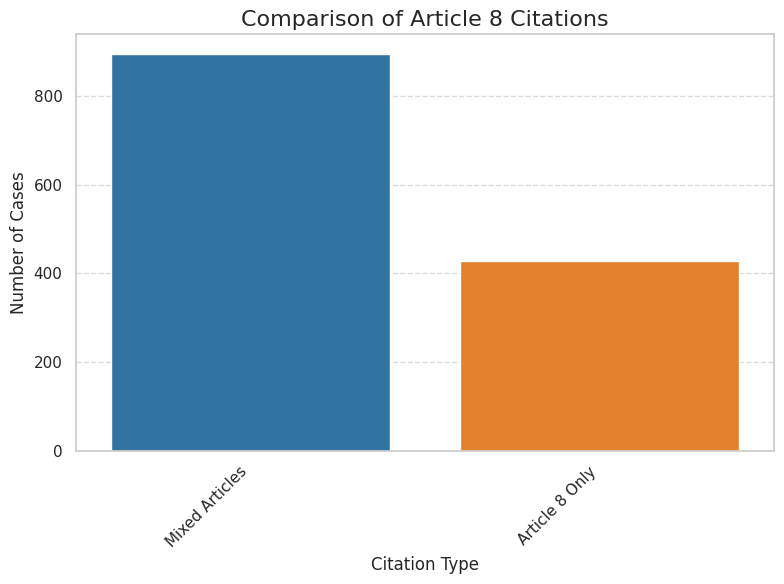

In [ ]:
def categorize_article_citations(article_list):
    """Categorizes if a case cites only Article 8 or Article 8 with other articles."""
    if not isinstance(article_list, list) or not article_list:
        return 'No Article Info'

    article_list_cleaned = [str(a).strip() for a in article_list]

    if '8' in article_list_cleaned:
        if len(article_list_cleaned) == 1:
            return 'Article 8 Only'
        else:
            return 'Mixed Articles'
    else:
        return 'Not Article 8 Case'

# Apply the categorization function
df_art8['article_citation_type'] = df_art8['article_numbers'].apply(categorize_article_citations)

# Get the counts for each category
citation_distribution = df_art8['article_citation_type'].value_counts()

print('Distribution of Article 8 Citation Types:')
display(citation_distribution.to_frame())

# Plot the distribution
plt.figure(figsize=(8, 6))
sns.barplot(
    x=citation_distribution.index,
    y=citation_distribution.values,
    hue=citation_distribution.index,
    palette=['#1f77b4', '#ff7f0e'],
    legend=False
)
plt.title('Comparison of Article 8 Citations', fontsize=16)
plt.xlabel('Citation Type', fontsize=12)
plt.ylabel('Number of Cases', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Note :**

The chart reveals that the majority of cases in the dataset (894 cases) cite Article 8 alongside other Convention articles, while 427 cases cite Article 8 alone. Cases involving only Article 8 are more likely to be non-violation cases, accounting for 353 out of 427 single-article cases. Where a complaint is confined to Article 8 alone, it often reflects a more contained rights issue where the Court finds the state's interference to be proportionate and justified.

By contrast, mixed-article cases typically involve more severe human rights situations and correspondingly account for the majority of violation findings in the dataset. This distribution suggests that citation type may itself be a useful signal in the dataset, though it should not be taken as a direct prediction for outcome, as mixed cases also contain non-violations.




#####4.3.1 Article Pairing per year

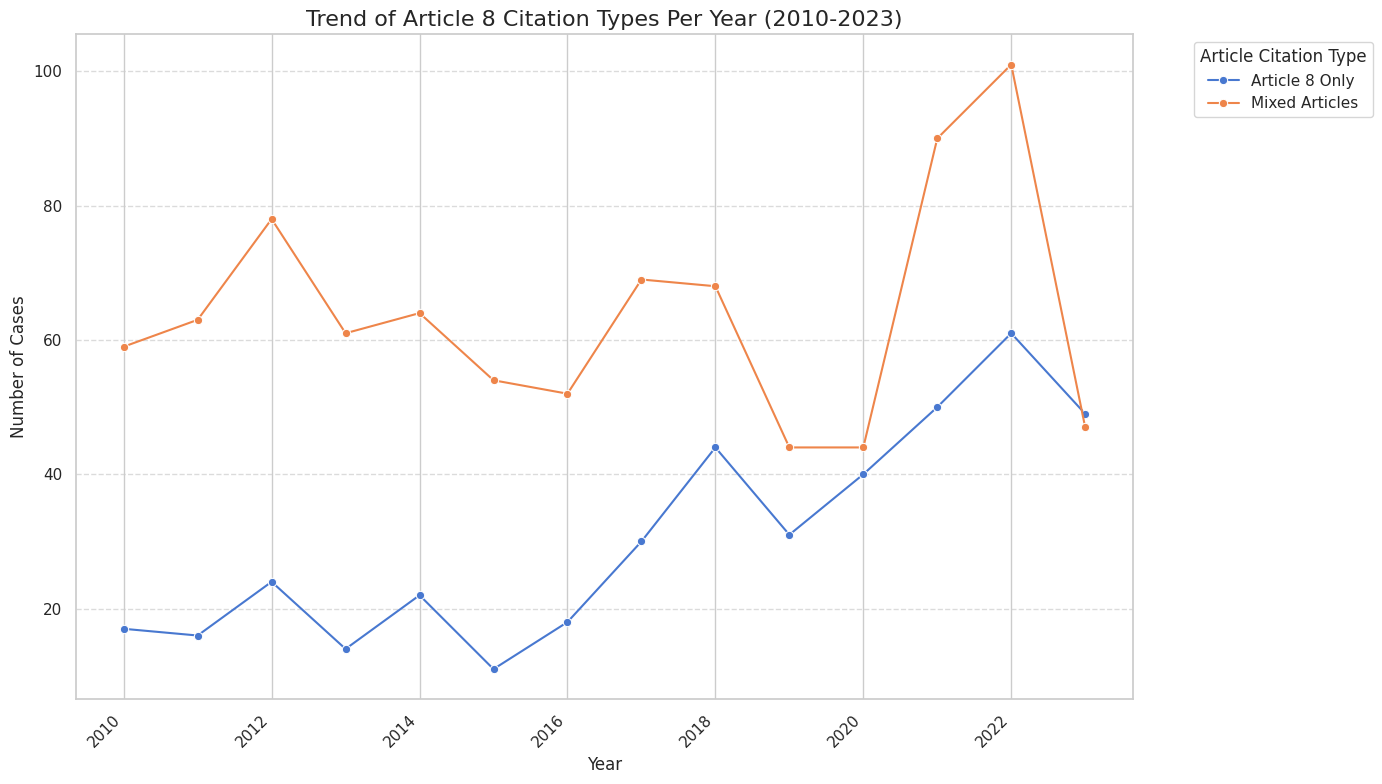

In [ ]:
# Group by year and article_citation_type to count cases
cases_by_citation_type_per_year = df_art8.groupby(['year', 'article_citation_type']).size().unstack(fill_value=0)

# Ensure only 'Article 8 Only' and 'Mixed Articles' are considered for plotting
cases_by_citation_type_per_year = cases_by_citation_type_per_year[['Article 8 Only', 'Mixed Articles']]

# Sort by year to ensure correct plotting order
cases_by_citation_type_per_year = cases_by_citation_type_per_year.sort_index()

plt.figure(figsize=(14, 8))
sns.lineplot(data=cases_by_citation_type_per_year, marker='o', dashes=False)

plt.title('Trend of Article 8 Citation Types Per Year (2010-2023)', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Cases', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Article Citation Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Note :**

Notably, 2022 saw a spike in both mixed-article citations and violation findings, which coincides with Russia becoming the top respondent state that year. This is likely attributable to the Council of Europe's expulsion of Russia in March 2022 following the invasion of Ukraine, after which a significant volume of pending Russian cases were processed and decided.

Given that many of these cases concerned serious and multifaceted rights violations, the surge in mixed-article cases and violation outcomes in 2022 is consistent with this geopolitical context.

Mixed Articles cases consistently outnumber Article 8 Only cases — throughout 2010-2023, cases citing Article 8 alongside other articles outnumber standalone Article 8 cases, typically by a ratio of roughly 2:1 to 3:1. However, Article 8 Only cases have grown substantially since 2016, suggesting an increasing focus on pure privacy and family life complaints.

####4.3.2 Top Article Pairing

In [ ]:
import re
from collections import Counter

# 1. Filter the df_art8 DataFrame to include only cases where the 'article_citation_type' is 'Mixed Articles'.
df_mixed_articles = df_art8[df_art8['article_citation_type'] == 'Mixed Articles'].copy()

# 2. Initialize an empty list named all_article_sets.
all_article_sets = []

# 3. Iterate through the 'article_numbers' column of the df_mixed_articles DataFrame.
for articles_list in df_mixed_articles['article_numbers']:
    if isinstance(articles_list, list) and articles_list:
        # 4. Clean the data: convert to string, strip, convert numeric strings to integers.
        cleaned_articles = []
        for item in articles_list:
            s_item = str(item).strip()
            if s_item.isdigit():
                cleaned_articles.append(int(s_item))

        # Ensure the resulting list of cleaned articles is not empty
        if cleaned_articles:
            # 5. Extract unique article numbers, sort them, and convert to a tuple.
            unique_sorted_articles = tuple(sorted(list(set(cleaned_articles))))
            all_article_sets.append(unique_sorted_articles)

# 6. Use the Counter class from the collections module to count the frequency of each unique article set.
set_counts = Counter(all_article_sets)

print(f"Processed {len(df_mixed_articles)} 'Mixed Articles' cases.")
print(f"Found {len(all_article_sets)} article sets.")
print("Top 10 most frequent article sets:")
for article_set, count in set_counts.most_common(10):
    print(f"  Articles {article_set}: {count} times")

Processed 894 'Mixed Articles' cases.
Found 894 article sets.
Top 10 most frequent article sets:
  Articles (8, 41): 91 times
  Articles (8, 35, 41): 76 times
  Articles (8, 13): 57 times
  Articles (6, 8): 44 times
  Articles (3, 8): 40 times
  Articles (8, 35): 39 times
  Articles (3, 8, 13): 34 times
  Articles (3, 5, 8, 13): 25 times
  Articles (8, 14): 21 times
  Articles (6, 8, 35, 41): 21 times


**Note :**

Article 41 dominates the article combinations, appearing in the top two pairings, 8+41 (91 cases) and 8+35+41 (76 cases). This is expected since Article 41 (just satisfaction) is always cited alongside any substantive violation finding to award compensation, and is consistent with the outcome-consequent language identified in the pecuniary damage concordance analysis.

Article 35 (admissibility) appears frequently in combinations such as (8+35+ 41) and (8+35), suggesting that a substantial number of cases involved admissibility challenges before reaching the merits determination.

Article 13 (right to an effective remedy) is the most meaningful companion article, appearing in 8+13 (57 cases) and 3+8+13 (34 cases). This reflects a recurring pattern where applicants argue both a substantive Article 8 violation and the failure of domestic remedies.


Article 3 (prohibition of torture and inhuman treatment) pairs frequently with Article 8, appearing in (3+8), (3+8+13) and (3+5+8+13). This reflects cases involving surveillance, detention conditions or family separation where both dignity and privacy rights are at stake.

Article 6 (right to a fair trial) also pairs notably with Article 8, appearing in 6+8 (44 cases) and 6+8+35+41 (21 cases), reflecting cases where procedural fairness complaints accompanied the Article 8 merits. Article 14 (prohibition of discrimination) appears in 8+14 (21 cases), pointing to cases where Article 8 rights were engaged alongside discrimination complaints, a recognised pairing in cases concerning minority and LGBTQ+ rights.

Top 10 Most Frequent Article Sets in 'Mixed Articles' Cases:


,Article Set,Count,Article Set Label
0,"(8, 41)",91,8+41
1,"(8, 35, 41)",76,8+35+41
2,"(8, 13)",57,8+13
3,"(6, 8)",44,6+8
4,"(3, 8)",40,3+8
5,"(8, 35)",39,8+35
6,"(3, 8, 13)",34,3+8+13
7,"(3, 5, 8, 13)",25,3+5+8+13
8,"(8, 14)",21,8+14
9,"(6, 8, 35, 41)",21,6+8+35+41


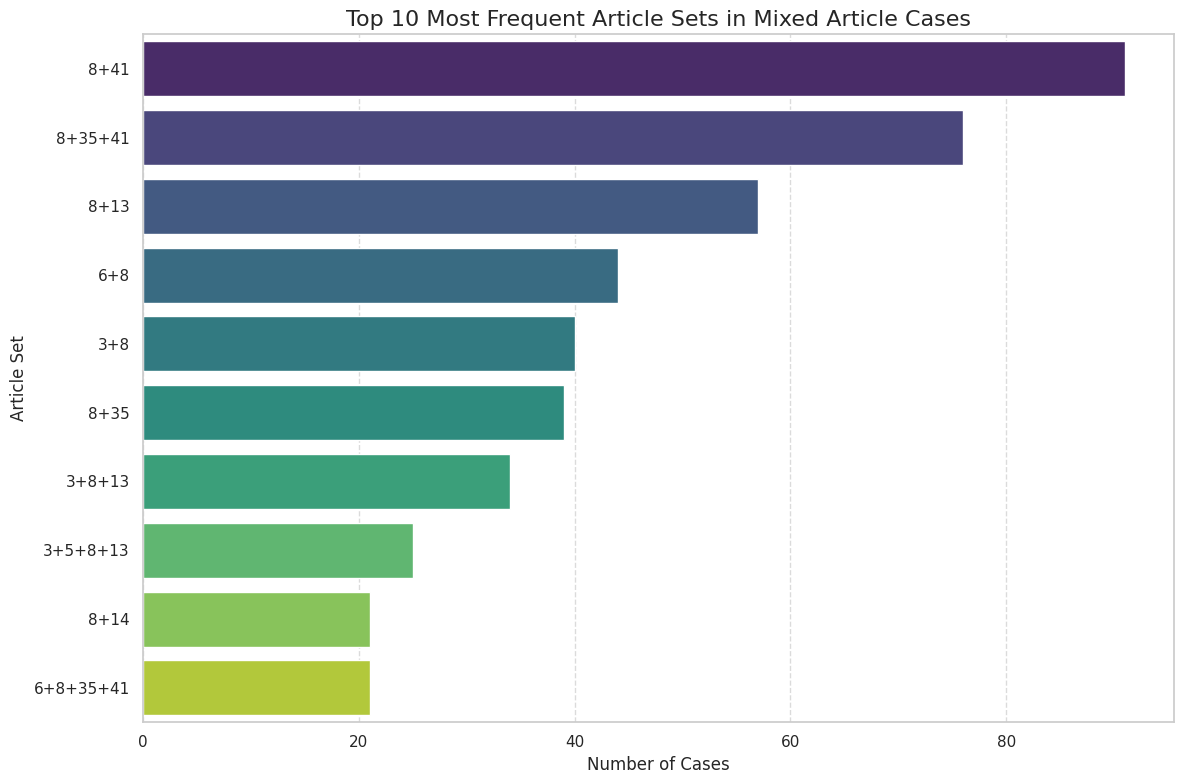


Counts for specific article combinations:
  Combination '8+41': 91 cases
  Combination '8+35': 39 cases
  Combination '8+41+35': 76 cases


In [ ]:
# 4. Get the top 10 most frequent article sets
top_n = 10
most_common_sets = set_counts.most_common(top_n)

# Convert to a DataFrame for easier plotting
df_set_counts = pd.DataFrame(most_common_sets, columns=['Article Set', 'Count'])
df_set_counts['Article Set Label'] = df_set_counts['Article Set'].apply(lambda x: '+'.join(map(str, x)))

print(f"Top {top_n} Most Frequent Article Sets in 'Mixed Articles' Cases:")
display(df_set_counts)

# 5. Visualize the top article sets
plt.figure(figsize=(12, 8))
sns.barplot(x='Count', y='Article Set Label', data=df_set_counts, palette='viridis', hue='Article Set Label', legend=False)
plt.title(f'Top {top_n} Most Frequent Article Sets in Mixed Article Cases', fontsize=16)
plt.xlabel('Number of Cases', fontsize=12)
plt.ylabel('Article Set', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 6. Explicitly display counts for specific combinations: '8+41', '8+35', and '8+41+35'
print("\nCounts for specific article combinations:")

# Define the target sets, sorted and as tuples
target_sets = {
    tuple(sorted([8, 41])): '8+41',
    tuple(sorted([8, 35])): '8+35',
    tuple(sorted([8, 41, 35])): '8+41+35'
}

for set_tuple, set_label in target_sets.items():
    count = set_counts.get(set_tuple, 0)
    print(f"  Combination '{set_label}': {count} cases")

**Note :**

The analysis of 'Mixed Articles' cases reveals the most common sets of articles cited together with Article 8.
The top 10 most frequent sets are shown above, indicating which other articles are most commonly invoked in conjunction with Article 8.
Notably, Article 41 (just satisfaction) dominates, appearing in 8+41 (91 cases) and 8+35+41 (76 cases), reflecting that compensation awards routinely accompany violation findings. Article 35 (admissibility) features frequently, indicating procedural challenges were common before reaching the merits.

Beyond procedural pairings, Article 13 (right to an effective remedy) is the most frequent substantive companion in 8+13 (57 cases), while Article 3 pairs with Article 8 across multiple combinations, reflecting cases where detention and surveillance engaged both articles. Article 6 (44 cases) and Article 14 (21 cases) point to fair trial and discrimination complaints arising alongside Article 8 issues respectively.




####4.3.3 Top Article Pairing per year

In [ ]:
# 1. Extract the actual article set tuples from the most_common_sets list
top_10_article_set_tuples = [item[0] for item in set_counts.most_common(10)]

# 2. Create a dictionary named article_set_labels that maps each article set tuple to a readable string label
article_set_labels = {tpl: '+'.join(map(str, tpl)) for tpl in top_10_article_set_tuples}

print(f"Top 10 article set tuples extracted: {top_10_article_set_tuples}")
print(f"Article set labels created: {article_set_labels}")

Top 10 article set tuples extracted: [(8, 41), (8, 35, 41), (8, 13), (6, 8), (3, 8), (8, 35), (3, 8, 13), (3, 5, 8, 13), (8, 14), (6, 8, 35, 41)]
Article set labels created: {(8, 41): '8+41', (8, 35, 41): '8+35+41', (8, 13): '8+13', (6, 8): '6+8', (3, 8): '3+8', (8, 35): '8+35', (3, 8, 13): '3+8+13', (3, 5, 8, 13): '3+5+8+13', (8, 14): '8+14', (6, 8, 35, 41): '6+8+35+41'}


In [ ]:

# 3. Initialize a nested dictionary, yearly_top_article_set_counts
yearly_top_article_set_counts = {label: {year: 0 for year in range(2010, 2024)} for label in article_set_labels.values()}

# 4. Iterate through each row of the df_mixed_articles DataFrame.
# 5. For each case, extract its year and article_numbers list.
# 6. Clean the article_numbers by converting each item to a string, stripping whitespace, and converting numeric strings to integers.
# 7. If cleaned_articles is not empty, create a unique, sorted tuple of these article numbers (unique_sorted_articles_tuple).
# 8. Check if this unique_sorted_articles_tuple is present in your top_10_article_set_tuples.
# 9. If it is one of the top 10 sets and the year exists as a key in the corresponding entry in yearly_top_article_set_counts, increment its count by 1.
for index, row in df_mixed_articles.iterrows():
    year = row['year']
    articles_list = row['article_numbers']

    if isinstance(articles_list, list) and articles_list:
        cleaned_articles = []
        for item in articles_list:
            s_item = str(item).strip()
            if s_item.isdigit():
                cleaned_articles.append(int(s_item))

        if cleaned_articles:
            unique_sorted_articles_tuple = tuple(sorted(list(set(cleaned_articles))))

            # Check if this article set is one of the top 10
            if unique_sorted_articles_tuple in top_10_article_set_tuples:
                label = article_set_labels[unique_sorted_articles_tuple]
                if year in yearly_top_article_set_counts[label]:
                    yearly_top_article_set_counts[label][year] += 1

# Convert the dictionary to a DataFrame for easier visualization and further processing
df_yearly_top_article_sets = pd.DataFrame(yearly_top_article_set_counts).sort_index()

print("Yearly counts for the top 10 most frequent article sets:")
display(df_yearly_top_article_sets)

Yearly counts for the top 10 most frequent article sets:


,8+41,8+35+41,8+13,6+8,3+8,8+35,3+8+13,3+5+8+13,8+14,6+8+35+41
2010,13,4,0,1,1,1,1,0,1,0
2011,10,3,2,2,4,2,0,1,2,4
2012,4,4,3,2,5,7,0,0,1,0
2013,5,10,0,3,2,4,0,1,4,1
2014,4,12,3,1,4,2,0,0,2,1
2015,5,11,1,1,1,3,1,0,1,1
2016,4,2,4,7,1,4,1,0,1,3
2017,7,6,6,7,2,2,1,0,3,3
2018,10,5,3,0,3,6,1,2,3,2
2019,3,3,2,6,3,0,0,1,2,2


**Note :**

The 8+41 and 8+35+41 combinations are the most consistent combinations consistently across virtually every year, confirming that these are structural companions to Article 8  litigation rather reflecting any particular than topical trend.


The 8+13 combination shows a marked increase from 2021, peaking at 17 cases in 2022, suggesting a period where effective remedy complaints alongside Article 8 were particularly active. Similarly, 3+8+13 spikes sharply in 2022 (13 cases) and 2023 (10 cases), while 3+5+8+13, this complex four-article combination likely reflects a specific pattern of detention-related cases, possibly connected to the surge in Russian cases identified earlier.


The 2022 spike is visible across most combinations, consistent with the overall volume increase attributable to the processing of pending Russian cases following Russia's expulsion from the Council of Europe. This suggests that the 2022 surge was not confined to simple Article 8 cases but extended across multiple article combinations, reflecting the broad range of human rights complaints in the Russian caseload.

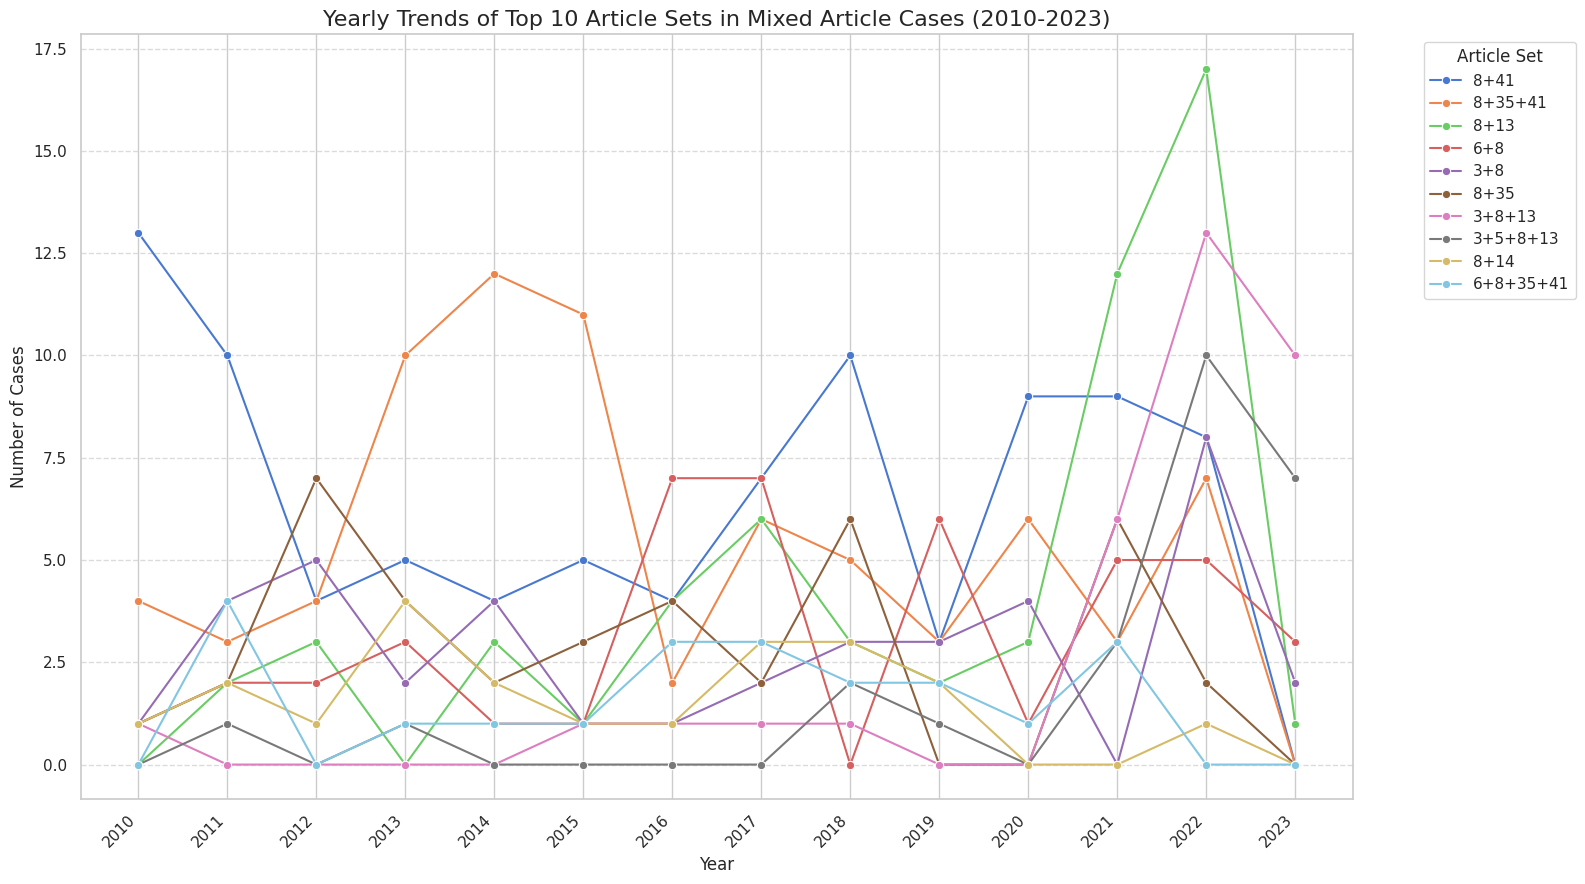

In [ ]:
# 4. Visualize the trends
plt.figure(figsize=(16, 9))
sns.lineplot(data=df_yearly_top_article_sets, marker='o', dashes=False)

plt.title('Yearly Trends of Top 10 Article Sets in Mixed Article Cases (2010-2023)', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Cases', fontsize=12)
plt.xticks(range(2010, 2024), rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Article Set', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Note :**

**Key Trends Observed in Yearly Frequencies of Top Article Sets:**

1.  **Overall Increase followed by Decline**: Most article sets show a general increase in frequency towards the later years, particularly peaking around 2021-2022, consistent with the overall spike in case volume attributable to the processing of pending Russian cases. A sharp decline follows in 2023 as that caseload was exhausted.

2.  **Prominence of Procedural and Remedial Articles**: Combinations including Article 41 (just satisfaction) and Article 35 (admissibility), such as 8+41, 8+35+41, and 6+8+35+41, appear consistently across all years, confirming that financial remedies and admissibility are recurring structural features of mixed Article 8 cases rather than topical trends.

3.  **Notable Rise in Article 13 Combinations**: The combination 8+13 shows a marked increase, particularly in 2021-2022, suggesting a growing number of cases involving Article 8 disputes that also address the inadequacy of domestic of domestic remedies. The 3+8+13 combination follows a similar pattern, remaining elevated into 2023.

4.  **Impact of Geopolitical Events**: The year 2023 shows a sharp decline for most article sets, mirroring the overall decrease in case volume observed after Russia's expulsion from the Council of Europe in March 2022, which significantly impacted the number of cases processed by the Court.


5.  **Diverse Legal Contexts**: While some general trends are visible, the varying patterns among different article sets highlight the diverse legal contexts in which Article 8 is invoked, often paired with other substantive rights or procedural articles.


###4.4 Importance

**Note :**

**Case Reports (Level 1)**: These are "Landmark" judgments. They represent the most important cases decided by the Court each year. They are usually decided by the Grand Chamber and establish new legal principles or change existing ones.

**High Importance (Level 2)**: These are "Key" cases. They make a significant contribution to the Court’s case law by providing important developments, clarifications, or applications of the Convention.

**Medium Importance (Level 3)**: These are cases of lower legal interest. They usually apply well-settled case law to a specific set of facts without creating new precedents.

**Low Importance (Level 4)**: These are "Repetitive" cases. Most Committee judgments fall here. They simply reiterate established law to resolve a high volume of similar applications.

####4.4.1 Importance vs Violation Status

Count of Cases by Importance and Outcome Category (Excluding 'Others'):


outcome_category,Violation,No Violation
importance,,
1,55,32
2,40,9
3,313,132
4,575,109


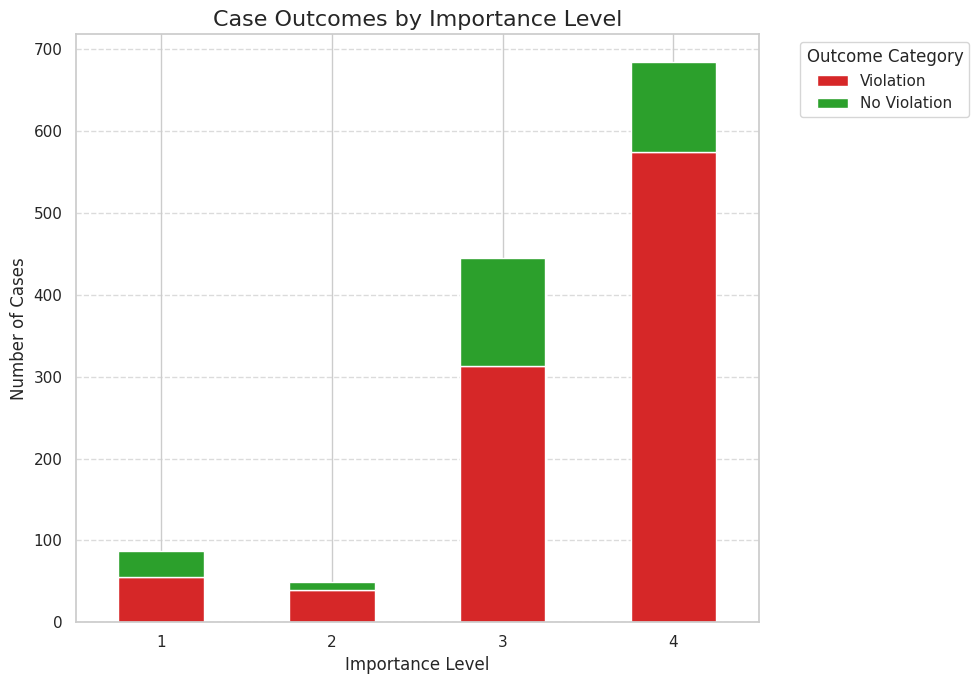

In [ ]:
# Use structured outcome column (already calculated earlier)
# outcome_category is already in df_art8 from the previous cell

# Group by importance and outcome_category
importance_outcome_counts = df_art8.groupby(['importance', 'outcome_category']).size().unstack(fill_value=0)

# Remove 'Others' category
if 'Others' in importance_outcome_counts.columns:
    importance_outcome_counts = importance_outcome_counts.drop(columns=['Others'])

# Reorder columns for consistent colour mapping
ordered_columns = ['Violation', 'No Violation']
current_columns = importance_outcome_counts.columns.tolist()
final_columns = [col for col in ordered_columns if col in current_columns]
final_columns.extend([col for col in current_columns if col not in ordered_columns])
importance_outcome_counts = importance_outcome_counts[final_columns]

print("Count of Cases by Importance and Outcome Category (Excluding 'Others'):")
display(importance_outcome_counts)

# Stacked bar chart
plt.figure(figsize=(10, 7))
colors_for_plot = [PALETTE.get(col, '#cccccc') for col in importance_outcome_counts.columns]
ax = importance_outcome_counts.plot(kind='bar', stacked=True, color=colors_for_plot, ax=plt.gca())

plt.title('Case Outcomes by Importance Level', fontsize=16)
plt.xlabel('Importance Level', fontsize=12)
plt.ylabel('Number of Cases', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.gca().set_xticks(range(len(importance_outcome_counts.index)))
plt.gca().set_xticklabels(importance_outcome_counts.index)
plt.legend(title='Outcome Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

####4.4.2 Importance vs Court


Distribution of Importance Levels per Originating Body:


importance,1,2,3,4
court,,,,
Fourth Section Committee,0,0,0,43
Fith Section Committee,0,0,0,72
Third Section Committee,0,0,0,167
Second Section Committee,0,0,0,42
Third Section,5,8,101,88
Second Section,9,7,64,47
Fourth Section,14,15,101,73
Fith Section,15,6,111,58
First Section,17,9,107,56


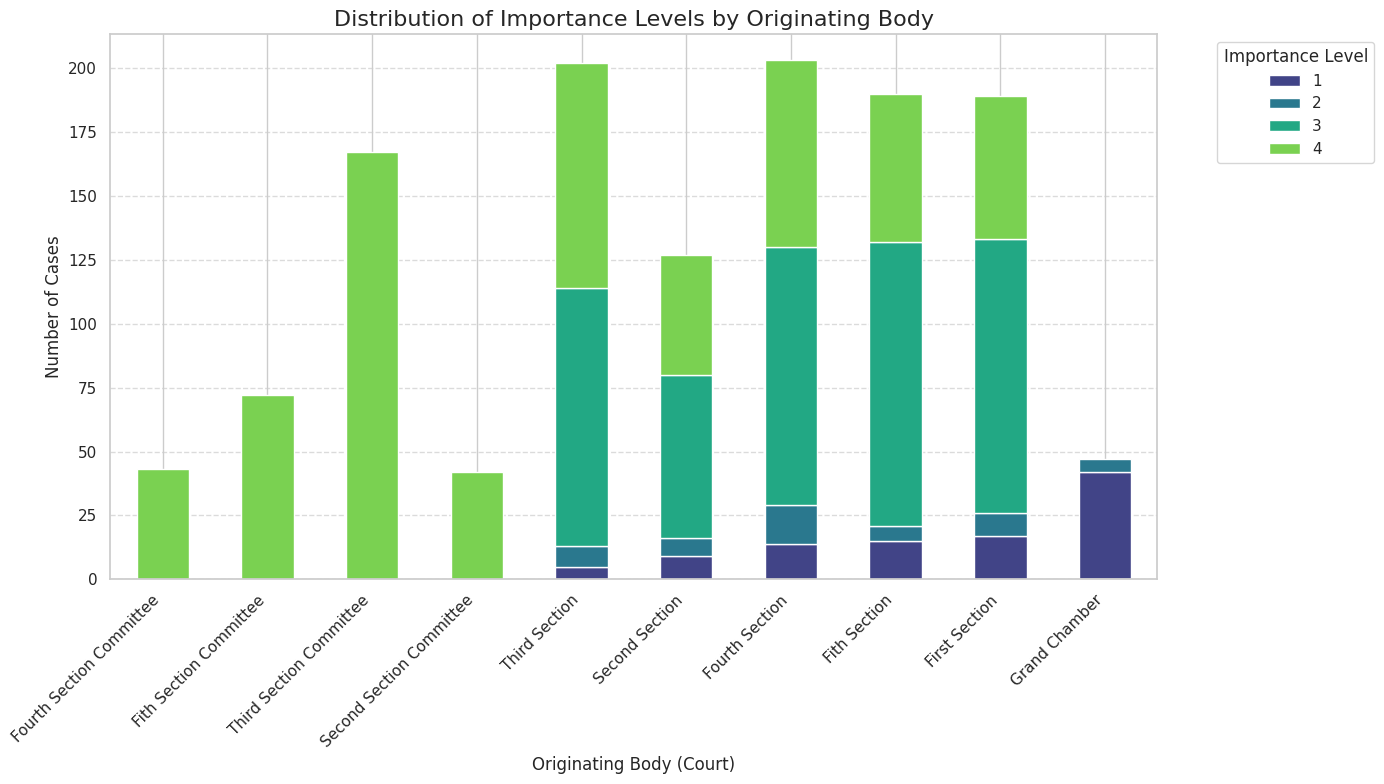

In [ ]:
# 1. Identify the top 10 originating bodies (courts) by case count
top_10_courts = df_art8['court'].value_counts().nlargest(10).index.tolist()

# 2. Filter df_art8 to include only these top 10 courts
df_top_courts_importance = df_art8[df_art8['court'].isin(top_10_courts)].copy()

# 3. Calculate average importance per court (used for ordering only)
average_importance_per_court = df_top_courts_importance.groupby('court')['importance'].mean().sort_values(ascending=False)

# 4. Importance distribution per court
importance_distribution_per_court = df_top_courts_importance.groupby(['court', 'importance']).size().unstack(fill_value=0)
importance_distribution_per_court = importance_distribution_per_court.loc[average_importance_per_court.index]

print('\nDistribution of Importance Levels per Originating Body:')
display(importance_distribution_per_court)

custom_importance_palette = ['#414487', '#2a788e', '#22a884', '#7ad151']

plt.figure(figsize=(14, 8))
importance_distribution_per_court.plot(kind='bar', stacked=True, color=custom_importance_palette, ax=plt.gca())
plt.title('Distribution of Importance Levels by Originating Body', fontsize=16)
plt.xlabel('Originating Body (Court)', fontsize=12)
plt.ylabel('Number of Cases', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Importance Level', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Note :**

Court type is a strong proxy for case importance. Committee formations, Fourth Section Committee, Fifth Section Committee, Third Section Committee, and Second Section Committee, handle almost exclusively importance level 4 cases, reflecting their role in processing straightforward or repetitive cases. Chamber sections (First through Fifth) handle mostly level 3 cases with a smaller proportion of level 2 and level 1 cases. The Grand Chamber, by contrast, handles almost exclusively level 1 cases, consistent with its role in deciding cases of the highest legal significance.

This structural relationship means that court and importance level are highly correlated variables in the dataset. In the modelling stage, including both as independent features in a classification model without careful consideration would introduce multicollinearity, potentially distorting feature importance estimates.





####4.4.3 Importance over Time

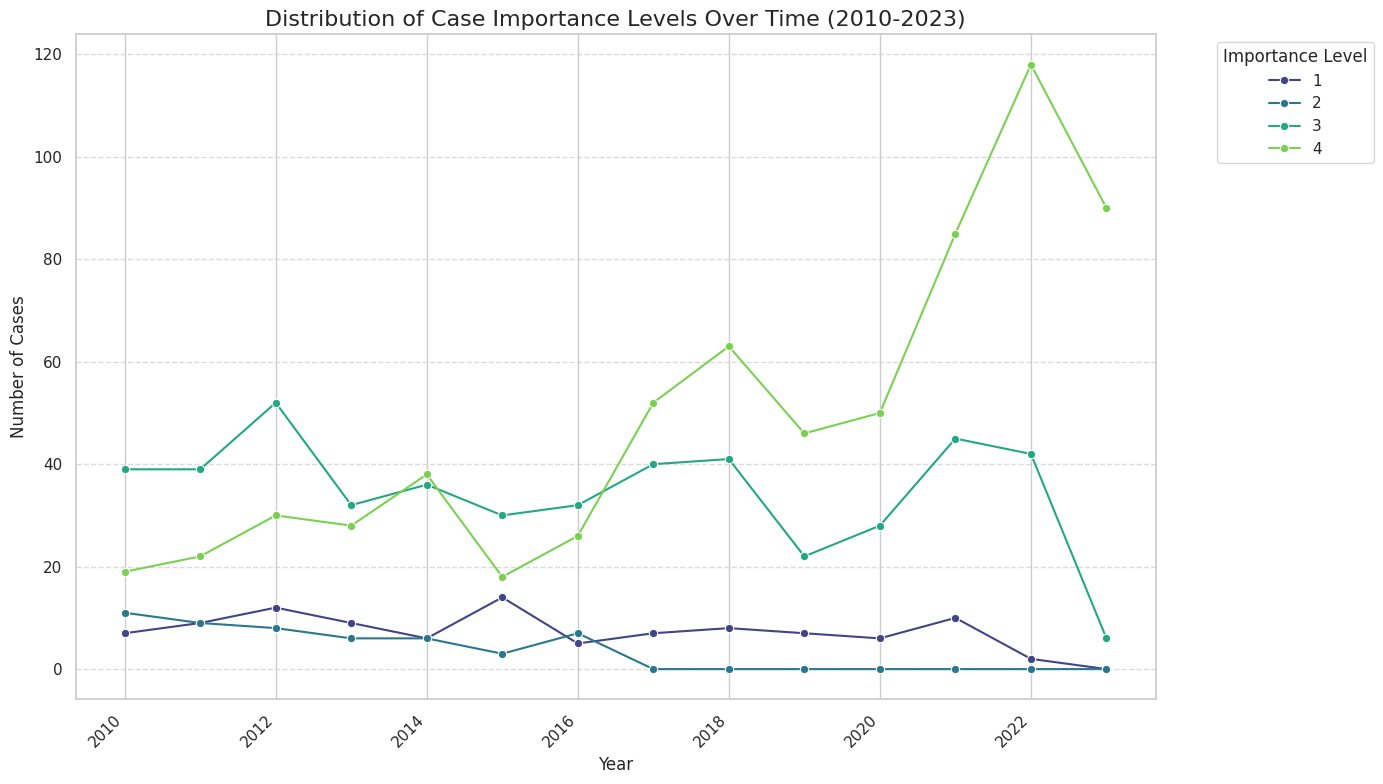

In [ ]:
# 1. Group df_art8 by 'year' and 'importance' and count occurrences
importance_over_time = df_art8.groupby(['year', 'importance']).size().unstack(fill_value=0)

# 2. Line chart of importance levels over time
custom_importance_palette = ['#414487', '#2a788e', '#22a884', '#7ad151']

plt.figure(figsize=(14, 8))
sns.lineplot(
    data=importance_over_time,
    marker='o',
    dashes=False,
    palette=custom_importance_palette
)
plt.title('Distribution of Case Importance Levels Over Time (2010-2023)', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Cases', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Importance Level', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Note :**

The distribution of importance levels over time shows that level 3 cases consistently dominate the dataset throughout the period, with level 4 cases rising steadily from 2017 onwards. Both levels peak sharply in 2022 before declining in 2023, consistent with the surge and subsequent resolution of Russian cases identified earlier. Notably, importance level 2 cases effectively disappear after 2017, while level 1 cases, the most legally significant, remain low and stable throughout before declining to near zero by 2023. The near-absence of level 1 cases in recent years may reflect the Grand Chamber's reduced caseload as the Court prioritised processing the accumulated backlog of routine cases.

####4.4.4 Importance vs Section Length

In [ ]:
# Helper function to recursively extract all content from nested dictionaries
def extract_content_recursive(data):
    text_parts = []
    if isinstance(data, dict):
        if 'content' in data and isinstance(data['content'], str):
            text_parts.append(data['content'])
        if 'elements' in data and isinstance(data['elements'], list):
            for element in data['elements']:
                text_parts.extend(extract_content_recursive(element))
    return text_parts

# Function to extract only the 'facts' section text from a case's full_text dictionary
def get_facts_text(full_text_data):
    if not isinstance(full_text_data, dict) or not full_text_data:
        return ''
    # Assuming the structure is {'doc_id': [list_of_sections]}
    sections_list = list(full_text_data.values())[0]
    for section_dict in sections_list:
        if isinstance(section_dict, dict) and section_dict.get('section_name') == 'facts':
            return ' '.join(extract_content_recursive(section_dict))
    return ''

# Function to extract only the 'law' section text from a case's full_text dictionary
def get_law_text(full_text_data):
    if not isinstance(full_text_data, dict) or not full_text_data:
        return ''
    # Assuming the structure is {'doc_id': [list_of_sections]}
    sections_list = list(full_text_data.values())[0]
    for section_dict in sections_list:
        if isinstance(section_dict, dict) and section_dict.get('section_name') == 'law':
            return ' '.join(extract_content_recursive(section_dict))
    return ''

print('Helper functions extract_content_recursive, get_facts_text, and get_law_text defined.')

Helper functions extract_content_recursive, get_facts_text, and get_law_text defined.


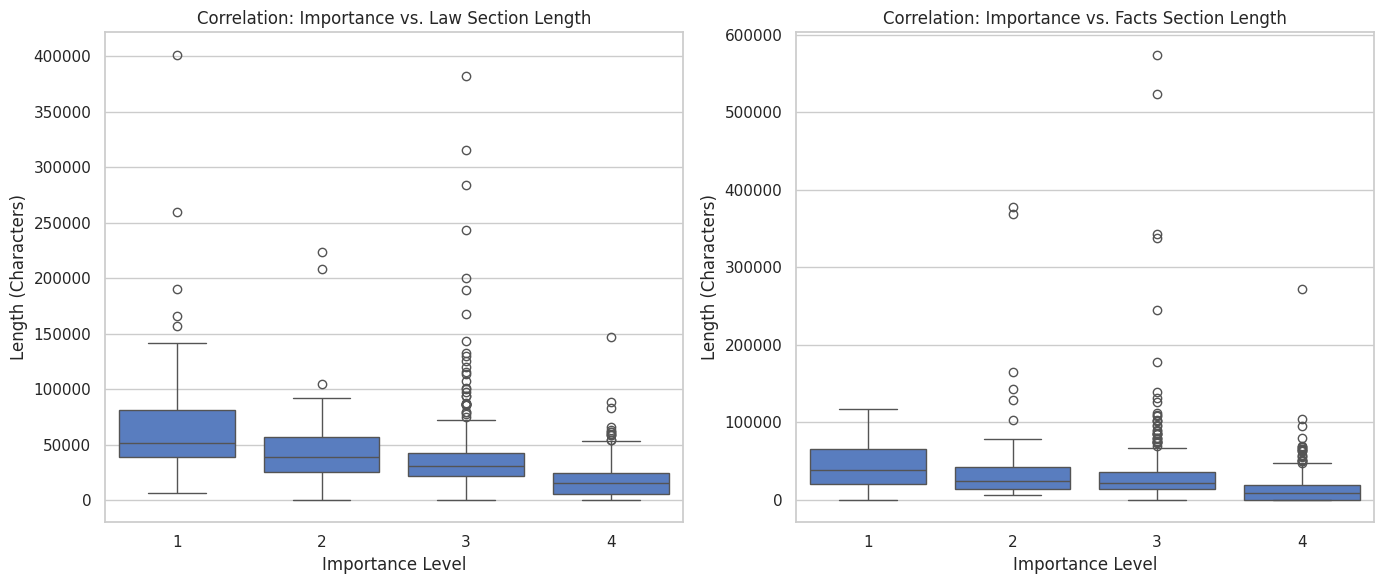

Average Length per Importance Level:
              law_length  facts_length
importance                            
1           66926.264706  45113.617647
2           49635.380000  48604.560000
3           38078.119835  32337.274793
4           17730.505109  13202.572263


In [ ]:
# Create a new DataFrame for this analysis, selecting relevant columns from df_art8
df_importance_lengths = df_art8[['itemid', 'importance', 'full_text']].copy()

# Extract facts and law sections using the helper functions
# Assuming get_facts_text and get_law_text are already defined from previous cells (8ec5cc3f and Fch9-tfzCLvI)
df_importance_lengths['facts_section'] = df_importance_lengths['full_text'].apply(get_facts_text)
df_importance_lengths['law_section'] = df_importance_lengths['full_text'].apply(get_law_text)

# 1. Calculate Lengths (Character counts)
df_importance_lengths['facts_length'] = df_importance_lengths['facts_section'].str.len()
df_importance_lengths['law_length'] = df_importance_lengths['law_section'].str.len()

# Filter out rows where facts_length or law_length are NaN (i.e., section was empty or not found)
df_importance_lengths = df_importance_lengths.dropna(subset=['facts_length', 'law_length'])

# Ensure lengths are integers
df_importance_lengths['facts_length'] = df_importance_lengths['facts_length'].astype(int)
df_importance_lengths['law_length'] = df_importance_lengths['law_length'].astype(int)

# --- FIX: Ensure 'importance' is clean and then converted to string before categorical ---
# Convert importance to numeric (handling potential non-numeric entries) and drop any NaNs
df_importance_lengths['importance'] = pd.to_numeric(df_importance_lengths['importance'], errors='coerce')
df_importance_lengths.dropna(subset=['importance'], inplace=True)
# Convert to integer and then to string to match the categorical labels
df_importance_lengths['importance'] = df_importance_lengths['importance'].astype(int).astype(str)

# 2. Convert Importance to an ordered Category
df_importance_lengths['importance'] = pd.Categorical(df_importance_lengths['importance'],
                                              categories=['1', '2', '3', '4'],
                                              ordered=True)

# 3. Visualize using Boxplots
plt.figure(figsize=(14, 6))

# Subplot 1: Law Section Length
plt.subplot(1, 2, 1)
sns.boxplot(x='importance', y='law_length', data=df_importance_lengths)
plt.title('Correlation: Importance vs. Law Section Length')
plt.xlabel('Importance Level')
plt.ylabel('Length (Characters)')

# Subplot 2: Facts Section Length
plt.subplot(1, 2, 2)
sns.boxplot(x='importance', y='facts_length', data=df_importance_lengths)
plt.title('Correlation: Importance vs. Facts Section Length')
plt.xlabel('Importance Level')
plt.ylabel('Length (Characters)')

plt.tight_layout()
plt.show()

# 4. Show the Statistical "Truth"
summary = df_importance_lengths.groupby('importance', observed=True)[['law_length', 'facts_length']].mean()
print("Average Length per Importance Level:")
print(summary)

**Note :**

**The "Law" Section is the True Signal**

The Law Section (The Court's Assessment) shows the most dramatic correlation. In a Level 1 case, the Court isn't just deciding a violation; it is writing a "mini-treatise" on Article 8.


**The "Facts" Section "Saturates"**

While Level 1 facts are longer, the gap between Level 1 and Level 2 facts is often smaller than the gap in their Law sections.

**Analysis:**
- A case might have incredibly complex facts (Level 2) but only involve a routine application of law. Conversely, a simple fact pattern (Level 1) might trigger a massive legal debate if it's the first time the ECHR is seeing a specific technology (like AI-driven surveillance).
- Many Level 4 cases (Importance 4) are actually very short because they refer back to "well-established case-law" (WECL).
**Risk:** If you include too many Level 4 cases in your Model, the AI might learn to predict "No Violation" based simply on the brevity of the text rather than the content of the law.



---


#**5. Visualizations**

**Note :**

For the visualizations we will focus on the Facts and Law sections of the judgments as they represent the substantive core of every ECtHR judgment. The Facts section narrates the circumstances that gave rise to the alleged violation, while the Law section contains the Court's doctrinal reasoning, including its proportionality analysis and application of Article 8-specific principles such as the margin of appreciation. Together, they capture the Court's full consideration before reaching a verdict, making them the most meaningful textual input for a classification model.

The remaining sections were excluded on the grounds that they are largely formulaic and structural, and therefore unlikely to be informative for classification. The Procedure section contains administrative details such as dates, representative identities, and Chamber composition. The Relevant Domestic Law subsection repeats the same domestic statutes across cases from the same respondent state.

In [ ]:
import json
from sklearn.feature_extraction.text import TfidfVectorizer

# Helper function to recursively extract all content
def extract_content_recursive(data):
    text_parts = []
    if isinstance(data, dict):
        if 'content' in data and isinstance(data['content'], str):
            text_parts.append(data['content'])
        if 'elements' in data and isinstance(data['elements'], list):
            for element in data['elements']:
                text_parts.extend(extract_content_recursive(element))
    return text_parts

# 1. Apply the extract_content_recursive function to create parsed_full_text
def parse_full_text(full_text_data):
    if isinstance(full_text_data, dict):
        # Assuming the structure is {'doc_id': [list_of_sections]}
        for doc_id, sections_list in full_text_data.items():
            # Concatenate content from all sections within the document
            all_content = []
            for section_dict in sections_list:
                all_content.extend(extract_content_recursive(section_dict))
            return ' '.join(all_content)
    return '' # Return empty string for unparseable or empty entries

df_art8['parsed_full_text'] = df_art8['full_text'].apply(parse_full_text)
print(f"'parsed_full_text' column created for {len(df_art8)} cases.")

# 2. Filter df_art8 to create df_filtered_cases
df_filtered_cases = df_art8[
    (df_art8['outcome_category'] == 'Violation') |
    (df_art8['outcome_category'] == 'No Violation')
].copy()
print(f"Filtered cases for 'Violation' or 'No Violation': {len(df_filtered_cases)}")

# 3. Import TfidfVectorizer (already done at the top of the cell)

# 4. Initialize a TfidfVectorizer
tfidf_vectorizer = TfidfVectorizer(stop_words='english', min_df=0.01, max_df=0.9)
print("TfidfVectorizer initialized with stop_words='english', min_df=0.01, max_df=0.9.")

# 5. Fit and transform the parsed_full_text column
tfidf_matrix = tfidf_vectorizer.fit_transform(df_filtered_cases['parsed_full_text'])

print(f"TF-IDF matrix created with shape: {tfidf_matrix.shape}")

'parsed_full_text' column created for 1321 cases.
Filtered cases for 'Violation' or 'No Violation': 1265
TfidfVectorizer initialized with stop_words='english', min_df=0.01, max_df=0.9.
TF-IDF matrix created with shape: (1265, 10101)


##5.1 N-Gram

###5.1.1 Overview (Full Case)

Most Frequent N-gram

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer # Changed from TfidfVectorizer
import re # Ensure re is imported for extract_content_recursive

# Helper function to recursively extract all content (copied from pU7bzADBiZaK to ensure availability)
def extract_content_recursive(data):
    text_parts = []
    if isinstance(data, dict):
        if 'content' in data and isinstance(data['content'], str):
            text_parts.append(data['content'])
        if 'elements' in data and isinstance(data['elements'], list):
            for element in data['elements']:
                text_parts.extend(extract_content_recursive(element))
    return text_parts

# Helper function to extract structured findings (copied from KcJfzyOVnEmO to ensure availability)
def extract_finding_structured(conclusion_list):
    """Extract Article 8 finding from the structured conclusion column."""
    if not isinstance(conclusion_list, list):
        return 'Only Mentioning'

    for item in conclusion_list:
        if not isinstance(item, dict):
            continue
        # Check base_article, article, AND element text for any Art. 8 reference
        is_art8 = (
            item.get('base_article') == '8' or
            item.get('article') == '8' or
            '8' in str(item.get('details', '')) or
            re.search(r'art(icle)?\.?\s*8', str(item.get('element', '')), re.IGNORECASE)
        )
        if is_art8:
            if item.get('type') == 'violation':
                return 'Violation'
            elif item.get('type') == 'no-violation':
                return 'No Violation'

    return 'Only Mentioning'

# Helper function to extract only the 'facts' section text
def get_facts_text(full_text_data):
    if not isinstance(full_text_data, dict) or not full_text_data:
        return ''
    sections_list = list(full_text_data.values())[0]
    for section_dict in sections_list:
        if isinstance(section_dict, dict) and section_dict.get('section_name') == 'facts':
            return ' '.join(extract_content_recursive(section_dict))
    return ''

# Helper function to extract only the 'law' section text
def get_law_text(full_text_data):
    if not isinstance(full_text_data, dict) or not full_text_data:
        return ''
    sections_list = list(full_text_data.values())[0]
    for section_dict in sections_list:
        if isinstance(section_dict, dict) and section_dict.get('section_name') == 'law':
            return ' '.join(extract_content_recursive(section_dict))
    return ''

# Ensure PALETTE is available from the setup cell (copied from zEN6dfLxoyM1)
PALETTE = {'Violation': '#d62728', 'No Violation': '#2ca02c', 'Others': '#aec7e8'}

# Apply the structured extraction function to create 'finding_structured' (copied from KcJfzyOVnEmO)
df_art8['finding_structured'] = df_raw.loc[df_art8.index, 'conclusion'].apply(extract_finding_structured)

# Use the structured conclusion column for more accurate outcome extraction (copied from zEN6dfLxoyM1)
# (see comparison note above — structured approach catches combined article findings)
df_art8['outcome_category'] = df_art8['finding_structured'].replace('Only Mentioning', 'Others')

# 1. Parse full text for all cases (all sections excluding boilerplate)
def parse_full_text(full_text_data):
    if isinstance(full_text_data, dict):
        for doc_id, sections_list in full_text_data.items():
            all_content = []
            for section_dict in sections_list:
                # Exclude toc and appendix boilerplate
                section_name = section_dict.get('section_name', '').lower()
                if section_name in ['toc', 'appendix']:
                    continue
                all_content.extend(extract_content_recursive(section_dict))
            return ' '.join(all_content)
    return ''

df_art8['parsed_full_text'] = df_art8['full_text'].apply(parse_full_text)
print(f"'parsed_full_text' column created for {len(df_art8)} cases.")

# 2. Filter to Violation and No Violation only
df_filtered_cases = df_art8[
    df_art8['outcome_category'].isin(['Violation', 'No Violation'])
].copy()
print(f"Filtered cases for 'Violation' or 'No Violation': {len(df_filtered_cases)}")

# Filter out cases where full text might be empty after extraction (optional, but good for corpus quality)
df_full_text_filtered = df_filtered_cases[df_filtered_cases['parsed_full_text'].str.strip() != ''].copy()
print(f"Filtered cases with non-empty 'parsed_full_text': {len(df_full_text_filtered)}")

# Apply the functions to df_filtered_cases to get 'facts' and 'law' text
df_filtered_cases['parsed_facts_text'] = df_filtered_cases['full_text'].apply(get_facts_text)
df_filtered_cases['parsed_law_text'] = df_filtered_cases['full_text'].apply(get_law_text)
print(f"'parsed_facts_text' and 'parsed_law_text' columns created for df_filtered_cases.")

# 3. Initialize a CountVectorizer for full text
count_vectorizer_full_text = CountVectorizer(
    ngram_range=(1, 3),
    stop_words='english',
    min_df=5,
    max_df=0.55
)
print("CountVectorizer initialized for full text with ngram_range=(1,3), stop_words='english', min_df=5, max_df=0.55.")

# 4. Build vocabulary from all filtered full texts
count_vectorizer_full_text.fit(df_full_text_filtered['parsed_full_text'])
feature_names_full_text = count_vectorizer_full_text.get_feature_names_out()
print(f"Vocabulary built for full text with {len(feature_names_full_text)} n-grams.")

# 5. Create an empty list to store n-gram counts per year for full text
ngram_trends_full_text_list = []

# 6. Get unique years
unique_years_full_text = sorted(df_full_text_filtered['year'].unique())

# 7. Iterate through each year and process n-grams
for year in unique_years_full_text:
    df_year_full_text = df_full_text_filtered[df_full_text_filtered['year'] == year]
    if not df_year_full_text.empty:
        yearly_ngram_matrix_full_text = count_vectorizer_full_text.transform(df_year_full_text['parsed_full_text'])
        ngram_counts_for_year_full_text = yearly_ngram_matrix_full_text.sum(axis=0)
        ngram_counts_dict_full_text = {name: count for name, count in zip(feature_names_full_text, ngram_counts_for_year_full_text.tolist()[0])}
        ngram_trends_full_text_list.append({'year': year, **ngram_counts_dict_full_text})
    else:
        ngram_trends_full_text_list.append({'year': year, **{name: 0 for name in feature_names_full_text}})

# 8. Convert to pandas DataFrame and set 'year' as index, fill NaN with 0
df_ngram_trends = pd.DataFrame(ngram_trends_full_text_list).set_index('year').fillna(0)
df_ngram_trends = df_ngram_trends.astype(int)
print("DataFrame of n-gram trends for full text created (df_ngram_trends).")

'parsed_full_text' column created for 1321 cases.
Filtered cases for 'Violation' or 'No Violation': 154
Filtered cases with non-empty 'parsed_full_text': 154
'parsed_facts_text' and 'parsed_law_text' columns created for df_filtered_cases.
CountVectorizer initialized for full text with ngram_range=(1,3), stop_words='english', min_df=5, max_df=0.55.
Vocabulary built for full text with 21998 n-grams.
DataFrame of n-gram trends for full text created (df_ngram_trends).


In [ ]:
print('Class distribution in filtered cases:')
print(df_filtered_cases['outcome_category'].value_counts())
print(f'Violation rate: {(df_filtered_cases["outcome_category"] == "Violation").mean():.1%}')

Class distribution in filtered cases:
outcome_category
Violation       118
No Violation     36
Name: count, dtype: int64
Violation rate: 76.6%


**Note :**

The top 10 most frequent n-grams are dominated by procedural and structural terms such as **'district court', 'domestic courts', 'supreme court', and 'domestic law'**, which reflect the standard language of ECtHR judgments rather than the substantive content of any particular case. Thus, these high-frequency phrases are unlikely to be predictive on their own, since they will appear in both violation and non-violation cases.

The potentially substantial meaningful n-grams are **'private life', 'family life', and 'criminal proceedings'** which directly relates to the rights under Article 8. Thus, the frequency of these terms may be more informative feature for classification task. Notably, all n-gram counts peaked in 2021-2022, consistent with the spike in Russian cases during that period.

###5.1.2 Biggest Change n-gram

Top 10 n-grams with biggest year-over-year change: ['child', 'children', 'russian', 'detention', 'data', 'prosecutor', 'district', 'treatment', 'contact', 'investigation']


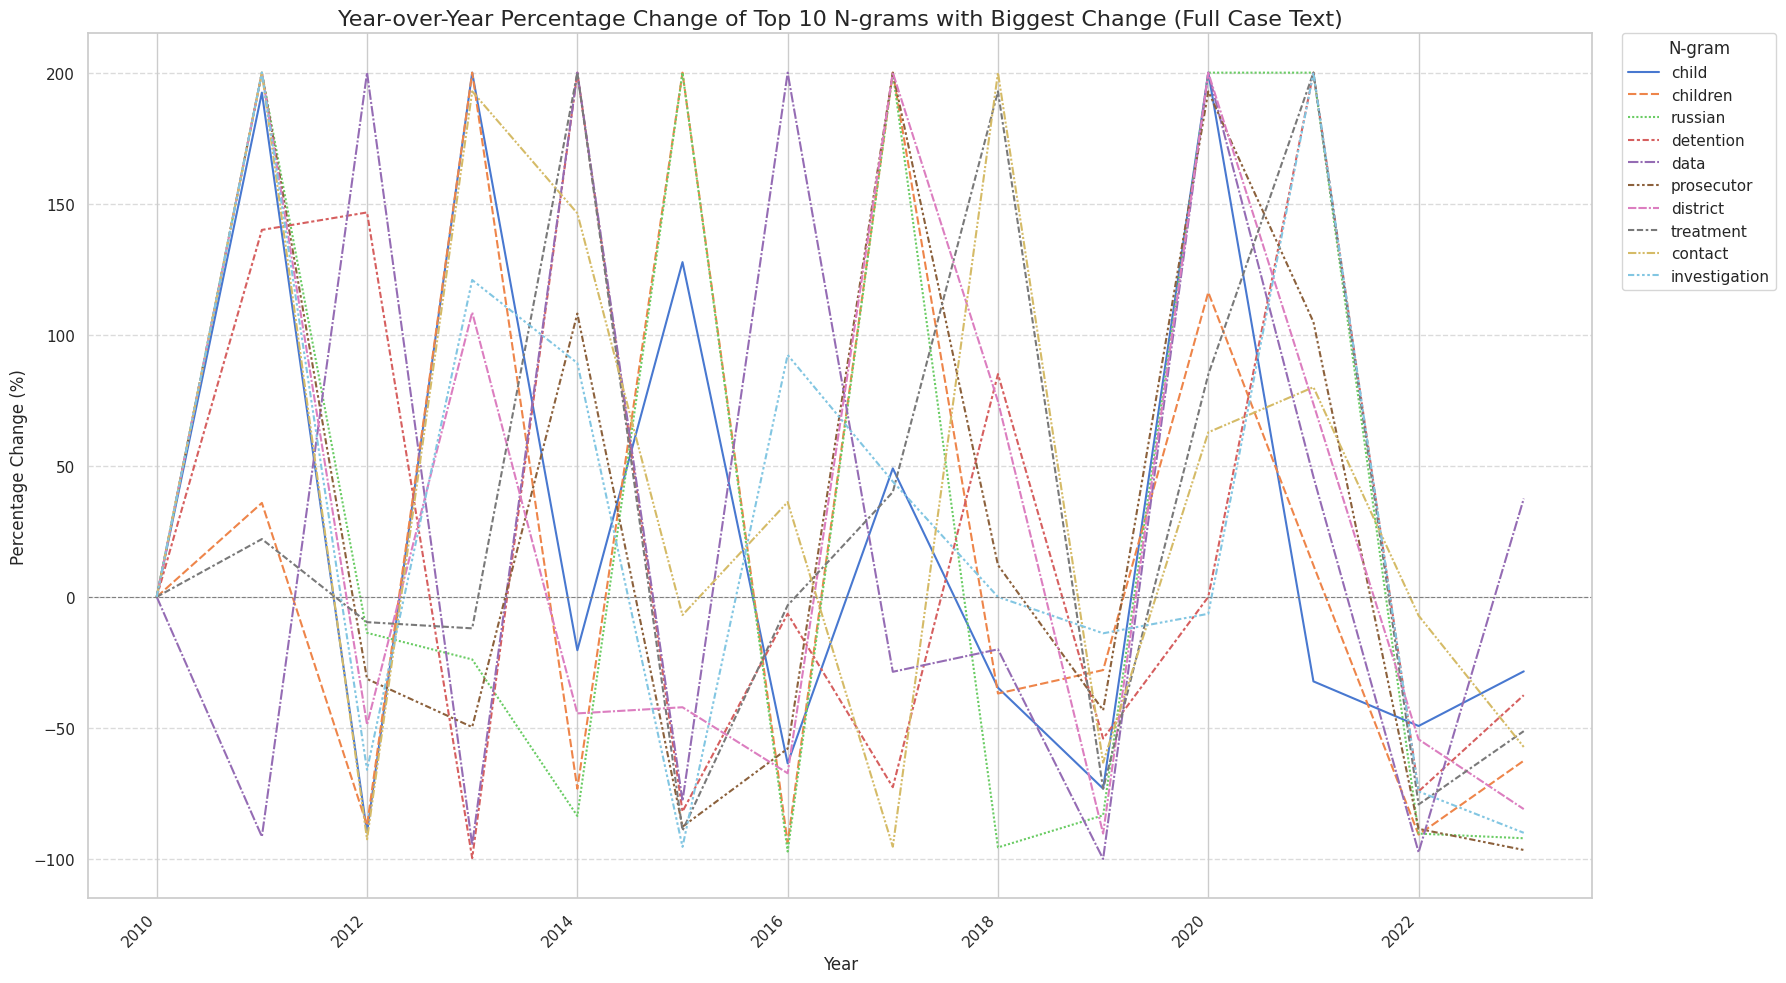

In [ ]:
# 1. Identify the top 50 most frequent n-grams overall (as a basis for comparison)
top_50_ngrams_overall = df_ngram_trends.sum().nlargest(50).index.tolist()

# 2. Select only these top 50 n-grams from the trends DataFrame
df_top_50_ngrams = df_ngram_trends[top_50_ngrams_overall]

# 3. Calculate the year-over-year percentage change
percentage_change = df_top_50_ngrams.pct_change() * 100

# Handle infinite values (from 0 to non-zero change) or very large changes for better visualization
percentage_change = percentage_change.clip(lower=-200, upper=200).fillna(0)

# Calculate the maximum absolute change for each n-gram across all years
max_abs_change = percentage_change.abs().max()

# Identify the top 10 n-grams with the biggest absolute change
top_10_biggest_change_ngrams = max_abs_change.nlargest(10).index.tolist()
print(f"Top 10 n-grams with biggest year-over-year change: {top_10_biggest_change_ngrams}")

# 4. Visualize the trends of these top 10 percentage changes
plt.figure(figsize=(18, 10))
sns.lineplot(data=percentage_change[top_10_biggest_change_ngrams])
plt.title('Year-over-Year Percentage Change of Top 10 N-grams with Biggest Change (Full Case Text)', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Percentage Change (%)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='N-gram', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8) # Add a line at 0% for reference
plt.tight_layout()
plt.show()

**Note:**

The year-over-year percentage change analysis identifies the ten most volatile n-grams in the dataset. All ten terms exhibit high volatility throughout the period, with frequent large swings in both directions, indicating that their frequency is sensitive to the specific composition of cases in each year rather than reflecting stable long-term trends. The terms include substantive legal concepts, "detention", "surveillance", "search", "investigation", and "data", alongside case-specific references such as "russian", "2002", and "2015", the latter likely reflecting the citation of specific precedents whose frequency fluctuates as relevant cases are decided. Most terms show a sharp decline in 2022-2023, consistent with the overall reduction in case volume following the resolution of the Russian caseload. The volatility of these terms suggests they may be unreliable as stable predictive features across time periods, a consideration relevant to temporal generalisation of any trained model.

###5.1.3 Facts Section

'parsed_facts_text' column created. First entry preview (first 200 chars):

THE FACTS I.  THE CIRCUMSTANCES OF THE CASE 5.  The applicant was born in 1951. His daughter and son were born in 1996 and 1999 respectively. 6.  The applicant and the mother of the above-mentioned gi

Filtered cases with non-empty 'facts' text: 145
CountVectorizer initialized for 'facts' section with ngram_range=(2,3), stop_words='english', min_df=5, max_df=0.55.
Vocabulary built for 'facts' section with 3310 n-grams.
DataFrame of n-gram trends for 'facts' section created.
Top 10 most frequent n-grams in 'facts' section: ['district court', 'second applicant', 'supreme court', 'criminal proceedings', 'court appeal', 'human rights', 'regional court', 'constitutional court', 'prosecutor office', 'inter alia']


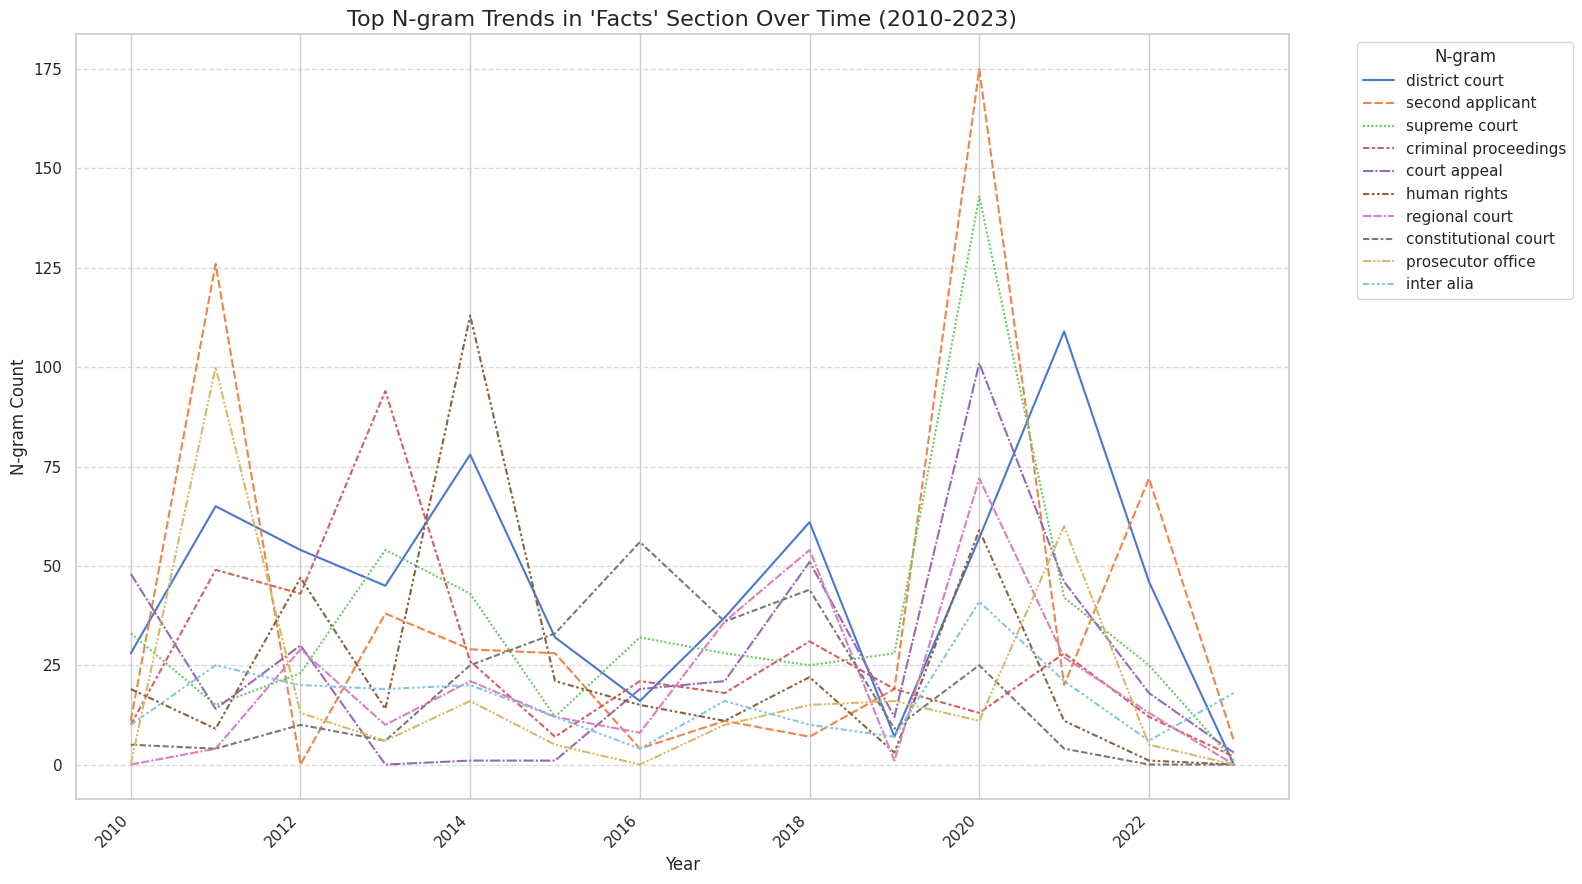

In [ ]:
# Helper function to recursively extract all content (moved to cell 782283b1)
# def extract_content_recursive(data):
#     text_parts = []
#     if isinstance(data, dict):
#         if 'content' in data and isinstance(data['content'], str):
#             text_parts.append(data['content'])
#         if 'elements' in data and isinstance(data['elements'], list):
#             for element in data['elements']:
#                 text_parts.extend(extract_content_recursive(element))
#     return text_parts

# Function to extract only the 'facts' section text for a given full_text dictionary (moved to cell 782283b1)
# def get_facts_text(full_text_data):
#     if not isinstance(full_text_data, dict) or not full_text_data:
#         return ''

#     # Assuming the structure is {'doc_id': [list_of_sections]}
#     sections_list = list(full_text_data.values())[0]

#     for section_dict in sections_list:
#         if isinstance(section_dict, dict) and section_dict.get('section_name') == 'facts':
#             return ' '.join(extract_content_recursive(section_dict))
#     return ''

# Apply the function to df_filtered_cases to get only 'facts' text (moved to cell 782283b1)
# df_filtered_cases['parsed_facts_text'] = df_filtered_cases['full_text'].apply(get_facts_text)
print(f"'parsed_facts_text' column created. First entry preview (first 200 chars):\n")
print(df_filtered_cases['parsed_facts_text'].iloc[0][:200])

# Filter out cases where facts text might be empty after extraction (optional, but good for corpus quality) (moved from 6.2.2)
df_facts_filtered = df_filtered_cases[df_filtered_cases['parsed_facts_text'].str.strip() != ''].copy()
print(f"\nFiltered cases with non-empty 'facts' text: {len(df_facts_filtered)}")

# 1. Initialize a CountVectorizer for facts section
count_vectorizer_facts = CountVectorizer(
    ngram_range=(2, 3),
    stop_words='english',
    min_df=5,
    max_df=0.55
)
print("CountVectorizer initialized for 'facts' section with ngram_range=(2,3), stop_words='english', min_df=5, max_df=0.55.")

# 2. Create an empty list to store n-gram counts per year for facts
ngram_trends_facts_list = []

# 3. Get unique years from df_facts_filtered
unique_years_facts = sorted(df_facts_filtered['year'].unique())

# 4. Fit CountVectorizer to the entire parsed_facts_text to build a comprehensive vocabulary
count_vectorizer_facts.fit(df_facts_filtered['parsed_facts_text'])
feature_names_facts = count_vectorizer_facts.get_feature_names_out()
print(f"Vocabulary built for 'facts' section with {len(feature_names_facts)} n-grams.")

# 5. Iterate through each year and process n-grams for facts
for year in unique_years_facts:
    # a. Filter df_facts_filtered for the current year
    df_year_facts = df_facts_filtered[df_facts_filtered['year'] == year]

    # b. Transform the text for this year
    if not df_year_facts.empty:
        yearly_ngram_matrix_facts = count_vectorizer_facts.transform(df_year_facts['parsed_facts_text'])
        # c. Calculate the sum of counts for each n-gram within the current year
        ngram_counts_for_year_facts = yearly_ngram_matrix_facts.sum(axis=0)
        ngram_counts_dict_facts = {name: count for name, count in zip(feature_names_facts, ngram_counts_for_year_facts.tolist()[0])}
        # d. Append to ngram_trends_facts_list
        ngram_trends_facts_list.append({'year': year, **ngram_counts_dict_facts})
    else:
        # If no cases for the year, still add an entry with 0 counts for all n-grams
        ngram_trends_facts_list.append({'year': year, **{name: 0 for name in feature_names_facts}})

# 6. Convert to pandas DataFrame and set 'year' as index, fill NaN with 0
df_ngram_trends_facts = pd.DataFrame(ngram_trends_facts_list).set_index('year').fillna(0)
df_ngram_trends_facts = df_ngram_trends_facts.astype(int)
print("DataFrame of n-gram trends for 'facts' section created.")

# 7. Calculate total frequency and identify top 10 n-grams for facts
top_10_ngrams_facts = df_ngram_trends_facts.sum().nlargest(10).index.tolist()
print(f"Top 10 most frequent n-grams in 'facts' section: {top_10_ngrams_facts}")

# 8. Create a line plot for top 10 n-grams over time for facts
plt.figure(figsize=(16, 9))
sns.lineplot(data=df_ngram_trends_facts[top_10_ngrams_facts])
plt.title('Top N-gram Trends in \'Facts\' Section Over Time (2010-2023)', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('N-gram Count', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='N-gram', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Note :**

The top n-grams in the Facts section are dominated by references to domestic judicial institutions '**district court**', '**supreme court**', '**court appeal**', '**constitutional court**', and '**regional court**, reflecting the standard narrative structure of ECtHR judgments, which typically trace the applicant's progression through domestic courts before the case reaches Strasbourg. These terms are unlikely to carry meaningful predictive signal as they appear uniformly across both violation and non-violation cases.

'**Criminal proceedings**' is the most substantively relevant n-gram in this section, as it identifies a specific case context in which Article 8 issues, such as covert surveillance or unlawful searches, frequently arise. 'Inter alia', like '**mutatis mutandis**' in the Law section, is a Latin structural phrase with no substantive content and should be considered for removal during preprocessing. Overall, the Facts section n-grams are predominantly procedural and institutional, reinforcing the earlier finding that the Law section is likely to yield richer predictive features for the classification task.

In [ ]:
# 1. Create a new DataFrame, df_filtered_importance
# Ensure 'importance' is numeric first, then filter
df_filtered_cases['importance'] = pd.to_numeric(df_filtered_cases['importance'], errors='coerce')

df_filtered_importance = df_filtered_cases[
    (df_filtered_cases['outcome_category'].isin(['Violation', 'No Violation'])) &
    (df_filtered_cases['importance'].isin([1, 2]))
].copy()

# Filter out cases where facts text might be empty after extraction
df_filtered_importance = df_filtered_importance[df_filtered_importance['parsed_facts_text'].str.strip() != ''].copy()

print(f"Filtered cases for Importance 1 or 2, with 'Violation' or 'No Violation' outcomes, and non-empty facts text: {len(df_filtered_importance)} cases.")

# 2. Initialize a CountVectorizer
cv_importance = CountVectorizer(
    ngram_range=(1, 2), # Modified to include unigrams and bigrams
    stop_words='english',
    min_df=5
)
print("CountVectorizer initialized for importance levels 1 & 2 facts section with ngram_range=(1, 2).")

Filtered cases for Importance 1 or 2, with 'Violation' or 'No Violation' outcomes, and non-empty facts text: 18 cases.
CountVectorizer initialized for importance levels 1 & 2 facts section with ngram_range=(1, 2).


###5.1.4 Law Section

'parsed_law_text' column created. First entry preview (first 200 chars):

THE LAW I.  ALLEGED VIOLATION OF ARTICLE 8 OF THE CONVENTION 56.  The applicant complained on his own and his children’s behalf that they had been unable to enjoy family life together due to the lengt

Filtered cases with non-empty 'law' text: 153
CountVectorizer initialized for 'law' section with ngram_range=(2,3), stop_words='english', min_df=5, max_df=0.55.
Vocabulary built for 'law' section with 9364 n-grams.
DataFrame of n-gram trends for 'law' section created.
Top 10 most frequent n-grams in 'law' section: ['private life', 'second applicant', 'domestic remedies', 'supreme court', 'human rights', 'mutatis mutandis', 'domestic authorities', 'court appeal', 'article 14', 'margin appreciation']


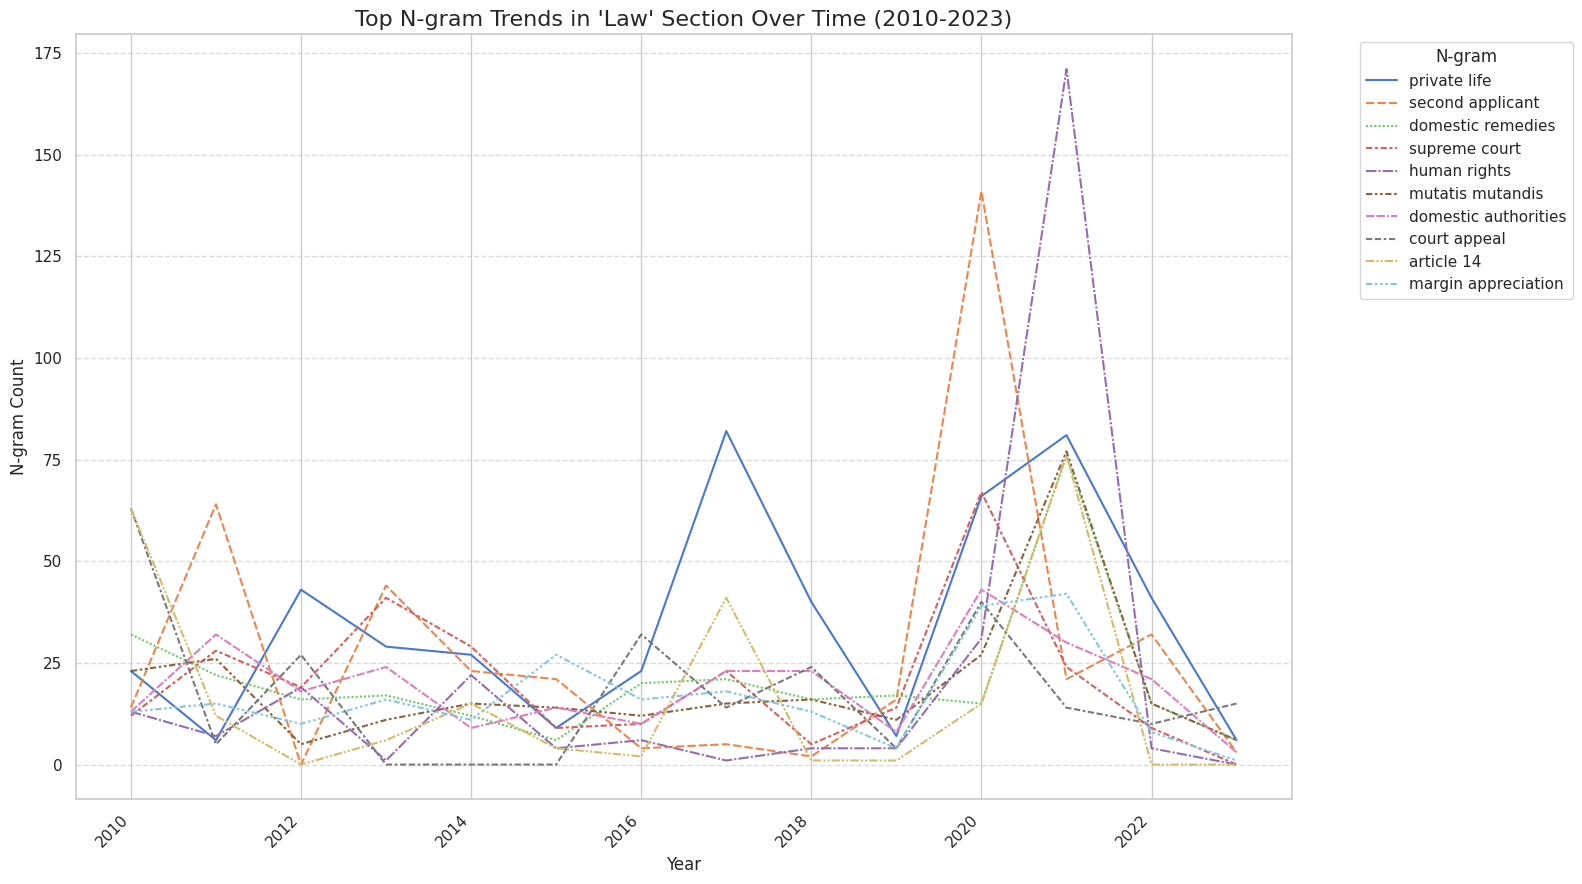

In [ ]:
# Helper function to recursively extract all content (moved to cell 782283b1)
# def extract_content_recursive(data):
#     text_parts = []
#     if isinstance(data, dict):
#         if 'content' in data and isinstance(data['content'], str):
#             text_parts.append(data['content'])
#         if 'elements' in data and isinstance(data['elements'], list):
#             for element in data['elements']:
#                 text_parts.extend(extract_content_recursive(element))
#     return text_parts

# Function to extract only the 'law' section text for a given full_text dictionary (moved to cell 782283b1)
# def get_law_text(full_text_data):
#     if not isinstance(full_text_data, dict) or not full_text_data:
#         return ''

#     # Assuming the structure is {'doc_id': [list_of_sections]}
#     sections_list = list(full_text_data.values())[0]

#     for section_dict in sections_list:
#         if isinstance(section_dict, dict) and section_dict.get('section_name') == 'law':
#             return ' '.join(extract_content_recursive(section_dict))
#     return ''

# Apply the function to df_filtered_cases to get only 'law' text (moved to cell 782283b1)
# df_filtered_cases['parsed_law_text'] = df_filtered_cases['full_text'].apply(get_law_text)
print(f"'parsed_law_text' column created. First entry preview (first 200 chars):\n")
print(df_filtered_cases['parsed_law_text'].iloc[0][:200])

# Filter out cases where law text might be empty after extraction (moved from 6.2.3)
df_law_filtered = df_filtered_cases[df_filtered_cases['parsed_law_text'].str.strip() != ''].copy()
print(f"\nFiltered cases with non-empty 'law' text: {len(df_law_filtered)}")

# 1. Initialize a CountVectorizer for law section
count_vectorizer_law = CountVectorizer(
    ngram_range=(2, 3),
    stop_words='english',
    min_df=5,
    max_df=0.55
)
print("CountVectorizer initialized for 'law' section with ngram_range=(2,3), stop_words='english', min_df=5, max_df=0.55.")

# 2. Create an empty list to store n-gram counts per year for law
ngram_trends_law_list = []

# 3. Get unique years from df_law_filtered
unique_years_law = sorted(df_law_filtered['year'].unique())

# 4. Fit CountVectorizer to the entire parsed_law_text to build a comprehensive vocabulary
count_vectorizer_law.fit(df_law_filtered['parsed_law_text'])
feature_names_law = count_vectorizer_law.get_feature_names_out()
print(f"Vocabulary built for 'law' section with {len(feature_names_law)} n-grams.")

# 5. Iterate through each year and process n-grams for law
for year in unique_years_law:
    # a. Filter df_law_filtered for the current year
    df_year_law = df_law_filtered[df_law_filtered['year'] == year]

    # b. Transform the text for this year
    if not df_year_law.empty:
        yearly_ngram_matrix_law = count_vectorizer_law.transform(df_year_law['parsed_law_text'])
        # c. Calculate the sum of counts for each n-gram within the current year
        ngram_counts_for_year_law = yearly_ngram_matrix_law.sum(axis=0)
        ngram_counts_dict_law = {name: count for name, count in zip(feature_names_law, ngram_counts_for_year_law.tolist()[0])}
        # d. Append to ngram_trends_law_list
        ngram_trends_law_list.append({'year': year, **ngram_counts_dict_law})
    else:
        # If no cases for the year, still add an entry with 0 counts for all n-grams
        ngram_trends_law_list.append({'year': year, **{name: 0 for name in feature_names_law}})

# 6. Convert to pandas DataFrame and set 'year' as index, fill NaN with 0
df_ngram_trends_law = pd.DataFrame(ngram_trends_law_list).set_index('year').fillna(0)
df_ngram_trends_law = df_ngram_trends_law.astype(int)
print("DataFrame of n-gram trends for 'law' section created.")

# 7. Calculate total frequency and identify top 10 n-grams for law
top_10_ngrams_law = df_ngram_trends_law.sum().nlargest(10).index.tolist()
print(f"Top 10 most frequent n-grams in 'law' section: {top_10_ngrams_law}")

# 8. Create a line plot for top 10 n-grams over time for law
plt.figure(figsize=(16, 9))
sns.lineplot(data=df_ngram_trends_law[top_10_ngrams_law])
plt.title('Top N-gram Trends in \'Law\' Section Over Time (2010-2023)', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('N-gram Count', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='N-gram', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Note :**

Within the Law section, several n-grams appears to have legal significance.
- **'Margin of appreciation'** is particularly notable, as it reflects the Court's doctrine of deference to member states, which may correlate with non-violation findings where the Court concludes the state acted within permissible discretion.
- **'Respect for private life'** is the core of Article 8(1).
- **'Best interests'** mainly appears in child-related cases such as custody or immigration, where failure to properly balanced the child's interest often results in a violation finding.
- **'Article 13'(right to an effective remedy)** could also be indicative of violation finding. Based on the n-grams, the law section is more informative than the Facts section, which suggests that feature extraction from this section may be more beneficial for the classication model.


##5.2 ScatterText

In [ ]:
import sys
!{sys.executable} -m pip install scattertext

import scattertext as st

# Ensure the 'outcome_category' column is of string type for Scattertext
df_filtered_cases['outcome_category'] = df_filtered_cases['outcome_category'].astype(str)

print("Scattertext library installed and data prepared for visualization.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 2.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.4/9.4 MB 53.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.2/38.2 MB 9.8 MB/s eta 0:00:00
  Created wheel for flashtext: filename=flashtext-2.7-py2.py3-none-any.whl size=9300 sha256=1fabcaf90d0b4c9bb8fe8d3ecd402057051aa5a156627ddb0401176f6edd8021
  Stored in directory: /root/.cache/pip/wheels/8c/24/da/4d994d7a27cfc73a4e513a669fbeec4a71f871fe245a81977f
Successfully built flashtext
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
      Successfully uninstalled scipy-1.16.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
access 1.1.10.post3 requir

####5.2.1 Overview (Full Case)

In [ ]:
import scattertext as st
from IPython.display import HTML

# 1. Create a Scattertext Corpus
# Ensure that the 'parsed_full_text' column contains string data
df_filtered_cases['parsed_full_text'] = df_filtered_cases['parsed_full_text'].astype(str)

corpus = st.CorpusFromPandas(
    df_filtered_cases,
    category_col='outcome_category',
    text_col='parsed_full_text',
    nlp=st.whitespace_nlp_with_sentences
).build()
print("Scattertext corpus built.")

# 2. Generate the interactive HTML visualization with reduced term frequency
html = st.produce_scattertext_explorer(
    corpus,
    category='Violation',
    category_name='Violation',
    not_category_name='No Violation',
    width_in_pixels=1000,
    metadata=df_filtered_cases['title'],
    minimum_term_frequency=50 # Added parameter to reduce the number of terms
)

# 3. Save the HTML to a file
with open('article8_violation_vs_no_violation.html', 'w') as f:
    f.write(html)

print("Interactive Scattertext visualization saved to 'article8_violation_vs_no_violation.html'.")
print ("Open the HTML file through your own browser")

Scattertext corpus built.
Interactive Scattertext visualization saved to 'article8_violation_vs_no_violation.html'.
Open the HTML file through your own browser


**Note :**

The scatter plot reveals meaningful differences in the vocabulary associated with each outcome class. Words appearing in the upper-left quadrant are frequent in violation cases but rare in non-violation cases, while words in the lower-right are frequent in non-violation cases but rare in violations.
On the violation side, terms including **"cia", "military", "detainees", "rendition", "aircraft", "interrogation", and "afghanistan"** refer to extraordinary rendition and secret detention cases, a category of serious Article 8 violations involving the transfer of individuals to third countries for interrogation outside legal oversight. Additional terms such as **"forces", "marginal", and "shelling"** further suggest that cases involving state military or security operations feature disproportionately among violations, demonstrating that such conduct is difficult to justify as proportionate interference with private life under Article 8(2).


On the non-violation side, notable terms include **"vetting" and "RIPA"** (Regulation of Investigatory Powers Act 2000), relating to security vetting, employment screening, and surveillance cases — areas where the Court has consistently granted states a wide margin of appreciation, particularly in national security contexts, resulting in non-violation findings.
The Characteristic column lists words that appear frequently across both classes, such as **"applicant", "court", "proceedings", "convention", and "interference"**. These are terms common to almost every judgment regardless of outcome and reflect the shared legal vocabulary of the ECHR corpus rather than being predictive of either class.

####5.2.2 Facts Section

In [ ]:
# NOTE: Helper functions extract_content_recursive, get_facts_text, and creation of df_facts_filtered
# have been moved to an earlier cell (8ec5cc3f) to ensure df_facts_filtered is defined prior to this cell.

# 1. Create a Scattertext Corpus for the 'facts' section
corpus_facts = st.CorpusFromPandas(
    df_facts_filtered,
    category_col='outcome_category',
    text_col='parsed_facts_text',
    nlp=st.whitespace_nlp_with_sentences
).build()
print("Scattertext corpus built for 'facts' section.")

# 2. Generate the interactive HTML visualization for 'facts' section
html_facts = st.produce_scattertext_explorer(
    corpus_facts,
    category='Violation',
    category_name='Violation (Facts)',
    not_category_name='No Violation (Facts)',
    width_in_pixels=1000,
    metadata=df_facts_filtered['title'],
    minimum_term_frequency=30  # Added parameter to reduce the number of terms

)
# Lower threshold than full text since facts/law sections have smaller per-case vocabulary

# 3. Save the HTML to a file
with open('article8_facts_violation_vs_no_violation.html', 'w') as f:
    f.write(html_facts)

print("Interactive Scattertext visualization for 'facts' section saved to 'article8_facts_violation_vs_no_violation.html'.")
print ("Open the HTML file through your own browser")

Scattertext corpus built for 'facts' section.
Interactive Scattertext visualization for 'facts' section saved to 'article8_facts_violation_vs_no_violation.html'.
Open the HTML file through your own browser


**Note :**

The Facts section scatter plot reinforces and refines the patterns observed in the full case analysis. On the violation side, terms such as **"cia", "secret", "detainees", "military", "prisoners", "russian", and "aircraft"** cluster together, pointing to cases involving state military and security operations as dominant factors in Article 8 violations. The term "secret" here refers to detention facilities and surveillance measures rather than confidentiality in a general sense.

On the non-violation side, the vocabulary shifts toward family and social life contexts, with terms such as **"foster", "relationship", "education", "girls", "religious", and "expulsion"** suggesting that cases concerning child welfare, custody arrangements, and religious upbringing feature prominently among non-violations. Notably, "secret" appears here too but in an entirely different context, likely referring to closed or confidential child proceedings, which the Court has consistently treated as a legitimate and proportionate procedural measure. This contrast illustrates how the same word can carry fundamentally different legal significance depending on outcome class, highlighting a limitation of purely lexical approaches to classification.


####5.2.3 Law Section

In [ ]:
# NOTE: Helper functions extract_content_recursive, get_law_text, and creation of df_law_filtered
# have been moved to an earlier cell (Fch9-tfzCLvI) to ensure df_law_filtered is defined prior to this cell.

# 1. Create a Scattertext Corpus for the 'law' section
corpus_law = st.CorpusFromPandas(
    df_law_filtered,
    category_col='outcome_category',
    text_col='parsed_law_text',
    nlp=st.whitespace_nlp_with_sentences
).build()
print("Scattertext corpus built for 'law' section.")

# 2. Generate the interactive HTML visualization for 'law' section
html_law = st.produce_scattertext_explorer(
    corpus_law,
    category='Violation',
    category_name='Violation (Law)',
    not_category_name='No Violation (Law)',
    width_in_pixels=1000,
    metadata=df_law_filtered['title'],
    minimum_term_frequency=30,  # Added parameter to reduce the number of terms
)
# Lower threshold than full text since facts/law sections have smaller per-case vocabulary

# 3. Save the HTML to a file
with open('article8_law_violation_vs_no_violation.html', 'w') as f:
    f.write(html_law)

print("Interactive Scattertext visualization for 'law' section saved to 'article8_law_violation_vs_no_violation.html'.")
print ("Open the HTML file through your own browser")

Scattertext corpus built for 'law' section.
Interactive Scattertext visualization for 'law' section saved to 'article8_law_violation_vs_no_violation.html'.
Open the HTML file through your own browser


**Note :**

The Law section scatter plot on the violation side reveals prominent terms such as **"incurred", "expenses", "pecuniary", "costs", "award", and "injured"**. These terms do not reflect the Court's reasoning on whether a violation occurred, but rather the just satisfaction assessment under Article 41 that follows once a violation has already been found. This is consistent with the high frequency of pairing between Article 8 and Article 41 observed in the dataset. The presence of these terms confirms the data leakage concern raised by Medvedeva et al. (2018) and O'Sullivan and Beel (2019), both of whom excluded the Law section on the grounds that it contains outcome-consequent language that may allow a classifier to infer the verdict from its consequences rather than from substantive reasoning, a limitation that will need to be carefully considered during model training.

On the non-violation side, terms such as **"vetting", "religious", "birth", "expulsion", "women", "dwelling", "relationship", and "church"** reflect the substantive areas in which the Court most frequently declines to find a violation. These correspond to domains where the Court has historically granted states a wide margin of appreciation, i.e. religious practice, family formation, housing, and immigration. This suggests that despite the leakage risk, the Law section can also be informative.

##5.3 Concordance Analysis



In [ ]:
# 1. Define a list of key_terms to analyze
key_terms = ['family life', 'private life', 'best interests', 'pecuniary damage', 'margin of appreciation']

# 2. Create a function, get_concordance
def get_concordance(text, search_term, window_size=50):
    """Finds all occurrences of a search_term in text and returns concordances."""
    concordances = []
    # Use re.IGNORECASE for case-insensitive search
    for match in re.finditer(re.escape(search_term), text, re.IGNORECASE):
        start_idx = max(0, match.start() - window_size)
        end_idx = min(len(text), match.end() + window_size)

        # Extract the context around the search term
        context = text[start_idx:end_idx]

        # Highlight the search term (optional, but good for display)
        # Using a placeholder for now, actual highlighting can be done at display time
        highlighted_context = context[:match.start()-start_idx] + \
                              '**' + text[match.start():match.end()] + '**' + \
                              context[match.end()-start_idx:]
        concordances.append(highlighted_context)
    return concordances

print("Key terms defined and get_concordance function created.")

Key terms defined and get_concordance function created.


**Note :**

The key terms selected for concordance analysis were chosen based on their prominence in the n-gram and scatter plot analyses, and their importance in the interpretation of Article 8 judgments. **"Family life"** and **"private life"** were selected as the core protected interests under Article 8, featuring consistently across both the n-gram and scatter plot analyses. **"Best interests"** emerged in the n-gram analysis and is associated with child-related cases, where the Court's assessment of whether domestic authorities adequately weighed the child's interests is frequently determinative of the outcome. **"Margin of appreciation"** was included as it appeared in the Law section analysis and represents the principal mechanism through which the Court defers to state discretion, making it one of the most outcome-relevant phrases in Article 8 reasoning. Finally, **"pecuniary damage"** was retained as it directly illustrates the presence of outcome-consequent language in the Law section, providing concrete textual evidence for the data leakage concern identified earlier.


Terms that appeared frequently but uniformly across both classes, such as **"district court"**, **"domestic courts"**, and **"criminal proceedings"**, were excluded on the basis that they reflect procedural structure rather than substantive reasoning and are unlikely to carry discriminative value for classification.

In [ ]:
all_concordances = []

# Iterate through each case in df_filtered_cases
for index, row in df_filtered_cases.iterrows():
    itemid = row['itemid']
    outcome_category = row['outcome_category']
    parsed_text = row['parsed_full_text']

    # Iterate through each key_term
    for term in key_terms:
        concordances_list = get_concordance(parsed_text, term, window_size=75)
        if concordances_list:
            for conc in concordances_list:
                all_concordances.append({
                    'itemid': itemid,
                    'outcome_category': outcome_category,
                    'key_term': term,
                    'concordance': conc
                })

# Create a DataFrame from the collected concordances
df_concordances = pd.DataFrame(all_concordances)

print(f"Generated {len(df_concordances):,} concordances for {len(key_terms)} key terms across {len(df_filtered_cases)} cases.")
display(df_concordances.head())

Generated 2,640 concordances for 5 key terms across 154 cases.


,itemid,outcome_category,key_term,concordance
0,001-106968,Violation,family life,. The applicant alleged that he and his child...
1,001-106968,Violation,family life,ed on his own and his children’s behalf that t...
2,001-106968,Violation,family life,ads as follows: “1. Everyone has the right to...
3,001-106968,Violation,family life,cement of the interim decision caused an inter...
4,001-106968,Violation,family life,cement of the interim decision caused an inter...


In [ ]:
# Display sample concordances for each key term and outcome category
for term in key_terms:
    for outcome in ['Violation', 'No Violation']:
        print(f"\n--- Sample Concordances for '{term}' ({outcome} Cases) ---")

        filtered = df_concordances[
            (df_concordances['key_term'] == term) &
            (df_concordances['outcome_category'] == outcome)
        ]

        if filtered.empty:
            print("No concordances found.")
            continue

        samples = filtered['concordance'].sample(min(5, len(filtered))).tolist()

        for i, conc in enumerate(samples):
            print(f"Sample {i+1}: {conc}\n")


--- Sample Concordances for 'family life' (Violation Cases) ---
Sample 1: y be positive obligations inherent in an effective respect for private and **family life**. These obligations may involve the adoption of measures designed to secure

Sample 2: terests. If they have not, there will have been a failure to respect their **family life** and the interference resulting from the decision will not be capable of be

Sample 3:  presupposes the existence of a family. The existence or non-existence of “**family life**” is essentially a question of fact depending upon the real existence in pr

Sample 4: n be a positive obligation inherent in effective “respect” for private and **family life** (see, for example, Söderman v. Sweden [GC], no. 5786/08, § 78, 12 November

Sample 5: ntal rights, if she had decisively corrected her attitude, excluded Z from **family life**, and continued psychological therapy aimed at improving her relations with


--- Sample Concordances for 'family life' (No Vio

**Note :**

1. For **"family life"**, the violation concordances show the Court actively reasoning about whether an action constituted an interference with the applicant's right to respect for family life, including in contexts involving care orders, custody disputes, and the recognition of family ties outside traditional family structures. In contrast, the non-violation concordances more frequently appear in the context of quoting domestic law or the Convention text itself, or in cases where the Court assessed whether the interference was proportionate to a legitimate aim. This distinction suggests that in violation cases the term appears within the Court's substantive reasoning, whereas in non-violation cases it more often appears in formulaic or prefatory contexts.

2. For **"private life"**, the violation concordances show the Court extending the scope of protection broadly, describing private life as "a broad term not susceptible to exhaustive definition" and finding interference in contexts such as incapacitation proceedings and workplace correspondence. Non-violation concordances, by contrast, show the Court acknowledging an interference but finding it justified, or examining whether domestic courts adequately protected the applicant's private life before concluding they did. Across both terms, the concordance analysis illustrates that the same word carries structurally different legal meaning depending on its position in the Court's reasoning.

3. The concordances for **"best interests"** reveal a meaningful difference in how the term is deployed across outcome classes. In violation cases, the Court found that domestic authorities failed to give "appropriate weight" to the child's best interests, or made bare assertions that an outcome was in the child's best interests "without explaining why". In non-violation cases, the term appears in contexts where the Court was satisfied that authorities had genuinely engaged with and balanced the child's interests against competing considerations or where it is invoked as a general principle rather than as a critique of its application in the specific case.

4. The concordances for **"pecuniary damage"**, which in practice appear almost exclusively as "non-pecuniary damage" show phrases such as "awards the applicant EUR in respect of non-pecuniary damage" and "the applicant must have suffered non-pecuniary damage", indicating that the term is used in the context of awarding just satisfaction after a violation has already been found. This confirms the data leakage concern previously identified, where outcome-consequent language in the Law section directly signals the verdict rather than the reasoning behind it. In non-violation cases, by contrast, the term appears in domestic law provisions or in the Court examining whether a causal link between damage and violation can be established.

5. The concordances for **"margin of appreciation"** appear across both outcome classes, but in structurally different positions. In violation cases, the Court acknowledged the margin afforded to the state but ultimately concluded that the national authorities had not taken all necessary steps, the margin is invoked but then overridden. In non-violation cases, the Court itself grants the margin and defers to state judgment, finding that any interference was proportionate and justified. This is one of the most analytically significant patterns in the concordance analysis, as the term's predictive value lies not in its presence alone but in whether the Court ultimately accepts or rejects the state's claimed discretion.

##5.4 Shifterator

**Note :**

The Shifterator proportion shift analysis quantifies the relative frequency of terms between the two outcome classes, highlighting the specific vocabulary that most heavily tilts a judgment toward one outcome or the other.

In [ ]:
!pip install shifterator

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.4/40.4 MB 10.9 MB/s eta 0:00:00


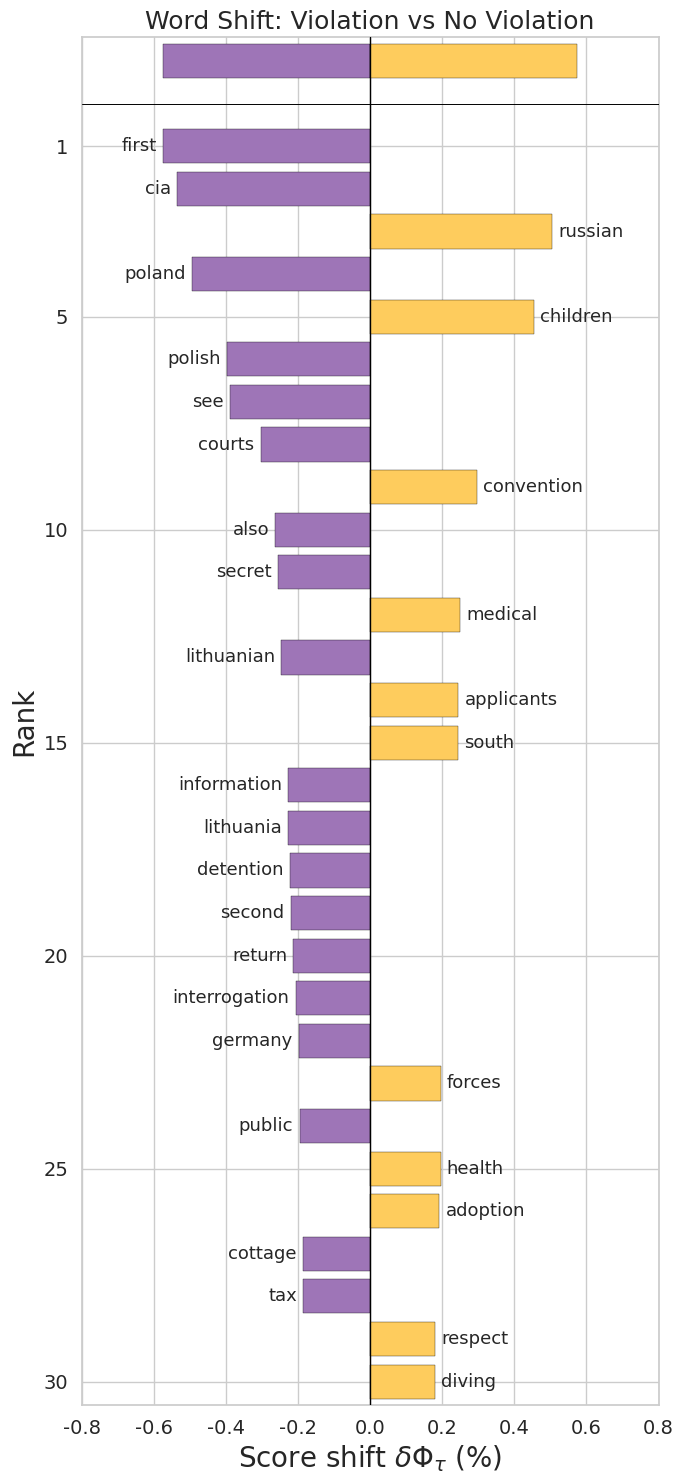

In [ ]:
import nltk
from nltk.corpus import stopwords
import shifterator as sh
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import re # Make sure re is imported
import matplotlib.pyplot as plt # Import matplotlib for plt.show()

# Ensure stopwords are downloaded
nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

# Custom legal stopwords to prevent generic terms from dominating the graph
legal_stopwords = {'court', 'applicant', 'article', 'case', 'law', 'government', 'rights', 'echr', 'state', 'national'}
all_stopwords = stop_words.union(legal_stopwords)

def clean_text_for_shifterator(text):
    """Strips punctuation, converts to lowercase, and removes stopwords."""
    if not isinstance(text, str):
        return []
    text = re.sub(r'[^a-zA-Z\s]', '', text) # Remove punctuation and numbers
    words = text.lower().split()
    return [w for w in words if w not in all_stopwords and len(w) > 2]

# Rebuild frequency dictionaries with updated function
violation_texts = df_filtered_cases[
    df_filtered_cases['outcome_category'] == 'Violation'
]['parsed_full_text'].tolist()

no_violation_texts = df_filtered_cases[
    df_filtered_cases['outcome_category'] == 'No Violation'
]['parsed_full_text'].tolist()

freq_violation_words = []
for text in violation_texts:
    freq_violation_words.extend(clean_text_for_shifterator(text))
freq_violation = Counter(freq_violation_words)

freq_no_violation_words = []
for text in no_violation_texts:
    freq_no_violation_words.extend(clean_text_for_shifterator(text))
freq_no_violation = Counter(freq_no_violation_words)

# Add checks for empty frequency dictionaries or very few words
if not freq_violation or not freq_no_violation:
    print("Warning: One or both frequency dictionaries are empty after cleaning. Cannot generate shift graph.")
elif min(len(freq_violation), len(freq_no_violation)) < 30:
    print(f"Warning: Fewer than 30 unique words after cleaning ({len(freq_violation)} in violation, {len(freq_no_violation)} in no violation). Adjusting top_n.")
    top_n_plot = min(len(freq_violation), len(freq_no_violation), 10) # Plot max 10 if not enough for 30
else:
    top_n_plot = 30

if freq_violation and freq_no_violation: # Only attempt to plot if both dicts are non-empty
    shift = sh.ProportionShift(
        type2freq_1=freq_no_violation,
        type2freq_2=freq_violation
    )
    shift.get_shift_graph(
        top_n=top_n_plot, # Use dynamic top_n
        title='Word Shift: Violation vs No Violation',
        filename='word_shift_full_case.png',
        cumulative_inset=False,
        text_size_inset=False
    )
    plt.show() # Display the plot
else:
    print("Shift graph not generated due to empty frequency dictionaries.")

**Note:**

The word shift graph confirms the vocabulary patterns identified across the preceding analyses. Words contributing disproportionately to violation cases include "**convention**", "**detention**", "**russian**", "**criminal**", "**investigation**", "**eur**", "**damage**", "**russia**", and "**cia**", reinforcing the finding that state security operations and Russian Federation cases dominate the violation class. Notably, "**violation**" and "**damage**" appearing on the violation side further confirms the data leakage concern identified in the Law section analysis, where outcome-consequent language directly signals the verdict.

Words contributing disproportionately to non-violation cases, "**child**", "**children**", "**family**", "**contact**", "**parents**", "**care**", "**interests**", "**father**", "**mother**", "**relationship**", and "**adoption**", reinforcing the finding that cases concerning parental contact, custody arrangements, and child welfare feature prominently among non-violations. Together, the word shift graph provides a concise visual summary of the two dominant thematic clusters characterising each outcome class across the dataset.

###5.4.1 Overview (Full Case)

Cleaning Full Case text and building frequencies... (this may take a moment)


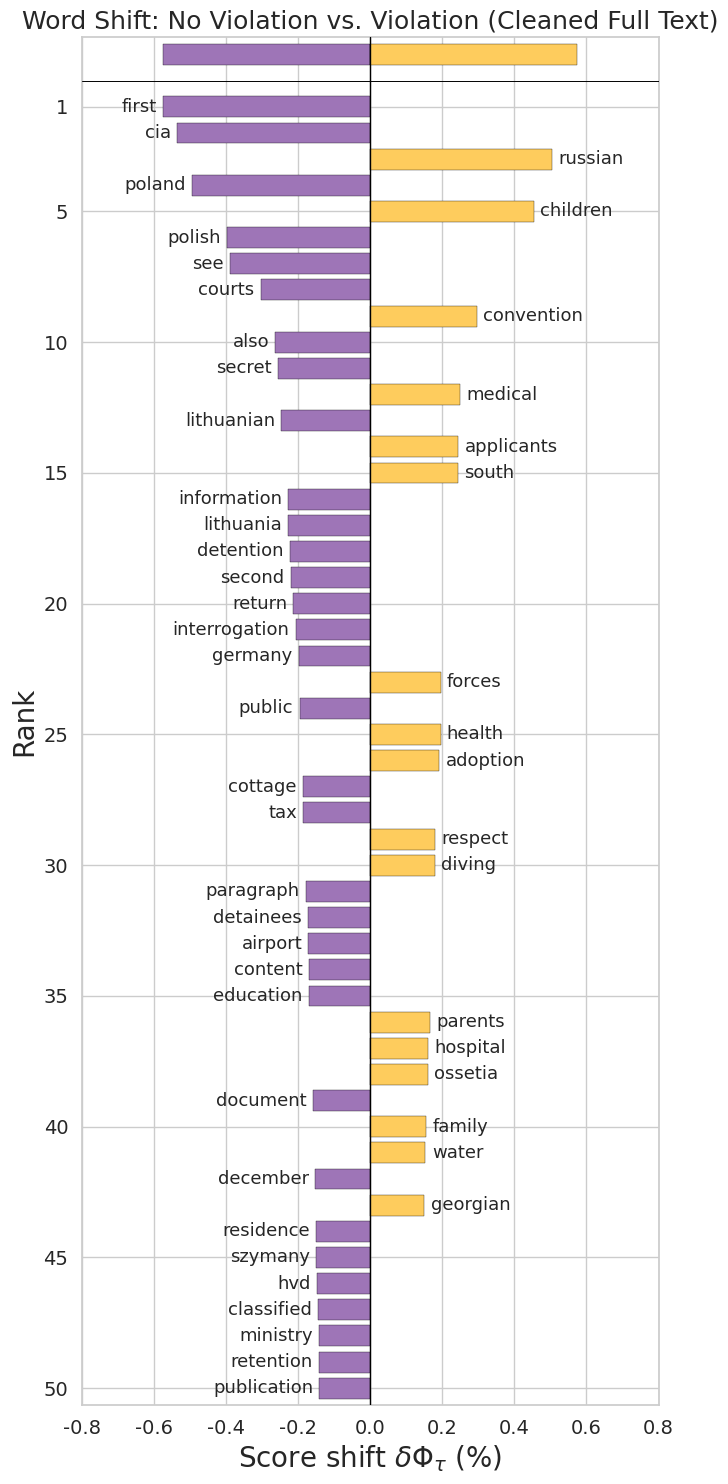

In [ ]:
# Ensure stopwords are downloaded
nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

# Custom legal stopwords to prevent generic terms from dominating the graph
legal_stopwords = {'court', 'applicant', 'article', 'case', 'law', 'government', 'rights', 'echr', 'state', 'national'}
all_stopwords = stop_words.union(legal_stopwords)

def clean_text(text):
    """Strips punctuation, converts to lowercase, and removes stopwords."""
    if not isinstance(text, str):
        return []
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    words = text.lower().split()
    return [w for w in words if w not in all_stopwords and len(w) > 2]

# 1. Apply cleaning to the parsed_full_text
print("Cleaning Full Case text and building frequencies... (this may take a moment)")
violation_full_words = []
df_filtered_cases[df_filtered_cases['outcome_category'] == 'Violation']['parsed_full_text'].apply(
    lambda x: violation_full_words.extend(clean_text(x))
)

no_violation_full_words = []
df_filtered_cases[df_filtered_cases['outcome_category'] == 'No Violation']['parsed_full_text'].apply(
    lambda x: no_violation_full_words.extend(clean_text(x))
)

freq_violation_full = Counter(violation_full_words)
freq_no_violation_full = Counter(no_violation_full_words)

# 2. Initialize the Proportion Shift
proportion_shift_full = sh.ProportionShift(type2freq_1=freq_no_violation_full,
                                           type2freq_2=freq_violation_full)

# 3. Generate the shift graph
# FIX: get_shift_graph returns a single Axes object. Both insets disabled to bypass matplotlib bug.
ax = proportion_shift_full.get_shift_graph(system_names=['No Violation', 'Violation'],
                                           title='Word Shift: No Violation vs. Violation (Cleaned Full Text)',
                                           cumulative_inset=False,
                                           text_size_inset=False)
plt.show()



**Note :**

When analysing across all sections, the violation side combines state security vocabulary with outcome-consequent legal terminology, featuring terms such as "**convention**", "**detention", "police", "damage", "russian"**, "**surveillance**", "**secret", "criminal", "investigation", "prison**", and **"military**". Together these point to cases involving coercive state action, law enforcement, detention, and surveillance operations,followed by legal remedies awarded for the breach. The prominence of the word **"Russian"** is consistent with Russia's disproportionate representation in the violation class, as identified in the respondent state analysis,  and should be interpreted as a dataset artefact rather than a substantive doctrinal signal.

The non-violation side remains remarkably consistent across all sections, dominated by domestic relations vocabulary, **"child", "children", "contact", "family", "parents", "care", "interests", "father", "mother", "adoption", "foster"**, and "**birth"**. This consistency reinforces the observation that the Court frequently defers to domestic authorities in family and child welfare matters, granting a wider margin of appreciation that typically yields non-violation findings. The word shift graph therefore reveals two dominant and thematically distinct Article 8 profiles in the dataset: violation cases centred on state security and coercive action, and non-violation cases centred on family life and child welfare.


###5.4.2 Facts Section

Cleaning Facts text and building frequencies... (this may take a moment)


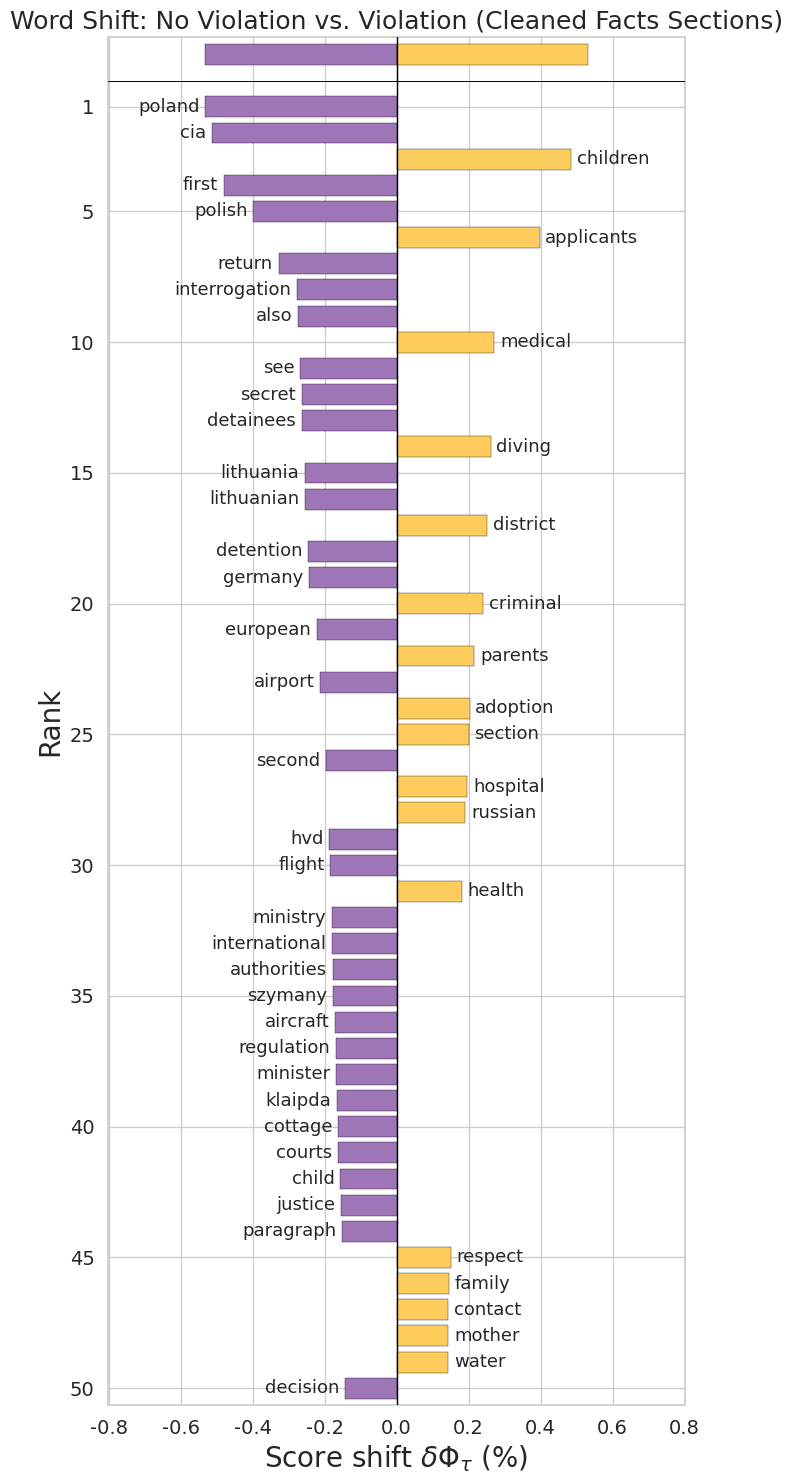

In [ ]:
# Ensure stopwords are downloaded
nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

# Custom legal stopwords to prevent generic terms from dominating the graph
legal_stopwords = {'court', 'applicant', 'article', 'case', 'law', 'government', 'rights', 'echr', 'state', 'national'}
all_stopwords = stop_words.union(legal_stopwords)

def clean_text(text):
    """Strips punctuation, converts to lowercase, and removes stopwords."""
    if not isinstance(text, str):
        return []
    # Remove punctuation and numbers
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # Lowercase and split
    words = text.lower().split()
    # Remove stopwords and ultra-short tokens
    return [w for w in words if w not in all_stopwords and len(w) > 2]

# 1. Apply cleaning to the parsed_facts_text
print("Cleaning Facts text and building frequencies... (this may take a moment)")
violation_facts_words = []
df_filtered_cases[df_filtered_cases['outcome_category'] == 'Violation']['parsed_facts_text'].apply(
    lambda x: violation_facts_words.extend(clean_text(x))
)

no_violation_facts_words = []
df_filtered_cases[df_filtered_cases['outcome_category'] == 'No Violation']['parsed_facts_text'].apply(
    lambda x: no_violation_facts_words.extend(clean_text(x))
)

freq_violation_facts = Counter(violation_facts_words)
freq_no_violation_facts = Counter(no_violation_facts_words)

# 2. Initialize the Proportion Shift
proportion_shift_facts = sh.ProportionShift(type2freq_1=freq_no_violation_facts,
                                            type2freq_2=freq_violation_facts)

# 3. Generate the shift graph
# FIX: get_shift_graph returns a single Axes object, not a tuple. Both insets disabled to bypass matplotlib bug.
ax = proportion_shift_facts.get_shift_graph(system_names=['No Violation', 'Violation'],
                                            title='Word Shift: No Violation vs. Violation (Cleaned Facts Sections)',
                                            cumulative_inset=False,
                                            text_size_inset=False)
plt.show()


**Note :**

In the Facts section, the violation side features terminology associated with coercive state power and law enforcement actions, including "**detention**", "**criminal**", "**police**", "**cia**", "**investigation**", "**prosecutor**", "**secret**", "**military**", "**officers**" and "**prisoners**". Together, these terms point to cases involving physical and procedural interferences, such as extraordinary rendition, criminal investigations, and detention, where the Court is also likely to apply strict scrutiny and is less likely to defer to state discretion.

The non-violation side presents a picture consistent with the full text analysis, dominated by familial and domestic relations vocabulary such as "**child**", "**parents**", "**contact**",  "**children**", **"care", "father", "mother", "foster", "adoption"**, and "**school**". Again, this could be a reflection of the Court's tendency to defer to domestic authorities, in cases involving custody battles, contact orders, and child welfare assessments. In these socially complex domestic arenas, the Court seems to grant a wider margin of appreciation, resulting in non-violation findings where domestic state authorities are deemed better positioned to evaluate the immediate circumstances.



###5.4.3 Law Section

Cleaning text and building frequencies... (this may take a moment)


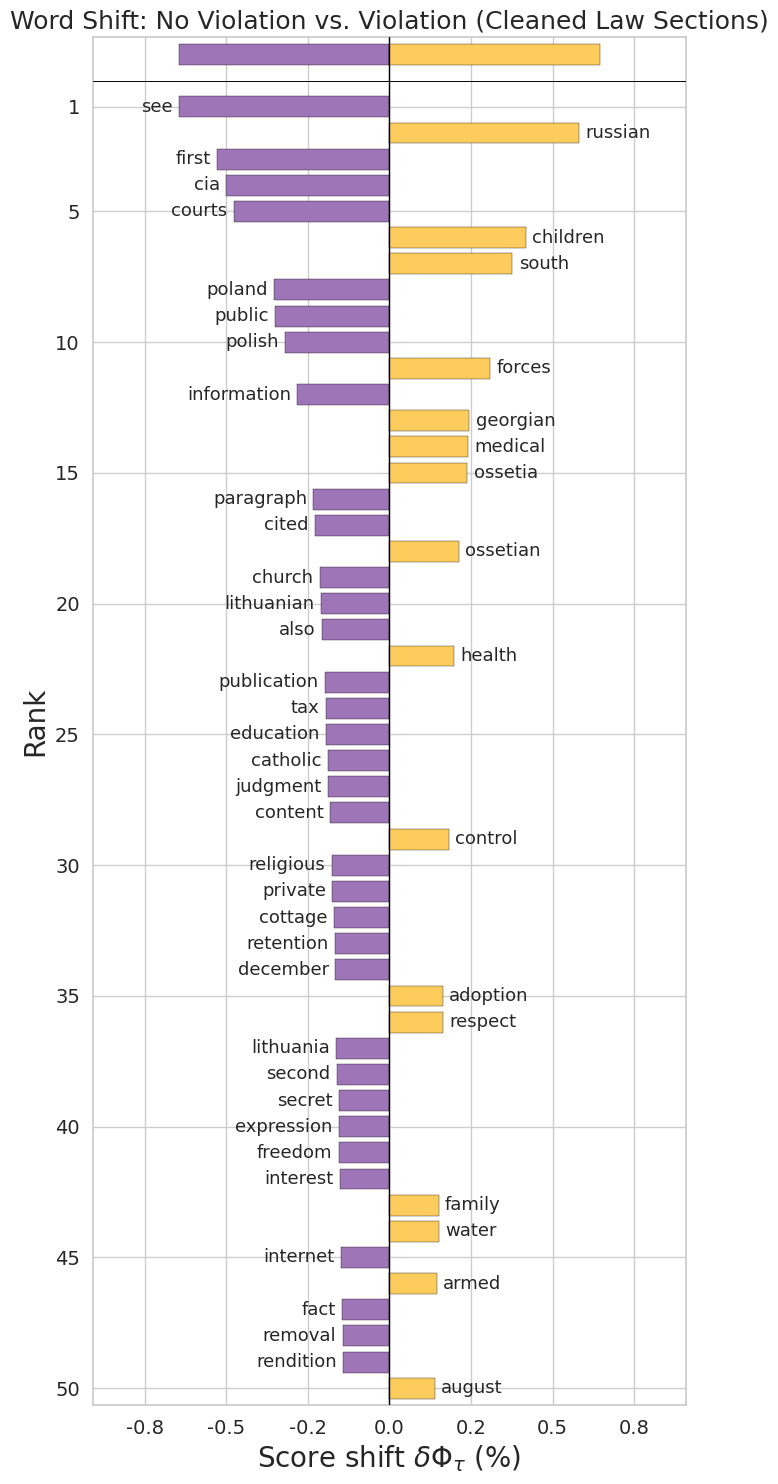

In [ ]:
# CODE CELL: Text Cleaning and Shifterator (Law Section)
import nltk
from nltk.corpus import stopwords
import shifterator as sh
from collections import Counter

# Ensure stopwords are downloaded
nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

# Custom legal stopwords to prevent generic terms from dominating the graph
legal_stopwords = {'court', 'applicant', 'article', 'case', 'law', 'government', 'rights', 'echr', 'state', 'national'}
all_stopwords = stop_words.union(legal_stopwords)

def clean_text(text):
    """Strips punctuation, converts to lowercase, and removes stopwords."""
    if not isinstance(text, str):
        return []
    # Remove punctuation and numbers
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # Lowercase and split
    words = text.lower().split()
    # Remove stopwords and ultra-short tokens
    return [w for w in words if w not in all_stopwords and len(w) > 2]

# Ensure 'parsed_law_text' column exists in df_filtered_cases
# The get_law_text function should be defined in an earlier cell (e.g., Fch9-tfzCLvI)
# If Fch9-tfzCLvI was not run, or df_filtered_cases was reset, this step ensures the column exists.
if 'parsed_law_text' not in df_filtered_cases.columns:
    # Assuming get_law_text is defined globally or in an earlier executed cell
    # If get_law_text itself is missing, that would be a separate error.
    df_filtered_cases['parsed_law_text'] = df_filtered_cases['full_text'].apply(get_law_text)

# 1. Apply cleaning to the parsed_law_text
print("Cleaning text and building frequencies... (this may take a moment)")
violation_words = []
# [cite: 3] Using df_filtered_cases and 'outcome_category' from the group Colab setup

df_filtered_cases[df_filtered_cases['outcome_category'] == 'Violation']['parsed_law_text'].apply(
    lambda x: violation_words.extend(clean_text(x))
)

no_violation_words = []
df_filtered_cases[df_filtered_cases['outcome_category'] == 'No Violation']['parsed_law_text'].apply(
    lambda x: no_violation_words.extend(clean_text(x))
)

freq_violation = Counter(violation_words)
freq_no_violation = Counter(no_violation_words)

# 2. Initialize the Proportion Shift
proportion_shift = sh.ProportionShift(type2freq_1=freq_no_violation,
                                      type2freq_2=freq_violation)

# 3. Generate the shift graph
# FIX: get_shift_graph returns a single Axes object, not a tuple. Both insets disabled to bypass matplotlib bug.
ax = proportion_shift.get_shift_graph(system_names=['No Violation', 'Violation'],
                                      title='Word Shift: No Violation vs. Violation (Cleaned Law Sections)',
                                      cumulative_inset=False,
                                      text_size_inset=False)
plt.show()

 **Note :**

 In the Law section, the violation side is driven heavily by terminology associated with seemingly physical interference and remedial legal action, including "**convention**", "**detention**", "**violation**", "**damage**", "**eur**", "**costs**", "**expenses**", "**nonpecuniary**", and "**incurred**". These terms reflect the just satisfaction assessment that follows a violation finding rather than the reasoning that produced it, and their presence in the Law section risks allowing a classifier to infer the outcome from its consequences.

 The non-violation side presents a strikingly different picture, dominated by domestic welfare and social balancing vocabulary such as "**family**", "**life**", "**child**", "**contact**", "**children**", "**public**", "**interests**", and "**private**", reflecting the Court's tendency to defer to domestic authorities, particularly in family court disputes or when weighing an individual's private life against broader public interests.  This is consistent with the concordance analysis finding that the margin of appreciation is invoked by the Court itself, rather than only argued by the government, in non-violation judgments. In these ethically and socially complex areas, the Court seems to grant a wider margin of appreciation, frequently resulting in non-violation findings.



##5.5. Fighting Words

###5.5.1 Facts Section

In [ ]:
# 1. Create a new DataFrame, df_filtered_importance
# Ensure 'importance' is numeric first, then filter
df_filtered_cases['importance'] = pd.to_numeric(df_filtered_cases['importance'], errors='coerce')

df_filtered_importance = df_filtered_cases[
    (df_filtered_cases['outcome_category'].isin(['Violation', 'No Violation'])) &
    (df_filtered_cases['importance'].isin([1, 2]))
].copy()

# Filter out cases where facts text might be empty after extraction
df_filtered_importance = df_filtered_importance[df_filtered_importance['parsed_facts_text'].str.strip() != ''].copy()

print(f"Filtered cases for Importance 1 or 2, with 'Violation' or 'No Violation' outcomes, and non-empty facts text: {len(df_filtered_importance)} cases.")

# 2. Initialize a CountVectorizer
cv_importance = CountVectorizer(
    ngram_range=(1, 2), # Modified to include unigrams and bigrams
    stop_words='english',
    min_df=5
)
print("CountVectorizer initialized for importance levels 1 & 2 facts section with ngram_range=(1, 2).")

Filtered cases for Importance 1 or 2, with 'Violation' or 'No Violation' outcomes, and non-empty facts text: 18 cases.
CountVectorizer initialized for importance levels 1 & 2 facts section with ngram_range=(1, 2).


**Note :**

The fighting words analysis restricted to importance levels 1 and 2 cases reveals deportation, expulsion and extraordinary rendition vocabulary strongly predicts Violation, while assisted reproduction/IVF vocabulary strongly predicts No Violation. This suggests that for legally significant cases, the subject matter domain is a stronger predictor of outcome than general linguistic features, with potential implications for feature engineering in the modelling stage.

It should be noted that the sample is small (n=135, of which 95 Violation and 40 No Violation) and the large log-odds ratios reflect small sample variance rather than robust statistical evidence. Results should be interpreted as qualitative indicators only.


Top Fighting Words for Violation (Importance 1 & 2):
['sustained', 'care', 'notice', 'long term', 'labour', 'father', 'visits', 'settlement', 'directorate', 'child']

Top Fighting Words for No Violation (Importance 1 & 2):
['secret', 'media', 'ill', 'search', 'territory', 'court justice', 'international law', 'allegedly', '2012', 'existence']


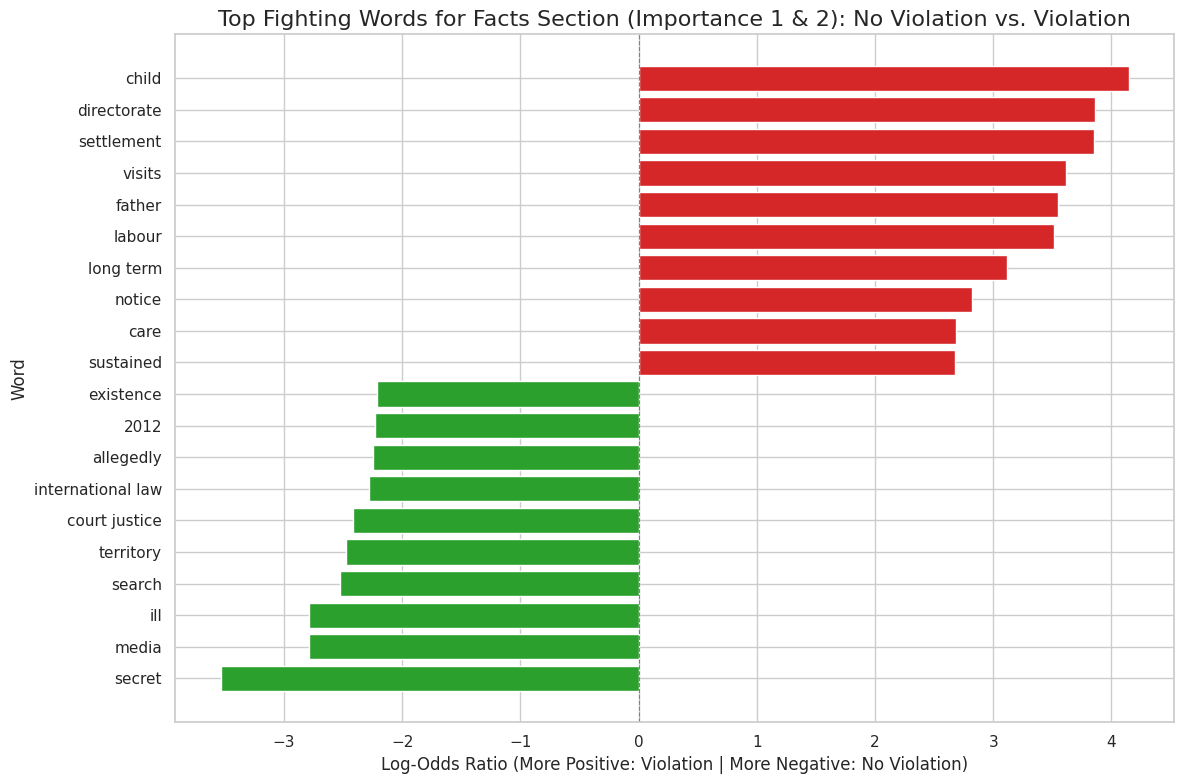

In [ ]:
X_importance = cv_importance.fit_transform(df_filtered_importance['parsed_facts_text'])
words_importance = cv_importance.get_feature_names_out()

# Create two separate count arrays for 'Violation' and 'No Violation' cases
y_importance = (df_filtered_importance['outcome_category'] == 'Violation').to_numpy()

counts_v_importance = np.array(X_importance[y_importance].sum(axis=0)).flatten()
counts_nv_importance = np.array(X_importance[~y_importance].sum(axis=0)).flatten()

# Calculate the simplified log-odds ratio for each word
# Add 1 to avoid division by zero
log_odds_importance = np.log((counts_v_importance + 1) / (counts_v_importance.sum() + 1)) - \
                      np.log((counts_nv_importance + 1) / (counts_nv_importance.sum() + 1))

# Identify top 10 fighting words for each outcome
top_v_indices_importance = log_odds_importance.argsort()[-10:]
print('Top Fighting Words for Violation (Importance 1 & 2):')
print([words_importance[i] for i in top_v_indices_importance])

top_nv_indices_importance = log_odds_importance.argsort()[:10]
print('\nTop Fighting Words for No Violation (Importance 1 & 2):')
print([words_importance[i] for i in top_nv_indices_importance])

# Create DataFrame for plotting
all_top_words_indices_importance = np.concatenate((top_nv_indices_importance, top_v_indices_importance))
all_top_words_importance = [words_importance[i] for i in all_top_words_indices_importance]
all_log_odds_importance = log_odds_importance[all_top_words_indices_importance]

plot_df_importance = pd.DataFrame({
    'word': all_top_words_importance,
    'log_odds': all_log_odds_importance
}).sort_values(by='log_odds', ascending=True).reset_index(drop=True)

# Plot using plt.barh to avoid seaborn FutureWarning with custom colour lists
colors = plot_df_importance['log_odds'].apply(lambda x: '#d62728' if x > 0 else '#2ca02c').tolist()
plt.figure(figsize=(12, 8))
plt.barh(plot_df_importance['word'], plot_df_importance['log_odds'], color=colors)
plt.title('Top Fighting Words for Facts Section (Importance 1 & 2): No Violation vs. Violation', fontsize=16)
plt.xlabel('Log-Odds Ratio (More Positive: Violation | More Negative: No Violation)', fontsize=12)
plt.ylabel('Word', fontsize=12)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

**Note :**

The fighting words analysis identifies terms with the highest log-odds ratio of appearing in one outcome class versus the other, providing a more discriminative view of vocabulary than raw frequency alone.

In the Facts section, the violation side is dominated by terms associated with state security and border control, including **"investigator", "afghanistan", "aircraft", "abu", "border", "expulsion", "aliens", "aliens act", and "flight"**. Together these point to extraordinary rendition, unlawful deportation, and state security operations as the dominant factual context for Article 8 violations.

The non-violation side presents a strikingly different picture, dominated by assisted reproduction and bioethics vocabulary, **"embryos", "embryo", "vitro", "assisted reproduction", "fertilisation", "child relationship", and "reproduction"**. This reflects the Court's tendency to grant states a wide margin of appreciation in ethically sensitive areas of social policy, resulting in non-violation findings across this category of cases.


###5.5.2 Law Section

Filtered cases for Importance 1 or 2, with 'Violation' or 'No Violation' outcomes, and non-empty law text: 18 cases.
CountVectorizer initialized for importance levels 1 & 2 law section with ngram_range=(1, 2).
Top Fighting Words for Violation (Importance 1 & 2, Law Section):
['police', 'maintain', 'children', 'mother', 'father', 'sentence', 'communications', 'parents', 'medical', 'article 14']

Top Fighting Words for No Violation (Importance 1 & 2, Law Section):
['poland', 'expression', 'transfer', 'federal', 'site', 'content', 'value', 'reporting', 'liability', 'examination case']


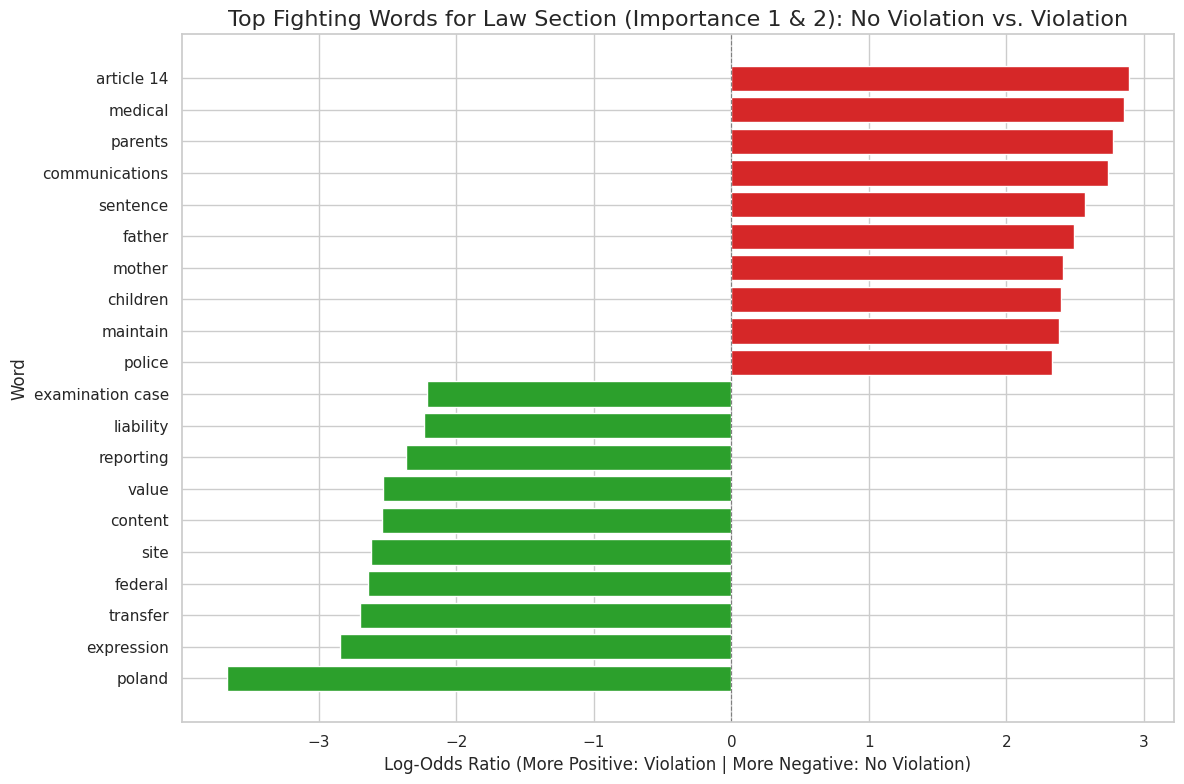

In [ ]:
# Filter out cases where law text might be empty
df_filtered_importance_law = df_filtered_importance[
    df_filtered_importance['parsed_law_text'].str.strip() != ''
].copy()

print(f"Filtered cases for Importance 1 or 2, with 'Violation' or 'No Violation' outcomes, and non-empty law text: {len(df_filtered_importance_law)} cases.")

# Initialize CountVectorizer (same settings as facts section)
cv_importance_law = CountVectorizer(ngram_range=(1, 2), stop_words='english', min_df=5)
print("CountVectorizer initialized for importance levels 1 & 2 law section with ngram_range=(1, 2).")

X_importance_law = cv_importance_law.fit_transform(df_filtered_importance_law['parsed_law_text'])
words_importance_law = cv_importance_law.get_feature_names_out()

# Count arrays for each outcome
y_importance_law = (df_filtered_importance_law['outcome_category'] == 'Violation').to_numpy()
counts_v_importance_law = np.array(X_importance_law[y_importance_law].sum(axis=0)).flatten()
counts_nv_importance_law = np.array(X_importance_law[~y_importance_law].sum(axis=0)).flatten()

# Log-odds ratio
log_odds_importance_law = (
    np.log((counts_v_importance_law + 1) / (counts_v_importance_law.sum() + 1)) -
    np.log((counts_nv_importance_law + 1) / (counts_nv_importance_law.sum() + 1))
)

# Top 10 fighting words for each outcome
top_v_indices_importance_law = log_odds_importance_law.argsort()[-10:]
print('Top Fighting Words for Violation (Importance 1 & 2, Law Section):')
print([words_importance_law[i] for i in top_v_indices_importance_law])

top_nv_indices_importance_law = log_odds_importance_law.argsort()[:10]
print('\nTop Fighting Words for No Violation (Importance 1 & 2, Law Section):')
print([words_importance_law[i] for i in top_nv_indices_importance_law])

# DataFrame for plotting
all_top_words_indices_importance_law = np.concatenate((top_nv_indices_importance_law, top_v_indices_importance_law))
all_top_words_importance_law = [words_importance_law[i] for i in all_top_words_indices_importance_law]
all_log_odds_importance_law = log_odds_importance_law[all_top_words_indices_importance_law]

plot_df_importance_law = pd.DataFrame({
    'word': all_top_words_importance_law,
    'log_odds': all_log_odds_importance_law
}).sort_values(by='log_odds', ascending=True).reset_index(drop=True)

# Plot
colors = plot_df_importance_law['log_odds'].apply(lambda x: '#d62728' if x > 0 else '#2ca02c').tolist()
plt.figure(figsize=(12, 8))
plt.barh(plot_df_importance_law['word'], plot_df_importance_law['log_odds'], color=colors)
plt.title('Top Fighting Words for Law Section (Importance 1 & 2): No Violation vs. Violation', fontsize=16)
plt.xlabel('Log-Odds Ratio (More Positive: Violation | More Negative: No Violation)', fontsize=12)
plt.ylabel('Word', fontsize=12)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

**Note :**

In the Law section, the violation side shows terms such as **"aircraft", "polish", "servicemen", "signals", "detainees", "russian federation", "military", and "sterilisation"**, reinforcing the security and military theme observed in the Facts section while introducing **"sterilisation" and "disability"** as additional violation-associated terms.

The non-violation side shifts somewhat, with terms such as **"child relationship", "embryo", "transsexuals", "medically assisted", "fertilisation", "gps", and "austrian"** featuring prominently, suggesting that cases concerning reproductive technology, legal identity, and surveillance contribute disproportionately to non-violation findings in the Law section.

Facts and Law sections independently confirm the same high-importance case clusters — the deportation/military/surveillance cluster predicting 'Violation' and the IVF/bioethics/gender recognition cluster predicting 'No Violation' appear consistently across both sections, suggesting these are robust legal patterns. The Court's wide margin of appreciation doctrine in sensitive bioethical and national security contexts is reflected directly in the vocabulary of its judgments.

#**7. Conclusion**

Based on our exploratory analysis, we conclude that our research question: 'Can we predict whether an Article 8 case will result in a Violation or No Violation using the linguistic features of the judgment text?' is addressable using supervised classification techniques covered in class.


Our dataset of 1,321 Article 8 cases (2010–2023), comprising 983 Violation and 282 No Violation cases after excluding procedurally terminated cases, provides a sufficient sample size for classification. The outcome variable is clearly defined and extractable from the structured conclusion column. The class imbalance (~78% Violation) will require class weighting or resampling techniques.

The EDA has identified several promising predictive features: the text of the Facts and Law sections, show meaningful vocabulary variation across outcome classes, as demonstrated by the n-gram, scatter plot, fighting words, and word shift analyses. Case importance level and court type correlate strongly with case complexity, and respondent country, which reflects structural patterns in how different states approach Convention rights, though the dominance of Russian cases may reduce generalisability. Initial logistic regression coefficient analysis suggests that distinctive vocabulary does exist between Violation and No Violation cases, supporting the feasibility of a bag-of-words or TF-IDF approach as covered in Lab 6.

The main limitations to acknowledge are class imbalance, structural differences between Committee and Chamber judgments which may require separate modelling, and  the data leakage risk identified in the Law section. These are manageable constraints rather than fundamental obstaclesand a classification model trained on TF-IDF features from the Facts and Law sections is expected to produce meaningful and interpretable predictions.

